# Notebook « comptes rebonds » — jalon 2b (base XGBoost enrichie), version du 05/11/2026

**Pour tout exécuter : importer le fichier, ajouter le jeu de données Kaggle *IBM Transactions for Anti Money Laundering (AML)* (HI-Small), puis *Run All*.**
Les cellules sont dans l'ordre d'exécution. Durée attendue : de l'ordre d'une heure sur Kaggle [Hypothèse, non mesurée pour cette version].

**Ce qui est dedans**
- Cellules 0 à 13 : chargement, variables de graphe (T0 : bootstrap par bloc ; T1 : montants en dollars), modèles A et B — déjà validées, reprises telles quelles.
- Cellules 14a, 14, 14z, 15, 16 : T2 (ratio de passage). La 14 est la cellule réécrite le 04/11 ; la 14z vérifie que tout est prêt.
- **Cellules 17 à 22 : nouvelles.** T3 (éventails multi-durées), T4 (fractionnement), T5 (aller-retour), T6 (montant relatif), puis le bilan et le modèle C.

**Ce qui n'est PAS dedans, exprès**
- Cellules 6, 10, 13b, 13c : diagnostics ou réglages déjà faits, dont les résultats sont dans `journal_decisions.md`.
- Cellules du jalon 1 (ancien découpage par jours) : non comparables à A et B.
- **Aucune évaluation sur le test pour les familles T2 à T6** : le test est touché une seule fois, au point de contrôle 2, après décision.

**Deux retouches de cellules validées**, sans effet sur les calculs : cellule 1 (le chemin du fichier est cherché dans `/kaggle/input` au lieu d'être écrit en dur) ; cellule 14a (une ligne de commentaire d'étiquette en tête).

**Si une cellule s'arrête sur une erreur** : copier le message complet et la sortie de la cellule, ne rien relancer avant d'avoir regardé.


## Environnement

In [1]:
import sys, os, platform, shutil, subprocess
from importlib.metadata import version, PackageNotFoundError

def ver(*noms):
    """Renvoie la version installée d'un paquet en essayant plusieurs orthographes."""
    for n in noms:
        try:
            return version(n)
        except PackageNotFoundError:
            continue
    return "ABSENT"

print("=== Python et système ===")
print("Python      :", sys.version.split()[0])
print("Système     :", platform.platform())
print("CPU (cœurs) :", os.cpu_count())

print("\n=== Paquets ===")
paquets = {
    "pandas": ("pandas",),
    "numpy": ("numpy",),
    "xgboost": ("xgboost",),
    "scikit-learn": ("scikit-learn", "scikit_learn"),
    "torch": ("torch",),
    "torch_geometric": ("torch_geometric", "torch-geometric"),
    "pyg_lib (optionnel)": ("pyg_lib", "pyg-lib"),
    "torch_scatter (opt.)": ("torch_scatter", "torch-scatter"),
    "torch_sparse (opt.)": ("torch_sparse", "torch-sparse"),
}
for nom, variantes in paquets.items():
    print(f"{nom:22s}: {ver(*variantes)}")

print("\n=== Mémoire vive (RAM) ===")
with open("/proc/meminfo") as f:
    info = {l.split(":")[0]: l.split(":")[1].strip() for l in f}
for cle in ("MemTotal", "MemAvailable"):
    ko = int(info[cle].split()[0])
    print(f"{cle:12s}: {ko / 1024**2:.1f} Go")

print("\n=== Disque de travail ===")
total, utilise, libre = shutil.disk_usage("/kaggle/working" if os.path.exists("/kaggle/working") else "/")
print(f"Libre : {libre / 1024**3:.1f} Go sur {total / 1024**3:.1f} Go")

print("\n=== GPU ===")
try:
    import torch
    print("torch.cuda disponible :", torch.cuda.is_available())
    print("CUDA de PyTorch       :", torch.version.cuda)
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f"GPU {i} : {p.name}, {p.total_memory / 1024**3:.1f} Go")
except ImportError:
    print("torch absent")
try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("nvidia-smi introuvable : aucun GPU NVIDIA visible (vérifie Settings → Accelerator)")

print("=== Données montées dans /kaggle/input ===")
if os.path.exists("/kaggle/input"):
    for racine, dossiers, fichiers in os.walk("/kaggle/input"):
        for fi in fichiers:
            chemin = os.path.join(racine, fi)
            print(f"{os.path.getsize(chemin) / 1024**2:10.1f} Mo  {chemin}")
else:
    print("/kaggle/input n'existe pas (pas sur Kaggle ?)")

=== Python et système ===
Python      : 3.13.18
Système     : Linux-6.18.55+-x86_64-with-glibc2.39
CPU (cœurs) : 4

=== Paquets ===
pandas                : 2.3.3
numpy                 : 2.1.3
xgboost               : 3.4.1
scikit-learn          : 1.6.1
torch                 : 2.11.0+cpu
torch_geometric       : ABSENT
pyg_lib (optionnel)   : ABSENT
torch_scatter (opt.)  : ABSENT
torch_sparse (opt.)   : ABSENT

=== Mémoire vive (RAM) ===
MemTotal    : 31.3 Go
MemAvailable: 30.2 Go

=== Disque de travail ===
Libre : 19.5 Go sur 19.5 Go

=== GPU ===
torch.cuda disponible : False
CUDA de PyTorch       : None
nvidia-smi introuvable : aucun GPU NVIDIA visible (vérifie Settings → Accelerator)
=== Données montées dans /kaggle/input ===
     138.3 Mo  /kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Medium_accounts.csv
     620.3 Mo  /kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/LI-Small_Trans.csv
     140.8 Mo  /kaggle/input

## Chargement, variables de graphe, découpage, modèles A et B

In [2]:
# Cellule 1 — versions et chargement (adapter CHEMIN si ton df est déjà chargé)
import pandas as pd, numpy as np, sys
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

import glob
_trouves = sorted(glob.glob("/kaggle/input/**/HI-Small_Trans.csv", recursive=True))   # fonctionne même si le dossier du jeu change
CHEMIN = _trouves[0] if _trouves else "/kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Small_Trans.csv"
print("fichier utilisé :", CHEMIN)
df = pd.read_csv(CHEMIN)

ATTENDU = ["Timestamp","From Bank","Account","To Bank","Account.1","Amount Received",
           "Receiving Currency","Amount Paid","Payment Currency","Payment Format","Is Laundering"]
assert list(df.columns) == ATTENDU, df.columns.tolist()   # [Connaissance] noms des colonnes, vérifiés ici

ts = pd.to_datetime(df["Timestamp"], format="%Y/%m/%d %H:%M")  # échoue si le format diffère
df["t_min"] = ((ts - ts.min()) // pd.Timedelta(minutes=1)).astype("int64")  # minutes depuis le début

# Identifiant de compte = banque + numéro (au cas où un numéro existe dans deux banques)
df["emetteur"] = df["From Bank"].astype(str) + "_" + df["Account"].astype(str)
df["destinataire"] = df["To Bank"].astype(str) + "_" + df["Account.1"].astype(str)
print("comptes (numéro seul):", pd.concat([df["Account"], df["Account.1"]]).nunique(),
      "| comptes (banque+numéro):", pd.concat([df["emetteur"], df["destinataire"]]).nunique())
print("auto-virements (émetteur = destinataire):", (df["emetteur"] == df["destinataire"]).mean())

python 3.13.18 | pandas 2.3.3 | numpy 2.1.3
fichier utilisé : /kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Small_Trans.csv
comptes (numéro seul): 515080 | comptes (banque+numéro): 515088
auto-virements (émetteur = destinataire): 0.11641824255736859


In [3]:
# Cellule 2 (v2) — contreparties distinctes dans [t - fenetre, t], soi-même exclu
def nb_contreparties_distinctes(d, compte, contrepartie, fenetre_min):
    p = d.loc[d[compte] != d[contrepartie], [compte, contrepartie, "t_min"]]   # exclut les auto-virements
    p = p.drop_duplicates().sort_values([compte, contrepartie, "t_min"])
    meme_paire = p[compte].eq(p[compte].shift()) & p[contrepartie].eq(p[contrepartie].shift())
    nouveau = ~meme_paire | (p["t_min"] - p["t_min"].shift() > fenetre_min)
    p["seg"] = nouveau.cumsum()
    seg = p.groupby("seg").agg(cpt=(compte, "first"), debut=("t_min", "min"), fin=("t_min", "max"))
    ev = pd.concat([
        pd.DataFrame({"cpt": seg["cpt"], "t_min": seg["debut"], "delta": 1}),
        pd.DataFrame({"cpt": seg["cpt"], "t_min": seg["fin"] + fenetre_min + 1, "delta": -1}),
    ])
    ev = ev.groupby(["cpt", "t_min"], as_index=False)["delta"].sum().sort_values(["cpt", "t_min"])
    ev["valeur"] = ev.groupby("cpt")["delta"].cumsum()
    ev = ev.sort_values("t_min")
    q = d[[compte, "t_min"]].rename(columns={compte: "cpt"}).reset_index().sort_values("t_min")
    r = pd.merge_asof(q, ev[["cpt", "t_min", "valeur"]], on="t_min", by="cpt",
                      direction="backward", allow_exact_matches=True)
    # NaN = aucun virement vers un autre compte avant t → 0
    return r.set_index("index")["valeur"].reindex(d.index).fillna(0).astype("int64")

# Test jouet : bords de fenêtre, simultanéité, auto-virement (A→A)
jouet = pd.DataFrame({"emetteur": ["A"]*7, "destinataire": ["B","C","B","D","E","A","B"],
                      "t_min": [0, 0, 1440, 1441, 1441, 1441, 3000]})
obtenu = nb_contreparties_distinctes(jouet, "emetteur", "destinataire", 1440).tolist()
print("jouet:", obtenu)
assert obtenu == [2, 2, 2, 3, 3, 3, 1], obtenu

jouet: [2, 2, 2, 3, 3, 3, 1]


In [4]:
# Cellule 3 (v2) — calcul réel + contrôles
FENETRE = 24 * 60   # [Hypothèse] 24 h
df["eventail_sortant_24h"] = nb_contreparties_distinctes(df, "emetteur", "destinataire", FENETRE)
v = df["eventail_sortant_24h"]
auto = df["emetteur"] == df["destinataire"]
assert v.notna().all() and (v >= 0).all()
assert (v[~auto] >= 1).all()   # un virement vers autrui se compte lui-même

# Force brute sur 300 transactions au hasard (même règle : soi-même exclu)
rng = np.random.default_rng(42)
groupes = df.groupby("emetteur").indices
ecarts = 0
for i in rng.choice(len(df), 300, replace=False):
    s, t = df["emetteur"].iat[i], df["t_min"].iat[i]
    g = df.iloc[groupes[s]]
    m = (g["t_min"] <= t) & (g["t_min"] >= t - FENETRE) & (g["destinataire"] != s)
    ecarts += int(g.loc[m, "destinataire"].nunique() != v.iat[i])
print("écarts force brute / 300 :", ecarts)

# Description (pas un score)
FIN_SANS_QUEUE = None   # date de fin retenue au jalon 1, ex. "2022-09-10 23:59"
vues = {"avec queue": df}
if FIN_SANS_QUEUE:
    vues["sans queue"] = df[ts <= pd.Timestamp(FIN_SANS_QUEUE)]
for nom, d in vues.items():
    print(f"\n{nom} ({len(d):,} lignes)")
    print(d.groupby("Is Laundering")["eventail_sortant_24h"].describe(percentiles=[.5, .9, .99]))

écarts force brute / 300 : 0

avec queue (5,078,345 lignes)
                   count        mean          std  min  50%    90%     99%  \
Is Laundering                                                                
0              5073168.0  365.633867  1539.071761  0.0  2.0    8.0  8748.0   
1                 5177.0  519.989183  1812.576498  0.0  1.0  619.8  9072.8   

                   max  
Is Laundering           
0              12540.0  
1              12207.0  


In [5]:
# Cellule 4 — éventail entrant + contrôles
df["eventail_entrant_24h"] = nb_contreparties_distinctes(df, "destinataire", "emetteur", FENETRE)
w = df["eventail_entrant_24h"]
assert w.notna().all() and (w >= 0).all()
assert (w[~auto] >= 1).all()

# Force brute sur 300 transactions au hasard
rng = np.random.default_rng(43)
groupes_d = df.groupby("destinataire").indices
ecarts = 0
for i in rng.choice(len(df), 300, replace=False):
    r, t = df["destinataire"].iat[i], df["t_min"].iat[i]
    g = df.iloc[groupes_d[r]]
    m = (g["t_min"] <= t) & (g["t_min"] >= t - FENETRE) & (g["emetteur"] != r)
    ecarts += int(g.loc[m, "emetteur"].nunique() != w.iat[i])
print("écarts force brute / 300 :", ecarts)

for nom, d in vues.items():
    print(f"\n{nom} ({len(d):,} lignes)")
    print(d.groupby("Is Laundering")["eventail_entrant_24h"].describe(percentiles=[.5, .9, .99]))

# Taille des « plaques tournantes » (comptes à très grand éventail)
print("\németteurs avec éventail sortant max > 1000 :",
      int((df.groupby("emetteur")["eventail_sortant_24h"].max() > 1000).sum()))
print("destinataires avec éventail entrant max > 1000 :",
      int((df.groupby("destinataire")["eventail_entrant_24h"].max() > 1000).sum()))

écarts force brute / 300 : 0

avec queue (5,078,345 lignes)
                   count      mean       std  min  50%  90%    99%    max
Is Laundering                                                            
0              5073168.0  1.590525  5.660159  0.0  1.0  2.0   6.00  539.0
1                 5177.0  2.499324  3.426707  0.0  2.0  5.0  14.24   67.0

émetteurs avec éventail sortant max > 1000 : 9
destinataires avec éventail entrant max > 1000 : 0


In [6]:
# Cellule 5 — délai (minutes) entre la dernière réception du compte émetteur et cet envoi
def delai_depuis_derniere_reception(d):
    auto_d = d["emetteur"] == d["destinataire"]
    recu = (d.loc[~auto_d, ["destinataire", "t_min"]]
              .rename(columns={"destinataire": "cpt", "t_min": "t_recu"})
              .drop_duplicates().sort_values("t_recu"))
    q = (d[["emetteur", "t_min"]].rename(columns={"emetteur": "cpt"})
           .reset_index().sort_values("t_min"))
    r = pd.merge_asof(q, recu, left_on="t_min", right_on="t_recu", by="cpt",
                      direction="backward", allow_exact_matches=True)
    return pd.Series((r["t_min"] - r["t_recu"]).to_numpy(), index=r["index"]).reindex(d.index)

# Test jouet : X→A@10, A→B@5, A→B@10, A→A@20 (auto-virement), A→C@30
jouet = pd.DataFrame({"emetteur": ["X","A","A","A","A"], "destinataire": ["A","B","B","A","C"],
                      "t_min": [10, 5, 10, 20, 30]})
obtenu = delai_depuis_derniere_reception(jouet).tolist()
print("jouet:", obtenu)
assert np.allclose(obtenu, [np.nan, np.nan, 0, 10, 20], equal_nan=True), obtenu

df["delai_reception_envoi_min"] = delai_depuis_derniere_reception(df)
x = df["delai_reception_envoi_min"]
assert (x.dropna() >= 0).all()

# Force brute sur 300 transactions au hasard
rng = np.random.default_rng(44)
ecarts = 0
for i in rng.choice(len(df), 300, replace=False):
    s, t = df["emetteur"].iat[i], df["t_min"].iat[i]
    if s in groupes_d:
        g = df.iloc[groupes_d[s]]
        tr = g.loc[(g["t_min"] <= t) & (g["emetteur"] != s), "t_min"]
        attendu = t - tr.max() if len(tr) else np.nan
    else:
        attendu = np.nan
    obtenu_i = x.iat[i]
    ecarts += int(not ((np.isnan(attendu) and np.isnan(obtenu_i)) or attendu == obtenu_i))
print("écarts force brute / 300 :", ecarts)

for nom, d in vues.items():
    print(f"\n{nom} ({len(d):,} lignes)")
    print("part de valeurs absentes :", d.groupby("Is Laundering")["delai_reception_envoi_min"]
          .apply(lambda s: s.isna().mean()).to_dict())
    print(d.groupby("Is Laundering")["delai_reception_envoi_min"].describe(percentiles=[.1, .5, .9]))

jouet: [nan, nan, 0.0, 10.0, 20.0]
écarts force brute / 300 : 0

avec queue (5,078,345 lignes)
part de valeurs absentes : {0: 0.2415742983476991, 1: 0.19876376279698668}
                   count         mean          std  min   10%     50%     90%  \
Is Laundering                                                                   
0              3847621.0  1884.529441  2734.444650  0.0  72.0   773.0  6235.0   
1                 4148.0  2142.239634  2634.312336  0.0  90.0  1085.0  5901.5   

                   max  
Is Laundering           
0              18417.0  
1              18417.0  


In [7]:
# Cellule 7 — découpage 60/20/20 par horodatage (comme Egressy et al., annexe E.1)
def decoupage_temporel(t_min, part_train=0.6, part_val=0.8):
    t = np.asarray(t_min)
    s = np.sort(t, kind="stable")
    n = len(s)
    t1, t2 = s[int(part_train * n)], s[int(part_val * n)]
    ensemble = np.where(t < t1, "train", np.where(t < t2, "val", "test"))
    return ensemble, t1, t2

# Test jouet calculé à la main : trié = [0,0,1,2,3,4,5,6,7,8] → t1 = s[6] = 5, t2 = s[8] = 7
e, t1_j, t2_j = decoupage_temporel([8, 0, 1, 2, 3, 4, 5, 6, 7, 0])
print("jouet:", e.tolist(), t1_j, t2_j)
assert (t1_j, t2_j) == (5, 7)
assert e.tolist() == ["test","train","train","train","train","train","val","val","test","train"]

# Découpage réel
df["ensemble"], T1, T2 = decoupage_temporel(df["t_min"])
FIN_SANS_QUEUE = pd.Timestamp("2022-09-10 23:59")   # proposé, à confirmer
df["dans_queue"] = ts > FIN_SANS_QUEUE

# Contrôles anti-fuite : les ensembles ne se chevauchent pas dans le temps
g = df.groupby("ensemble")["t_min"].agg(["min", "max"])
assert g.loc["train", "max"] < g.loc["val", "min"] and g.loc["val", "max"] < g.loc["test", "min"]
assert not df.loc[df["ensemble"] != "test", "dans_queue"].any(), "la queue doit être entièrement dans le test"

print("\nt1 =", ts.min() + pd.Timedelta(minutes=int(T1)), "| t2 =", ts.min() + pd.Timedelta(minutes=int(T2)))
resume = df.groupby("ensemble").agg(
    transactions=("Is Laundering", "size"), illicites=("Is Laundering", "sum"),
    debut=("Timestamp", "min"), fin=("Timestamp", "max"))
resume["part_transactions"] = (resume["transactions"] / len(df)).round(4)
print(resume.loc[["train", "val", "test"]].to_string())

test = df[df["ensemble"] == "test"]
print("\ntest avec queue :", len(test), "transactions,", int(test["Is Laundering"].sum()), "illicites")
print("test sans queue :", int((~test["dans_queue"]).sum()), "transactions,",
      int(test.loc[~test["dans_queue"], "Is Laundering"].sum()), "illicites")
print("jour 0 dans l'entraînement uniquement :", set(df.loc[df["t_min"] < 1440, "ensemble"]))

jouet: ['test', 'train', 'train', 'train', 'train', 'train', 'val', 'val', 'test', 'train'] 5 7

t1 = 2022-09-06 13:36:00 | t2 = 2022-09-08 16:12:00
          transactions  illicites             debut               fin  part_transactions
ensemble                                                                                
train          3046861       2297  2022/09/01 00:00  2022/09/06 13:35                0.6
val            1015602       1082  2022/09/06 13:36  2022/09/08 16:11                0.2
test           1015882       1798  2022/09/08 16:12  2022/09/18 16:18                0.2

test avec queue : 1015882 transactions, 1798 illicites
test sans queue : 1014774 transactions, 1143 illicites
jour 0 dans l'entraînement uniquement : {'train'}


In [8]:
# Cellule 8 — fonctions de mesure, testées sur des exemples calculés à la main
import xgboost as xgb, sklearn
from sklearn.metrics import average_precision_score, f1_score
print("xgboost", xgb.__version__, "| scikit-learn", sklearn.__version__)

def f1_au_seuil(y, p, seuil):
    """F1 de la classe illicite si on alerte quand le score >= seuil."""
    y = np.asarray(y).astype(int); pred = (np.asarray(p) >= seuil).astype(int)
    vp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    return 0.0 if vp == 0 else 2 * vp / (2 * vp + fp + fn)

def meilleur_seuil(y, p):
    """Seuil qui maximise le F1 (à utiliser UNIQUEMENT sur la validation). Les ex-aequo ne sont jamais coupés."""
    y = np.asarray(y).astype(int); p = np.asarray(p)
    ordre = np.argsort(-p, kind="stable"); ps, ys = p[ordre], y[ordre]
    vp = np.cumsum(ys); k = np.arange(1, len(ys) + 1)
    fin_de_groupe = np.r_[ps[1:] != ps[:-1], True]
    f1 = 2 * vp / (k + ys.sum())
    i = int(np.argmax(np.where(fin_de_groupe, f1, -1)))
    return float(ps[i]), float(f1[i])

def rappel_budget(y, p, budget=1000):
    """Part des illicites trouvés si l'analyste ne regarde que les `budget` alertes les mieux classées."""
    y = np.asarray(y).astype(int); top = np.argsort(-np.asarray(p), kind="stable")[:budget]
    return y[top].sum() / y.sum()

# Tests jouets (calculés à la main)
yj, pj = [1, 0, 1, 0, 0], [0.9, 0.8, 0.1, 0.7, 0.2]
assert abs(f1_au_seuil(yj, pj, 0.5) - 0.4) < 1e-12                    # VP=1, FP=2, FN=1 → 2/5
assert abs(f1_au_seuil(yj, pj, 0.5) - f1_score(yj, [int(x >= 0.5) for x in pj])) < 1e-12
s, f = meilleur_seuil(yj, pj); assert s == 0.9 and abs(f - 2/3) < 1e-12  # VP=1, FP=0, FN=1 → 2/3
assert rappel_budget(yj, pj, 2) == 0.5                                  # top 2 = 0,9 (illicite) et 0,8
s, f = meilleur_seuil([1, 1, 0, 0], [0.6, 0.6, 0.6, 0.1]); assert s == 0.6 and abs(f - 0.8) < 1e-12  # ex-aequo
print("tests jouets OK")

xgboost 3.4.1 | scikit-learn 1.6.1
tests jouets OK


In [9]:
# Cellule 9 — XGBoost : modèle A (brut) et modèle B (brut + graphe)
import time
X = pd.DataFrame(index=df.index)
X["montant_paye_log"] = np.log1p(df["Amount Paid"])
X["montant_recu_log"] = np.log1p(df["Amount Received"])
for src, nom in [("Payment Currency", "devise_payee"), ("Receiving Currency", "devise_recue"),
                 ("Payment Format", "format_paiement")]:
    X[nom] = df[src].astype("category")      # liste des valeurs possibles, aucune étiquette
X["meme_devise"] = (df["Payment Currency"] == df["Receiving Currency"]).astype(int)
X["auto_virement"] = (df["emetteur"] == df["destinataire"]).astype(int)
X["heure"] = ts.dt.hour
VAR_A = list(X.columns)
VAR_GRAPHE = ["eventail_sortant_24h", "eventail_entrant_24h", "delai_reception_envoi_min"]
X[VAR_GRAPHE] = df[VAR_GRAPHE]
VAR_B = VAR_A + VAR_GRAPHE
assert "Is Laundering" not in X.columns

y = df["Is Laundering"].astype(int)
m = {e: (df["ensemble"] == e).to_numpy() for e in ["train", "val", "test"]}
sans_queue = m["test"] & ~df["dans_queue"].to_numpy()
poids = (y[m["train"]] == 0).sum() / (y[m["train"]] == 1).sum()   # calculé sur l'entraînement seul
print("scale_pos_weight =", round(poids, 1))

resultats = []
for nom, variables in [("A_brut", VAR_A), ("B_brut+graphe", VAR_B)]:
    modele = xgb.XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=6, tree_method="hist",
        enable_categorical=True, scale_pos_weight=poids, eval_metric="aucpr",
        early_stopping_rounds=50, random_state=42, n_jobs=-1)
    debut = time.time()
    modele.fit(X.loc[m["train"], variables], y[m["train"]],
               eval_set=[(X.loc[m["val"], variables], y[m["val"]])], verbose=200)
    p_val = modele.predict_proba(X.loc[m["val"], variables])[:, 1]
    seuil_val, f1_val = meilleur_seuil(y[m["val"]], p_val)       # choisi sur la validation SEULEMENT
    p_test = modele.predict_proba(X.loc[m["test"], variables])[:, 1]
    p_test = pd.Series(p_test, index=X.index[m["test"]])
    for vue, masque in [("avec queue", m["test"]), ("sans queue", sans_queue)]:
        yt, pt = y[masque], p_test[X.index[masque]]
        resultats.append({"modele": nom, "test": vue, "arbres": modele.best_iteration + 1,
                          "F1@0.5": f1_au_seuil(yt, pt, 0.5),
                          "seuil_val": seuil_val, "F1@seuil_val": f1_au_seuil(yt, pt, seuil_val),
                          "PR-AUC": average_precision_score(yt, pt),
                          "rappel@1000": rappel_budget(yt, pt, 1000),
                          "minutes": round((time.time() - debut) / 60, 1)})
    modele.save_model(f"xgb_{nom}.json")        # JSON obligatoire avec les catégories

print(pd.DataFrame(resultats).round(4).to_string(index=False))

scale_pos_weight = 1325.5
[0]	validation_0-aucpr:0.01613
[145]	validation_0-aucpr:0.05591
[0]	validation_0-aucpr:0.01633
[129]	validation_0-aucpr:0.08444
       modele       test  arbres  F1@0.5  seuil_val  F1@seuil_val  PR-AUC  rappel@1000  minutes
       A_brut avec queue      96  0.0363     0.9689        0.2075  0.1121       0.1224      0.6
       A_brut sans queue      96  0.0223     0.9689        0.1379  0.0570       0.1102      0.6
B_brut+graphe avec queue      80  0.0234     0.9610        0.1741  0.1256       0.1224      0.8
B_brut+graphe sans queue      80  0.0148     0.9610        0.1421  0.0703       0.1312      0.8


In [10]:
# Cellule 11 — modèles retenus (A : spw=10, B : spw=1), évaluation finale sur le test
def ecart_bootstrap(y, pa, pb, sa, sb, n=200, graine=0):
    """Écart B − A (PR-AUC et F1 au seuil de validation) sur 200 tirages appariés du test."""
    y, pa, pb = np.asarray(y).astype(int), np.asarray(pa), np.asarray(pb)
    rng = np.random.default_rng(graine); d_ap, d_f1 = [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        d_ap.append(average_precision_score(y[i], pb[i]) - average_precision_score(y[i], pa[i]))
        d_f1.append(f1_au_seuil(y[i], pb[i], sb) - f1_au_seuil(y[i], pa[i], sa))
    q = lambda v: (round(float(np.mean(v)), 4), round(float(np.percentile(v, 2.5)), 4),
                   round(float(np.percentile(v, 97.5)), 4))
    return q(d_ap), q(d_f1)

# Test jouet : deux modèles identiques → écart exactement 0
rj = np.random.default_rng(1); yj = (rj.random(2000) < 0.05).astype(int); pj = rj.random(2000)
assert ecart_bootstrap(yj, pj, pj, 0.5, 0.5, n=20) == ((0.0, 0.0, 0.0), (0.0, 0.0, 0.0))

CHOIX = {"A_brut": (VAR_A, 10), "B_brut+graphe": (VAR_B, 1)}   # décidé en cellule 10
proba, seuils, lignes = {}, {}, []
for nom, (variables, spw) in CHOIX.items():
    mdl = xgb.XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=6, tree_method="hist",
        enable_categorical=True, scale_pos_weight=spw, eval_metric="aucpr",
        early_stopping_rounds=50, random_state=42, n_jobs=-1)
    mdl.fit(X.loc[m["train"], variables], y[m["train"]],
            eval_set=[(X.loc[m["val"], variables], y[m["val"]])], verbose=False)
    seuils[nom], _ = meilleur_seuil(y[m["val"]], mdl.predict_proba(X.loc[m["val"], variables])[:, 1])
    proba[nom] = pd.Series(mdl.predict_proba(X.loc[m["test"], variables])[:, 1], index=X.index[m["test"]])
    mdl.save_model(f"xgb_{nom}_final.json")
    for vue, masque in [("avec queue", m["test"]), ("sans queue", sans_queue)]:
        yt, pt = y[masque], proba[nom][X.index[masque]]
        lignes.append({"modele": nom, "spw": spw, "test": vue, "arbres": mdl.best_iteration + 1,
                       "seuil_val": round(seuils[nom], 4), "F1@seuil_val": f1_au_seuil(yt, pt, seuils[nom]),
                       "F1@0.5": f1_au_seuil(yt, pt, 0.5), "PR-AUC": average_precision_score(yt, pt),
                       "rappel@1000": rappel_budget(yt, pt, 1000)})
print(pd.DataFrame(lignes).round(4).to_string(index=False))

for vue, masque in [("avec queue", m["test"]), ("sans queue", sans_queue)]:
    idx = X.index[masque]
    ap, f1 = ecart_bootstrap(y[masque], proba["A_brut"][idx], proba["B_brut+graphe"][idx],
                             seuils["A_brut"], seuils["B_brut+graphe"])
    print(f"\nB − A ({vue}) : PR-AUC moyenne {ap[0]} [IC95 {ap[1]} ; {ap[2]}] | "
          f"F1@seuil_val moyenne {f1[0]} [IC95 {f1[1]} ; {f1[2]}]")

       modele  spw       test  arbres  seuil_val  F1@seuil_val  F1@0.5  PR-AUC  rappel@1000
       A_brut   10 avec queue     254     0.3347        0.2087  0.0788  0.1316       0.1479
       A_brut   10 sans queue     254     0.3347        0.1391  0.0593  0.0674       0.1295
B_brut+graphe    1 avec queue     169     0.0666        0.2329  0.0055  0.1756       0.1785
B_brut+graphe    1 sans queue     169     0.0666        0.1722  0.0070  0.0990       0.1627

B − A (avec queue) : PR-AUC moyenne 0.0442 [IC95 0.027 ; 0.0584] | F1@seuil_val moyenne 0.0237 [IC95 0.0032 ; 0.045]

B − A (sans queue) : PR-AUC moyenne 0.0313 [IC95 0.0183 ; 0.0454] | F1@seuil_val moyenne 0.0328 [IC95 0.0119 ; 0.0545]


In [11]:
# Cellule 12 — T0 : bootstrap par bloc (compte émetteur), écart B − A
def preparer_blocs(groupes):
    g = np.asarray(groupes); ordre = np.argsort(g, kind="stable")
    _, debuts, tailles = np.unique(g[ordre], return_index=True, return_counts=True)
    return ordre, debuts, tailles

def indices_bloc(ordre, debuts, tailles, choix):
    """Toutes les lignes des blocs tirés (un bloc tiré deux fois apparaît deux fois)."""
    c = tailles[choix]; s = debuts[choix]
    decal = np.repeat(s - np.r_[0, np.cumsum(c)[:-1]], c)
    return ordre[decal + np.arange(c.sum())]

# Tests jouets calculés à la main
o, d, t = preparer_blocs(["A", "B", "A"])                  # A = lignes 0 et 2, B = ligne 1
assert indices_bloc(o, d, t, np.array([0, 0, 1])).tolist() == [0, 2, 0, 2, 1]
assert indices_bloc(o, d, t, np.array([1, 0])).tolist() == [1, 0, 2]

def ecart_bootstrap_bloc(y, pa, pb, sa, sb, groupes, n=200, graine=0):
    y, pa, pb = np.asarray(y).astype(int), np.asarray(pa), np.asarray(pb)
    o, d, t = preparer_blocs(groupes); rng = np.random.default_rng(graine); d_ap, d_f1 = [], []
    for _ in range(n):
        i = indices_bloc(o, d, t, rng.integers(0, len(t), len(t)))
        if y[i].sum() == 0: continue
        d_ap.append(average_precision_score(y[i], pb[i]) - average_precision_score(y[i], pa[i]))
        d_f1.append(f1_au_seuil(y[i], pb[i], sb) - f1_au_seuil(y[i], pa[i], sa))
    q = lambda v: (round(float(np.mean(v)), 4), round(float(np.percentile(v, 2.5)), 4),
                   round(float(np.percentile(v, 97.5)), 4))
    return q(d_ap), q(d_f1), len(d_ap)

rj = np.random.default_rng(1); yj = (rj.random(3000) < 0.05).astype(int); pj = rj.random(3000)
gj = rj.integers(0, 300, 3000)
assert ecart_bootstrap_bloc(yj, pj, pj, 0.5, 0.5, gj, n=20)[:2] == ((0.0, 0.0, 0.0), (0.0, 0.0, 0.0))
print("tests jouets OK")

for vue, masque in [("avec queue", m["test"]), ("sans queue", sans_queue)]:
    idx = X.index[masque]
    ap, f1, nb = ecart_bootstrap_bloc(y[masque], proba["A_brut"][idx], proba["B_brut+graphe"][idx],
                                      seuils["A_brut"], seuils["B_brut+graphe"], df.loc[idx, "emetteur"])
    print(f"B − A ({vue}, blocs = émetteurs, {nb} tirages) : PR-AUC {ap[0]} [IC95 {ap[1]} ; {ap[2]}] | "
          f"F1@seuil_val {f1[0]} [IC95 {f1[1]} ; {f1[2]}]")

tests jouets OK
B − A (avec queue, blocs = émetteurs, 200 tirages) : PR-AUC 0.0437 [IC95 0.0252 ; 0.0643] | F1@seuil_val 0.024 [IC95 -0.0003 ; 0.0458]
B − A (sans queue, blocs = émetteurs, 200 tirages) : PR-AUC 0.0316 [IC95 0.0174 ; 0.0485] | F1@seuil_val 0.0341 [IC95 0.0142 ; 0.0567]


## T1 — montants en dollars

In [12]:
# Cellule 13 — T1 : taux de change vers le dollar, estimés sur l'ENTRAÎNEMENT seulement
devises = sorted(set(df["Payment Currency"]) | set(df["Receiving Currency"]))
print("devises :", devises)
USD = "US Dollar"
assert USD in devises, "nom exact du dollar à corriger d'après la liste ci-dessus"

tr = df[m["train"] & (df["Amount Paid"] > 0) & (df["Amount Received"] > 0)]
vers = tr[(tr["Receiving Currency"] == USD) & (tr["Payment Currency"] != USD)]
depuis = tr[(tr["Payment Currency"] == USD) & (tr["Receiving Currency"] != USD)]
taux = (vers["Amount Received"] / vers["Amount Paid"]).groupby(vers["Payment Currency"]).median()
inverse = (depuis["Amount Paid"] / depuis["Amount Received"]).groupby(depuis["Receiving Currency"]).median()
taux = taux.combine_first(inverse); taux[USD] = 1.0
print("\ndevises sans taux :", sorted(set(devises) - set(taux.index)))
print("\ntaux vers le dollar (1 unité = … $) et nombre de virements utilisés :")
print(pd.DataFrame({"taux": taux, "n_vers_usd": vers["Payment Currency"].value_counts()}).to_string())

df["montant_paye_usd"] = df["Amount Paid"] * df["Payment Currency"].map(taux)
df["montant_recu_usd"] = df["Amount Received"] * df["Receiving Currency"].map(taux)

# Contrôle de cohérence : sur les virements AVEC change, payé converti ≈ reçu converti
change = (df["Payment Currency"] != df["Receiving Currency"]) & (df["Amount Paid"] > 0)
ecart = (df.loc[change, "montant_recu_usd"] / df.loc[change, "montant_paye_usd"] - 1).abs()
for e in ["train", "val", "test"]:
    s = ecart[m[e][change.to_numpy()]]
    print(f"{e} : écart relatif médian {s.median():.4f} | P99 {s.quantile(.99):.4f} | n = {len(s):,}")

devises : ['Australian Dollar', 'Bitcoin', 'Brazil Real', 'Canadian Dollar', 'Euro', 'Mexican Peso', 'Ruble', 'Rupee', 'Saudi Riyal', 'Shekel', 'Swiss Franc', 'UK Pound', 'US Dollar', 'Yen', 'Yuan']

devises sans taux : []

taux vers le dollar (1 unité = … $) et nombre de virements utilisés :
                           taux  n_vers_usd
Payment Currency                           
Australian Dollar      0.707814        79.0
Bitcoin            11881.503549         8.0
Brazil Real            0.177101        44.0
Canadian Dollar        0.757978       318.0
Euro                   1.171783      6059.0
Mexican Peso           0.047297       162.0
Ruble                  0.012853        88.0
Rupee                  0.013616       433.0
Saudi Riyal            0.266588        32.0
Shekel                 0.296121        24.0
Swiss Franc            1.092896       121.0
UK Pound               1.291656       988.0
US Dollar              1.000000         NaN
Yen                    0.009488       581.0
Yu

## T2 — ratio de passage

In [13]:
# Cellule 14a — fonction ratio_passage (T2) : définit seulement des fonctions, ne calcule rien
"""T2 — Ratio de passage sur une fenêtre glissante (24 h par défaut).

Image : pour chaque virement envoyé par un compte A à la minute t, on regarde
les 24 dernières heures de A et on compare ce qu'il a ENVOYÉ à ce qu'il a REÇU.
Un compte de passage renvoie presque tout ce qu'il reçoit : ratio proche de 1.

Règles (identiques aux variables de graphe déjà validées) :
- fenêtre [t − fenetre_min, t], bornes incluses, même minute incluse ;
- auto-virements (A → A) exclus des deux sommes ;
- envoi = montant PAYÉ en dollars, réception = montant REÇU en dollars ;
- aucune étiquette (`Is Laundering`) n'est utilisée.

Méthode : pour chaque compte, sommes cumulées triées par minute, puis deux
recherches dichotomiques par requête. Coût O(n log n), mémoire O(n).
"""
import numpy as np
import pandas as pd


def _somme_fenetre(acc_ev, t_ev, v_ev, acc_q, t_q, fenetre, t_min, largeur, recul=0):
    """Somme de v_ev pour les événements du compte acc_q, sur [t_q − fenetre, t_q − recul]."""
    if len(acc_ev) == 0:
        return np.zeros(len(acc_q))
    # Clé = compte × largeur + minute décalée : les plages des comptes ne se chevauchent pas.
    cle = acc_ev * largeur + (t_ev - t_min + fenetre)
    ordre = np.argsort(cle, kind="stable")
    cle, acc_trie = cle[ordre], acc_ev[ordre]
    # Cumul remis à zéro à chaque compte : la précision reste celle du compte, pas du fichier.
    cumul = pd.Series(v_ev[ordre]).groupby(acc_trie).cumsum().to_numpy()

    haut = np.searchsorted(cle, acc_q * largeur + (t_q - recul - t_min + fenetre), side="right") - 1
    bas = np.searchsorted(cle, acc_q * largeur + (t_q - t_min), side="left") - 1

    def cumul_a(i):
        ok = (i >= 0) & (acc_trie[np.clip(i, 0, None)] == acc_q)
        return np.where(ok, cumul[np.clip(i, 0, None)], 0.0)

    return cumul_a(haut) - cumul_a(bas)


def ratio_passage(minute, emetteur, destinataire, montant_paye_usd, montant_recu_usd,
                  fenetre_min=1440, inclure_minute_courante=True):
    """Renvoie, pour chaque transaction (même ordre qu'en entrée) :
    envoye_24h_usd, recu_24h_usd et ratio_passage_24h (NaN si rien reçu).

    inclure_minute_courante=True  : fenêtre [t − fenetre_min, t] (version validée, comme les
                                    3 variables de graphe) ;
    inclure_minute_courante=False : fenêtre [t − fenetre_min, t − 1] — la minute courante, y
                                    compris la transaction elle-même, est exclue (temps réel)."""
    minute = np.asarray(minute, dtype=np.int64)
    paye = np.asarray(montant_paye_usd, dtype=np.float64)
    recu = np.asarray(montant_recu_usd, dtype=np.float64)
    if np.isnan(paye).any() or np.isnan(recu).any():
        raise ValueError("montant en dollars absent (NaN) : devise sans taux ?")

    codes, _ = pd.factorize(np.concatenate([np.asarray(emetteur), np.asarray(destinataire)]))
    n = len(minute)
    em, de = codes[:n].astype(np.int64), codes[n:].astype(np.int64)
    hors_auto = em != de

    t_min = int(minute.min()) if n else 0
    largeur = (int(minute.max()) - t_min if n else 0) + fenetre_min + 1

    recul = 0 if inclure_minute_courante else 1
    envoye = _somme_fenetre(em[hors_auto], minute[hors_auto], paye[hors_auto],
                            em, minute, fenetre_min, t_min, largeur, recul)
    recu_fen = _somme_fenetre(de[hors_auto], minute[hors_auto], recu[hors_auto],
                              em, minute, fenetre_min, t_min, largeur, recul)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = np.where(recu_fen > 0, envoye / recu_fen, np.nan)

    return pd.DataFrame({
        "envoye_24h_usd": envoye,
        "recu_24h_usd": recu_fen,
        "ratio_passage_24h": ratio,
    })


# Vérification rapide : tests jouets calculés à la main
_args = dict(minute=[0, 10, 10, 20, 1440, 1441],
             emetteur=["X", "A", "A", "A", "A", "A"],
             destinataire=["A", "B", "C", "A", "D", "E"],
             montant_paye_usd=[100, 90, 5, 50, 30, 10],
             montant_recu_usd=[100, 90, 5, 50, 30, 10])
print("ratio_passage chargée :", callable(ratio_passage))
print("test jouet (validée)  :", ratio_passage(**_args)["ratio_passage_24h"].round(4).tolist())
print("test jouet (stricte)  :", ratio_passage(**_args, inclure_minute_courante=False)["ratio_passage_24h"].round(4).tolist())

ratio_passage chargée : True
test jouet (validée)  : [nan, 0.95, 0.95, 0.95, 1.25, nan]
test jouet (stricte)  : [nan, 0.0, 0.0, 0.95, 0.95, nan]


In [14]:
# Cellule 14 — T2 : calcul du ratio de passage sur HI-Small + contrôles + description (entraînement)
# Prérequis : 13 (montants en $), 3 (éventail sortant), 9 (m), 14a (fonction ratio_passage).
# Aucune étiquette n'entre dans le calcul : `Is Laundering` ne sert qu'aux contrôles et à la description.
import time
import numpy as np
import pandas as pd

# 0) Prérequis : message clair ici plutôt qu'un KeyError plus loin
attendu = {"t_min": 1, "emetteur": 1, "destinataire": 1, "eventail_sortant_24h": 3,
           "montant_paye_usd": 13, "montant_recu_usd": 13, "Is Laundering": 1}
manque = [f"df['{c}'] → cellule {n}" for c, n in attendu.items() if c not in df.columns]
if "ratio_passage" not in globals():
    manque.append("ratio_passage → cellule 14a")
if "m" not in globals():
    manque.append("m → cellule 9")
assert not manque, "Relancer d'abord : " + " ; ".join(manque)

FENETRE_MIN = 1440   # 24 h, comme les variables de graphe


def somme_brute(i, minute, em, de, paye, recu, fenetre=FENETRE_MIN):
    """Référence LENTE, sans somme cumulée : relit toutes les lignes de la fenêtre [t − fenetre, t],
    auto-virements exclus. Renvoie (envoyé, reçu, échelle du compte pour juger les arrondis)."""
    s = em[i]
    dans = (minute >= minute[i] - fenetre) & (minute <= minute[i]) & (em != de)
    envoye = paye[dans & (em == s)].sum()
    recu_f = recu[dans & (de == s)].sum()
    hors_auto = em != de
    echelle = paye[hors_auto & (em == s)].sum() + recu[hors_auto & (de == s)].sum()
    return envoye, recu_f, echelle


# 1) Test jouet de la référence, calculé à la main (même jouet que la cellule 14a) AVANT de s'en servir
_mn = np.array([0, 10, 10, 20, 1440, 1441])
_em = np.array([9, 0, 0, 0, 0, 0])            # X = 9, A = 0
_de = np.array([0, 1, 2, 0, 3, 4])            # A→A (ligne 3) est un auto-virement
_mt = np.array([100.0, 90.0, 5.0, 50.0, 30.0, 10.0])
_ratios = []
for _i in range(6):
    _e, _r, _ = somme_brute(_i, _mn, _em, _de, _mt, _mt)
    _ratios.append(_e / _r if _r > 0 else np.nan)
print("jouet (référence lente) :", np.round(_ratios, 4).tolist())
assert np.allclose(_ratios, [np.nan, 0.95, 0.95, 0.95, 1.25, np.nan], equal_nan=True), _ratios

# 2) Calcul réel
t0 = time.time()
t2 = ratio_passage(df["t_min"].to_numpy(), df["emetteur"].to_numpy(), df["destinataire"].to_numpy(),
                   df["montant_paye_usd"].to_numpy(), df["montant_recu_usd"].to_numpy())
duree = time.time() - t0
assert len(t2) == len(df)
for col in ["envoye_24h_usd", "recu_24h_usd", "ratio_passage_24h"]:
    df[col] = t2[col].to_numpy()
print(f"\nratio_passage sur {len(df):,} transactions : {duree:.1f} s")

env_d = df["envoye_24h_usd"].to_numpy()
rec_d = df["recu_24h_usd"].to_numpy()
rat_d = df["ratio_passage_24h"].to_numpy()
assert (env_d >= 0).all() and (rec_d >= 0).all()
assert np.array_equal(np.isnan(rat_d), ~(rec_d > 0)), "ratio NaN exactement quand rien n'est reçu"
a_recu = rec_d > 0
assert np.allclose(rat_d[a_recu], env_d[a_recu] / rec_d[a_recu])
print("contrôles de cohérence : OK")
# [Hypothèse] plus petit montant réel ≈ 1e-4 $ (0,01 Yen) : un reçu entre 0 et 1e-6 $ serait du bruit d'arrondi
print("reçus parasites (0 < reçu < 1e-6 $) :", int(((rec_d > 0) & (rec_d < 1e-6)).sum()))

# 3) Force brute stratifiée (100 lignes par strate), comparée à la référence lente
codes, _ = pd.factorize(np.concatenate([df["emetteur"].to_numpy(), df["destinataire"].to_numpy()]))
n = len(df)
em_c, de_c = codes[:n].astype(np.int64), codes[n:].astype(np.int64)
mn = df["t_min"].to_numpy().astype(np.int64)
pay = df["montant_paye_usd"].to_numpy(dtype=float)
rec = df["montant_recu_usd"].to_numpy(dtype=float)
hors_auto = em_c != de_c

# strate « même minute » : le compte a un autre envoi, ou reçoit, à la minute même de la transaction
L = int(mn.max()) + 1
cle_em = em_c * L + mn
nb_envois = pd.Series(cle_em[hors_auto]).value_counts()
envois_m = pd.Series(cle_em).map(nb_envois).fillna(0).to_numpy()
meme_minute = (envois_m >= np.where(hors_auto, 2, 1)) | np.isin(cle_em, de_c[hors_auto] * L + mn[hors_auto])

# strate « plaques tournantes » : émetteurs dont l'éventail sortant dépasse 1 000
max_ev = df.groupby("emetteur")["eventail_sortant_24h"].max()
emetteurs_plaque = max_ev.index[max_ev > 1000]
print(f"émetteurs à éventail sortant > 1 000 : {len(emetteurs_plaque)} (le journal en note 9)")
plaque = df["emetteur"].isin(emetteurs_plaque).to_numpy()

strates = {"illicites": df["Is Laundering"].to_numpy() == 1,
           "plaques tournantes": plaque,
           "même minute": meme_minute}
rng = np.random.default_rng(42)
total_ecarts, strates_vides = 0, []
print("\nForce brute stratifiée :")
for nom, masque in strates.items():
    candidats = np.flatnonzero(masque)
    if len(candidats) == 0:
        strates_vides.append(nom)
        print(f"  {nom:20s}: AUCUNE ligne dans cette strate → non testée")
        continue
    tirage = rng.choice(candidats, size=min(100, len(candidats)), replace=False)
    ecarts, pire = 0, 0.0
    for i in tirage:
        e_b, r_b, ech = somme_brute(i, mn, em_c, de_c, pay, rec)
        ko = False
        for obtenu, ref in [(env_d[i], e_b), (rec_d[i], r_b)]:
            tol = 1e-6 + 1e-9 * abs(ref) + 1e-12 * ech      # tolérance d'arrondi, relative à l'échelle du compte
            ko |= abs(obtenu - ref) > tol
            pire = max(pire, abs(obtenu - ref) / max(ech, 1.0))
        ecarts += int(ko)
    total_ecarts += ecarts
    print(f"  {nom:20s}: {len(candidats):>9,} lignes disponibles | {len(tirage)} testées | écarts : {ecarts}"
          f" | écart relatif max à l'échelle du compte : {pire:.1e}")
assert total_ecarts == 0, "écart entre ratio_passage et la référence lente : NE PAS continuer, coller cette sortie"
if strates_vides:
    print("ATTENTION, strates non testées :", strates_vides)

# 4) Description sur l'ENTRAÎNEMENT (ce n'est pas un score)
classe = df["Is Laundering"].to_numpy()
est_train = np.asarray(m["train"])
ref_journal = {0: (1_491_463, 51.01), 1: (1_053, 54.16)}     # journal, 2026-10-31
print("\nratio_passage_24h sur l'entraînement :")
identique = True
for c, nom in [(0, "légitime"), (1, "illicite")]:
    rr = rat_d[est_train & (classe == c)]
    valides = rr[~np.isnan(rr)]
    part_absent = round(100 * np.isnan(rr).mean(), 2)
    q = np.percentile(valides, [10, 25, 50, 75, 90])
    print(f"  {nom:9s}: absent {part_absent} % | avec réception {len(valides):,} | "
          f"P10/P25/P50/P75/P90 = " + " / ".join(f"{v:.4g}" for v in q) +
          f" | min {valides.min():.4g} | max {valides.max():.4g}")
    identique &= (len(valides), part_absent) == ref_journal[c]
print("Identique au journal du 31/10 (comptages et parts absentes) :", identique)
print("\nColonnes T2 présentes :", all(c in df.columns for c in ["envoye_24h_usd", "recu_24h_usd", "ratio_passage_24h"]))
# Règle annoncée avant exécution (journal, 04/11) : si T2 ne reproduit pas le 31/10, on s'arrête ici (donc « Run all » aussi)
assert identique, ("T2 ne reproduit pas le journal du 31/10 (comptages ou parts absentes différents) : "
                   "NE PAS lancer 15 et 16, copier la sortie de cette cellule")


jouet (référence lente) : [nan, 0.95, 0.95, 0.95, 1.25, nan]

ratio_passage sur 5,078,345 transactions : 9.3 s
contrôles de cohérence : OK
reçus parasites (0 < reçu < 1e-6 $) : 0
émetteurs à éventail sortant > 1 000 : 9 (le journal en note 9)

Force brute stratifiée :
  illicites           :     5,177 lignes disponibles | 100 testées | écarts : 0 | écart relatif max à l'échelle du compte : 1.9e-16
  plaques tournantes  :   389,264 lignes disponibles | 100 testées | écarts : 0 | écart relatif max à l'échelle du compte : 1.3e-16
  même minute         :   659,457 lignes disponibles | 100 testées | écarts : 0 | écart relatif max à l'échelle du compte : 1.1e-16

ratio_passage_24h sur l'entraînement :
  légitime : absent 51.01 % | avec réception 1,491,463 | P10/P25/P50/P75/P90 = 0.00545 / 0.1897 / 4.198 / 115.2 / 3.164e+04 | min 0 | max 1.009e+12
  illicite : absent 54.16 % | avec réception 1,053 | P10/P25/P50/P75/P90 = 0.121 / 0.9557 / 6.031 / 4795 / 4.748e+05 | min 0 | max 2.432e+11
Identi

In [15]:
# Cellule 14z — Contrôle des prérequis, à exécuter juste avant les cellules 15 et 16
# Elle ne calcule rien : elle dit quelles cellules relancer si la session a redémarré.
objets = {"df": 1, "ts": 1, "nb_contreparties_distinctes": 2, "decoupage_temporel": 7,
          "f1_au_seuil": 8, "meilleur_seuil": 8, "X": 9, "VAR_B": 9, "y": 9, "m": 9,
          "ecart_bootstrap_bloc": 12, "ratio_passage": "14a"}
colonnes = {"t_min": 1, "emetteur": 1, "destinataire": 1, "eventail_sortant_24h": 3,
            "eventail_entrant_24h": 4, "delai_reception_envoi_min": 5, "ensemble": 7,
            "montant_paye_usd": 13, "montant_recu_usd": 13,
            "envoye_24h_usd": 14, "recu_24h_usd": 14, "ratio_passage_24h": 14}
manque = [f"{nom} → cellule {c}" for nom, c in objets.items() if nom not in globals()]
if "df" in globals():
    manque += [f"df['{col}'] → cellule {c}" for col, c in colonnes.items() if col not in df.columns]
if manque:
    print("Il manque (relancer ces cellules dans l'ordre) :\n  " + "\n  ".join(manque))
else:
    print("Tout est prêt pour les cellules 15 et 16.")

Tout est prêt pour les cellules 15 et 16.


In [16]:
# Cellule 15 — Ablation T2 : B contre B + T2, sur la VALIDATION uniquement (le test n'est pas touché)
# Prérequis : cellules 9 (X, VAR_B, y, m), 8 (meilleur_seuil) et 14 (colonnes T2 dans df).
# Règle fixée AVANT le résultat : T2 est gardé si la PR-AUC de validation progresse d'au moins 0,005
# ET si le F1 au meilleur seuil de validation ne baisse pas. Poids fixé à spw = 1 (celui de B).
import time
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score

VAR_T2 = ["ratio_passage_24h", "envoye_24h_log", "recu_24h_log"]
X["ratio_passage_24h"] = df["ratio_passage_24h"]
X["envoye_24h_log"] = np.log1p(df["envoye_24h_usd"])
X["recu_24h_log"] = np.log1p(df["recu_24h_usd"])
assert "Is Laundering" not in X.columns

ablation, modeles = [], {}
for nom, variables in [("B (référence)", VAR_B), ("B + T2", VAR_B + VAR_T2)]:
    mdl = xgb.XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=6, tree_method="hist",
        enable_categorical=True, scale_pos_weight=1, eval_metric="aucpr",
        early_stopping_rounds=50, random_state=42, n_jobs=-1)
    debut = time.time()
    mdl.fit(X.loc[m["train"], variables], y[m["train"]],
            eval_set=[(X.loc[m["val"], variables], y[m["val"]])], verbose=False)
    pv = mdl.predict_proba(X.loc[m["val"], variables])[:, 1]
    s, f = meilleur_seuil(y[m["val"]], pv)
    ablation.append({"modele": nom, "arbres": mdl.best_iteration + 1,
                     "val_PR-AUC": average_precision_score(y[m["val"]], pv),
                     "val_seuil": s, "val_F1@seuil": f,
                     "minutes": round((time.time() - debut) / 60, 1)})
    modeles[nom] = mdl
res = pd.DataFrame(ablation)
print(res.round(4).to_string(index=False))

# Contrôle de reproductibilité : B doit redonner exactement la cellule 10 (169 arbres, 0,1218, 0,1877)
print("\nB identique à la cellule 10 :",
      res.loc[0, "arbres"] == 169 and round(res.loc[0, "val_PR-AUC"], 4) == 0.1218
      and round(res.loc[0, "val_F1@seuil"], 4) == 0.1877)

d_ap = res.loc[1, "val_PR-AUC"] - res.loc[0, "val_PR-AUC"]
d_f1 = res.loc[1, "val_F1@seuil"] - res.loc[0, "val_F1@seuil"]
print(f"Écart PR-AUC : {d_ap:+.4f} (il faut ≥ +0,0050) | Écart F1 : {d_f1:+.4f} (il faut ≥ 0)")
print("Décision selon la règle :", "GARDER T2" if (d_ap >= 0.005 and d_f1 >= 0) else "RETIRER T2")

# Information seulement (ne change pas la décision) : part du gain apportée par chaque variable de T2
gain = pd.Series(modeles["B + T2"].get_booster().get_score(importance_type="gain"))
print("\nPart du gain total (B + T2) :")
print((gain / gain.sum()).sort_values(ascending=False).round(3).to_string())

       modele  arbres  val_PR-AUC  val_seuil  val_F1@seuil  minutes
B (référence)     169      0.1218     0.0666        0.1877      1.2
       B + T2     185      0.1754     0.0857        0.2425      1.5

B identique à la cellule 10 : True
Écart PR-AUC : +0.0536 (il faut ≥ +0,0050) | Écart F1 : +0.0548 (il faut ≥ 0)
Décision selon la règle : GARDER T2

Part du gain total (B + T2) :
format_paiement              0.456
meme_devise                  0.126
auto_virement                0.116
eventail_sortant_24h         0.074
devise_recue                 0.045
montant_recu_log             0.036
envoye_24h_log               0.033
montant_paye_log             0.027
eventail_entrant_24h         0.024
devise_payee                 0.015
ratio_passage_24h            0.014
heure                        0.013
delai_reception_envoi_min    0.012
recu_24h_log                 0.010


In [17]:
# Cellule 16 — Contre-vérifications de T2, sur la VALIDATION uniquement (le test reste intact)
# Prérequis : cellules 8 (meilleur_seuil, f1_au_seuil), 9 (X, VAR_B, y, m), 12 (ecart_bootstrap_bloc),
# 14a NOUVELLE VERSION (ratio_passage avec l'option inclure_minute_courante) et 15 (modeles, res, VAR_T2).
# La décision « GARDER T2 » de la cellule 15 est prise ; ces contrôles servent à la COMPRENDRE et à
# vérifier qu'elle n'est pas un artefact. Règles annoncées avant les résultats :
#   (2) gain établi si l'IC95 du bootstrap par bloc de l'écart de PR-AUC est entièrement > 0 ;
#   (3) information seulement : la famille de 3 colonnes fixée d'avance n'est pas modifiée ;
#   (4) T2 reste valable en temps réel si la version stricte gagne encore ≥ +0,005 de PR-AUC sur B.
import time
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score

REF_AP, REF_F1 = res.loc[0, "val_PR-AUC"], res.loc[0, "val_F1@seuil"]   # B, cellule 15

def entrainer(variables):
    """Mêmes réglages que les cellules 10 et 15 (spw = 1). Renvoie le modèle et les mesures de validation."""
    mdl = xgb.XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=6, tree_method="hist",
        enable_categorical=True, scale_pos_weight=1, eval_metric="aucpr",
        early_stopping_rounds=50, random_state=42, n_jobs=-1)
    mdl.fit(X.loc[m["train"], variables], y[m["train"]],
            eval_set=[(X.loc[m["val"], variables], y[m["val"]])], verbose=False)
    pv = mdl.predict_proba(X.loc[m["val"], variables])[:, 1]
    s, f = meilleur_seuil(y[m["val"]], pv)
    return {"arbres": mdl.best_iteration + 1, "val_PR-AUC": average_precision_score(y[m["val"]], pv),
            "val_F1@seuil": f, "ecart_PR-AUC": average_precision_score(y[m["val"]], pv) - REF_AP,
            "ecart_F1": f - REF_F1}

# ---------- 1) Importance corrigée : part du gain TOTAL (la cellule 15 affichait le gain MOYEN par coupure)
gain_tot = pd.Series(modeles["B + T2"].get_booster().get_score(importance_type="total_gain"))
print("1) Part du gain total (B + T2) :")
print((gain_tot / gain_tot.sum()).sort_values(ascending=False).round(3).to_string())

# ---------- 2) L'écart B + T2 − B est-il plus grand que le bruit ? Bootstrap par bloc (émetteurs) sur la validation
yv = y[m["val"]].to_numpy()
p_b = modeles["B (référence)"].predict_proba(X.loc[m["val"], VAR_B])[:, 1]
p_t = modeles["B + T2"].predict_proba(X.loc[m["val"], VAR_B + VAR_T2])[:, 1]
s_b, _ = meilleur_seuil(yv, p_b)
s_t, _ = meilleur_seuil(yv, p_t)
debut = time.time()
ap, f1, nb = ecart_bootstrap_bloc(yv, p_b, p_t, s_b, s_t, df.loc[m["val"], "emetteur"].to_numpy())
print(f"\n2) B + T2 − B (validation, blocs = émetteurs, {nb} tirages, {time.time() - debut:.0f} s) : "
      f"PR-AUC {ap[0]} [IC95 {ap[1]} ; {ap[2]}] | F1@seuil {f1[0]} [IC95 {f1[1]} ; {f1[2]}]")
print("   Gain établi (IC95 de la PR-AUC entièrement > 0) :", ap[1] > 0)

# ---------- 3) Quelle colonne porte le gain ? Une colonne à la fois ajoutée à B (information seulement)
lignes = []
for col in VAR_T2:
    debut = time.time()
    r = entrainer(VAR_B + [col])
    lignes.append({"ajout_a_B": col, **r, "minutes": round((time.time() - debut) / 60, 1)})
print("\n3) Une colonne de T2 à la fois :")
print(pd.DataFrame(lignes).round(4).to_string(index=False))

# ---------- 4) Version stricte (temps réel) : la minute courante est exclue des deux sommes
debut = time.time()
t2s = ratio_passage(df["t_min"].to_numpy(), df["emetteur"].to_numpy(), df["destinataire"].to_numpy(),
                    df["montant_paye_usd"].to_numpy(), df["montant_recu_usd"].to_numpy(),
                    inclure_minute_courante=False)
print(f"\n4) Calcul de la version stricte : {time.time() - debut:.1f} s")

# Force brute sur 100 lignes tirées au hasard (fenêtre [t − 1440, t − 1], auto-virements exclus)
rng = np.random.default_rng(7)
mn, em_, de_ = df["t_min"].to_numpy(), df["emetteur"].to_numpy(), df["destinataire"].to_numpy()
pay, rec = df["montant_paye_usd"].to_numpy(), df["montant_recu_usd"].to_numpy()
hors_auto, ecarts = em_ != de_, 0
for i in rng.choice(len(df), 100, replace=False):
    dans = (mn >= mn[i] - 1440) & (mn <= mn[i] - 1) & hors_auto
    env, rcv = pay[dans & (em_ == em_[i])].sum(), rec[dans & (de_ == em_[i])].sum()
    ecarts += not (np.isclose(env, t2s.iloc[i, 0], rtol=1e-9) and np.isclose(rcv, t2s.iloc[i, 1], rtol=1e-9))
print(f"   Force brute version stricte : {ecarts} écart(s) sur 100")

# Ce que la version stricte retire, en dehors de la transaction elle-même :
env_d, env_s = df["envoye_24h_usd"].to_numpy(), t2s["envoye_24h_usd"].to_numpy()
rec_d, rec_s = df["recu_24h_usd"].to_numpy(), t2s["recu_24h_usd"].to_numpy()
propre = np.where(hors_auto, pay, 0.0)                    # montant de la transaction elle-même
autres_envois = np.abs(env_d - env_s - propre) > 1e-6 * np.maximum(1.0, env_d)
recep_meme_minute = np.abs(rec_d - rec_s) > 1e-6 * np.maximum(1.0, rec_d)
yy = y.to_numpy()
for nom, masque in [("autres envois à la même minute", autres_envois),
                    ("réceptions à la même minute", recep_meme_minute)]:
    print(f"   {nom} : {masque[yy == 0].mean():.1%} des légitimes, {masque[yy == 1].mean():.1%} des illicites")

X["ratio_passage_24h_strict"] = t2s["ratio_passage_24h"].to_numpy()
X["envoye_24h_log_strict"] = np.log1p(t2s["envoye_24h_usd"].to_numpy())
X["recu_24h_log_strict"] = np.log1p(t2s["recu_24h_usd"].to_numpy())
VAR_T2_STRICT = ["ratio_passage_24h_strict", "envoye_24h_log_strict", "recu_24h_log_strict"]
assert "Is Laundering" not in X.columns
debut = time.time()
r = entrainer(VAR_B + VAR_T2_STRICT)
print(pd.DataFrame([{"modele": "B + T2 strict", **r,
                     "minutes": round((time.time() - debut) / 60, 1)}]).round(4).to_string(index=False))
print("   T2 valable en temps réel (écart PR-AUC ≥ +0,005 et F1 non dégradé) :",
      r["ecart_PR-AUC"] >= 0.005 and r["ecart_F1"] >= 0)

1) Part du gain total (B + T2) :
format_paiement              0.348
envoye_24h_log               0.122
eventail_sortant_24h         0.106
montant_recu_log             0.076
montant_paye_log             0.061
devise_recue                 0.055
eventail_entrant_24h         0.051
devise_payee                 0.046
delai_reception_envoi_min    0.040
meme_devise                  0.029
heure                        0.027
ratio_passage_24h            0.023
recu_24h_log                 0.010
auto_virement                0.006

2) B + T2 − B (validation, blocs = émetteurs, 200 tirages, 77 s) : PR-AUC 0.0548 [IC95 0.038 ; 0.0748] | F1@seuil 0.0551 [IC95 0.0375 ; 0.0754]
   Gain établi (IC95 de la PR-AUC entièrement > 0) : True

3) Une colonne de T2 à la fois :
        ajout_a_B  arbres  val_PR-AUC  val_F1@seuil  ecart_PR-AUC  ecart_F1  minutes
ratio_passage_24h     205      0.1459        0.2129        0.0241    0.0252      1.5
   envoye_24h_log     193      0.1546        0.2310        0.0328    0

## Nouvelles familles T3 à T6 (jalon 2b) — validation uniquement, règle du plan fixée d'avance

Pour chaque famille : définition écrite avant le résultat → test jouet calculé à la main → force brute stratifiée → ablation *B contre B + famille* sur la validation → décision selon la règle (**gardée si PR-AUC de validation ≥ +0,005 et F1 au meilleur seuil non dégradé**).

In [18]:
# Cellule 17 — Outils communs aux familles T3 à T6 (aucun calcul sur les données ici, seulement des fonctions)
# Prérequis : 8 (meilleur_seuil), 9 (X, y, m, VAR_B), 12 (ecart_bootstrap_bloc), 14 (colonnes T2), 15 (res, modeles).
#
# RÈGLE DU PLAN (fixée le 30/10, jamais modifiée) : une famille est GARDÉE si, sur la VALIDATION,
#   PR-AUC(B + famille) − PR-AUC(B) ≥ +0,005   ET   F1 au meilleur seuil(B + famille) − F1(B) ≥ 0.
# INFORMATION SEULEMENT (ne change pas la décision, fixée avant les résultats le 05/11) :
#   - IC95 du bootstrap par bloc (comptes émetteurs, 100 tirages) de l'écart de PR-AUC : « solide » si l'IC est entièrement > 0 ;
#   - part du gain TOTAL (total_gain) de chaque colonne de la famille dans le modèle B + famille.
# Le TEST n'est pas utilisé dans les cellules 14 à 22.
import time
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score

assert "res" in globals() and "B (référence)" in modeles, "Relancer d'abord la cellule 15"
SEUIL_PR_AUC = 0.005
REF_AP_B, REF_F1_B = res.loc[0, "val_PR-AUC"], res.loc[0, "val_F1@seuil"]       # B, mesuré en cellule 15
yv = y[m["val"]].to_numpy()
groupes_val = df.loc[m["val"], "emetteur"].to_numpy()
p_val_B = modeles["B (référence)"].predict_proba(X.loc[m["val"], VAR_B])[:, 1]
seuil_val_B, _ = meilleur_seuil(yv, p_val_B)
BILAN = []          # une ligne par famille évaluée (remplie par ablation_famille)
FAMILLES = {}       # nom de famille -> liste de colonnes


def entrainer(variables):
    """Mêmes réglages que les cellules 10, 15 et 16 (spw = 1, graine 42). Renvoie le modèle, les probabilités de validation, les mesures."""
    mdl = xgb.XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=6, tree_method="hist",
        enable_categorical=True, scale_pos_weight=1, eval_metric="aucpr",
        early_stopping_rounds=50, random_state=42, n_jobs=-1)
    mdl.fit(X.loc[m["train"], variables], y[m["train"]],
            eval_set=[(X.loc[m["val"], variables], y[m["val"]])], verbose=False)
    pv = mdl.predict_proba(X.loc[m["val"], variables])[:, 1]
    s, f = meilleur_seuil(yv, pv)
    return mdl, pv, {"arbres": mdl.best_iteration + 1, "val_PR-AUC": average_precision_score(yv, pv),
                     "val_seuil": s, "val_F1@seuil": f}


def ablation_famille(nom, colonnes, n_tirages=100):
    """B contre B + famille, sur la VALIDATION. Applique la règle du plan, puis affiche les informations de contrôle."""
    manquantes = [c for c in colonnes if c not in X.columns]
    assert not manquantes, f"colonnes absentes de X : {manquantes}"
    assert "Is Laundering" not in X.columns
    assert not set(colonnes) & set(VAR_B), "une colonne de la famille est déjà dans B"
    FAMILLES[nom] = list(colonnes)
    debut = time.time()
    mdl, pv, r = entrainer(VAR_B + list(colonnes))
    minutes = (time.time() - debut) / 60
    d_ap, d_f1 = r["val_PR-AUC"] - REF_AP_B, r["val_F1@seuil"] - REF_F1_B
    garder = bool(d_ap >= SEUIL_PR_AUC and d_f1 >= 0)

    print(f"\n=== {nom} : B contre B + {len(colonnes)} colonne(s), VALIDATION uniquement ({minutes:.1f} min) ===")
    print(pd.DataFrame([
        {"modele": "B (référence)", "arbres": int(res.loc[0, "arbres"]), "val_PR-AUC": REF_AP_B, "val_F1@seuil": REF_F1_B},
        {"modele": f"B + {nom}", "arbres": r["arbres"], "val_PR-AUC": r["val_PR-AUC"], "val_F1@seuil": r["val_F1@seuil"]},
    ]).round(4).to_string(index=False))
    print(f"Écart PR-AUC : {d_ap:+.4f} (il faut ≥ +0,0050) | Écart F1 : {d_f1:+.4f} (il faut ≥ 0)")
    print(f"DÉCISION SELON LA RÈGLE DU PLAN : {'GARDER' if garder else 'RETIRER'} {nom}")

    # --- information seulement : le gain est-il plus grand que le bruit ? (bootstrap par bloc, émetteurs)
    debut = time.time()
    ap, f1, nb = ecart_bootstrap_bloc(yv, p_val_B, pv, seuil_val_B, r["val_seuil"], groupes_val, n=n_tirages)
    solide = bool(ap[1] > 0)
    print(f"[information] bootstrap par bloc ({nb} tirages, {time.time() - debut:.0f} s) : "
          f"PR-AUC {ap[0]:+} [IC95 {ap[1]} ; {ap[2]}] | F1@seuil {f1[0]:+} [IC95 {f1[1]} ; {f1[2]}]")
    print(f"[information] gain établi (IC95 de la PR-AUC entièrement > 0) : {solide}")
    # --- information seulement : part du gain total de chaque colonne (total_gain, pas le gain moyen)
    gain = pd.Series(mdl.get_booster().get_score(importance_type="total_gain"))
    part = (gain / gain.sum()).reindex(list(colonnes)).fillna(0.0)
    print("[information] part du gain total, colonnes de la famille :",
          ", ".join(f"{c} {v:.3f}" for c, v in part.items()))

    BILAN.append({"famille": nom, "colonnes": list(colonnes), "val_PR-AUC": r["val_PR-AUC"],
                  "val_F1@seuil": r["val_F1@seuil"], "ecart_PR-AUC": d_ap, "ecart_F1": d_f1,
                  "IC95_bas": ap[1], "IC95_haut": ap[2], "solide": solide, "garder": garder})
    return garder


def stratifies(masques, n_par_strate=100, graine=42, bavard=True):
    """masques : dict nom -> tableau booléen. Tire jusqu'à n_par_strate lignes par strate (graine fixe).
    Renvoie dict nom -> indices ; une strate vide est signalée, jamais ignorée en silence."""
    rng_s = np.random.default_rng(graine)
    sortie = {}
    for nom, masque in masques.items():
        candidats = np.flatnonzero(np.asarray(masque))
        if len(candidats) == 0:
            if bavard:
                print(f"  ATTENTION : strate « {nom} » vide → non testée")
            sortie[nom] = np.array([], dtype=np.int64)
        else:
            sortie[nom] = rng_s.choice(candidats, size=min(n_par_strate, len(candidats)), replace=False)
    return sortie


# Test jouet de stratifies : 3 candidats, on en demande 100 → les 3 ; strate vide signalée
_t = stratifies({"a": np.array([True, True, True, False]), "vide": np.zeros(4, bool)}, 100, bavard=False)
assert sorted(_t["a"].tolist()) == [0, 1, 2] and len(_t["vide"]) == 0
print("Outils T3-T6 chargés. B de référence (cellule 15) : PR-AUC", round(REF_AP_B, 4), "| F1@seuil", round(REF_F1_B, 4))


Outils T3-T6 chargés. B de référence (cellule 15) : PR-AUC 0.1218 | F1@seuil 0.1877


In [19]:
# Cellule 18 — T3 : éventails multi-durées (1 h, 6 h, 72 h), sortant et entrant
# Image : l'éventail sur 24 h dit « combien de comptes différents ce compte a-t-il touchés aujourd'hui ? ».
# T3 pose la même question sur une fenêtre plus courte (1 h : rafale) et plus longue (72 h : dispersion lente).
# Réutilise nb_contreparties_distinctes (cellule 2), déjà validée pour 24 h : MÊME définition, seule la durée change
# (soi-même exclu, fenêtre [t − durée, t], bornes incluses, même minute incluse, aucune étiquette).
# FAMILLE FIXÉE AVANT LE RÉSULTAT (6 colonnes) : eventail_sortant_{1h,6h,72h} et eventail_entrant_{1h,6h,72h}.
# Prérequis : 1 à 5 (df, nb_contreparties_distinctes, colonnes 24 h), 9 (X), 17 (outils).
import time
import numpy as np
import pandas as pd

DUREES = {"1h": 60, "6h": 360, "72h": 4320}      # en minutes

# 1) Test jouet calculé à la main, répété pour chaque durée k (le même cas, mis à l'échelle de k) :
#    A envoie à B@0, C@0, B@k, D@k+1, E@k+1, A@k+1 (auto-virement), B@2k+120.
#    Éventail sortant attendu : [2, 2, 2, 3, 3, 3, 1]  (bord de fenêtre inclus ; soi-même exclu ; l'envoi à t=0 sort de la fenêtre en k+1).
for nom_d, k in DUREES.items():
    jouet = pd.DataFrame({"emetteur": ["A"] * 7, "destinataire": ["B", "C", "B", "D", "E", "A", "B"],
                          "t_min": [0, 0, k, k + 1, k + 1, k + 1, 2 * k + 120]})
    obtenu = nb_contreparties_distinctes(jouet, "emetteur", "destinataire", k).tolist()
    assert obtenu == [2, 2, 2, 3, 3, 3, 1], (nom_d, obtenu)
print("tests jouets T3 (1 h, 6 h, 72 h) : OK")

# 2) Calcul réel
debut = time.time()
VAR_T3 = []
for nom_d, k in DUREES.items():
    df[f"eventail_sortant_{nom_d}"] = nb_contreparties_distinctes(df, "emetteur", "destinataire", k)
    df[f"eventail_entrant_{nom_d}"] = nb_contreparties_distinctes(df, "destinataire", "emetteur", k)
    VAR_T3 += [f"eventail_sortant_{nom_d}", f"eventail_entrant_{nom_d}"]
print(f"\ncalcul des 6 colonnes : {time.time() - debut:.0f} s")

# 3) Contrôles globaux sur TOUTES les lignes : les fenêtres sont emboîtées, donc 1 h ≤ 6 h ≤ 24 h ≤ 72 h
auto_ = (df["emetteur"] == df["destinataire"]).to_numpy()
for sens in ["sortant", "entrant"]:
    suite = [df[f"eventail_{sens}_1h"], df[f"eventail_{sens}_6h"], df[f"eventail_{sens}_24h"], df[f"eventail_{sens}_72h"]]
    for court, long_ in zip(suite[:-1], suite[1:]):
        assert (court.to_numpy() <= long_.to_numpy()).all(), f"fenêtres non emboîtées ({sens})"
    for c in [f"eventail_{sens}_{d}" for d in ["1h", "6h", "72h"]]:
        v = df[c].to_numpy()
        assert (v >= 0).all() and (v[~auto_] >= 1).all(), c      # un virement vers autrui se compte lui-même
print("contrôles globaux (emboîtement 1 h ≤ 6 h ≤ 24 h ≤ 72 h, minimum) : OK")

# 4) Force brute stratifiée, par colonne : 100 lignes par strate (illicites / très grands éventails / au hasard)
t_np = df["t_min"].to_numpy().astype(np.int64)
illicite = df["Is Laundering"].to_numpy() == 1
cache_groupes = {}
def lignes_du_compte(compte):
    if compte not in cache_groupes:
        cache_groupes[compte] = df.groupby(compte).indices
    return cache_groupes[compte]

total_ecarts = 0
for sens, compte, ctp in [("sortant", "emetteur", "destinataire"), ("entrant", "destinataire", "emetteur")]:
    groupes = lignes_du_compte(compte)
    cpt_np, ctp_np = df[compte].to_numpy(), df[ctp].to_numpy()
    for nom_d, k in DUREES.items():
        col = f"eventail_{sens}_{nom_d}"
        v = df[col].to_numpy()
        strates = stratifies({"illicites": illicite,
                              "très grands éventails": v >= np.quantile(v, 0.999),
                              "au hasard": np.ones(len(df), bool)}, 100)
        ecarts = 0
        for nom_s, tirage in strates.items():
            for i in tirage:
                idx = groupes[cpt_np[i]]
                tt = t_np[idx]
                dans = (tt <= t_np[i]) & (tt >= t_np[i] - k) & (ctp_np[idx] != cpt_np[i])
                attendu = len(set(ctp_np[idx][dans]))
                ecarts += int(attendu != v[i])
        total_ecarts += ecarts
        print(f"  {col:24s}: {sum(len(t) for t in strates.values())} lignes testées, écarts : {ecarts}")
assert total_ecarts == 0, "écart entre nb_contreparties_distinctes et la force brute : NE PAS continuer, coller cette sortie"

# 5) Description sur l'ENTRAÎNEMENT (ce n'est pas un score) : médiane / P90 / P99 par classe
est_train = np.asarray(m["train"])
print("\nÉventails sur l'entraînement (médiane / P90 / P99) :")
for col in VAR_T3:
    v = df[col].to_numpy()
    ligne = []
    for c, nom in [(0, "légitime"), (1, "illicite")]:
        q = np.percentile(v[est_train & (df["Is Laundering"].to_numpy() == c)], [50, 90, 99])
        ligne.append(f"{nom} " + " / ".join(f"{x:g}" for x in q))
    print(f"  {col:24s}: " + " | ".join(ligne))

# 6) Ablation sur la validation (règle du plan)
X[VAR_T3] = df[VAR_T3]
ablation_famille("T3 éventails multi-durées", VAR_T3)


tests jouets T3 (1 h, 6 h, 72 h) : OK

calcul des 6 colonnes : 100 s
contrôles globaux (emboîtement 1 h ≤ 6 h ≤ 24 h ≤ 72 h, minimum) : OK
  eventail_sortant_1h     : 300 lignes testées, écarts : 0
  eventail_sortant_6h     : 300 lignes testées, écarts : 0
  eventail_sortant_72h    : 300 lignes testées, écarts : 0
  eventail_entrant_1h     : 300 lignes testées, écarts : 0
  eventail_entrant_6h     : 300 lignes testées, écarts : 0
  eventail_entrant_72h    : 300 lignes testées, écarts : 0

Éventails sur l'entraînement (médiane / P90 / P99) :
  eventail_sortant_1h     : légitime 1 / 2 / 556 | illicite 1 / 97.4 / 639.08
  eventail_entrant_1h     : légitime 1 / 1 / 5 | illicite 1 / 2 / 17.08
  eventail_sortant_6h     : légitime 1 / 4 / 2688.37 | illicite 1 / 411 / 3281.12
  eventail_entrant_6h     : légitime 1 / 2 / 5 | illicite 1 / 3 / 17.08
  eventail_sortant_72h    : légitime 2 / 10 / 12348 | illicite 2 / 1425.4 / 13308.7
  eventail_entrant_72h    : légitime 1 / 3 / 7 | illicite 2 / 7 /

True

In [20]:
# Cellule 19 — T4 : fractionnement (petits virements entrants venant de comptes distincts, 24 h)
# Image : au lieu de déposer 9 000 $ d'un coup (qui ferait sonner une alarme), on dépose 25 petits virements de
# 360 $ venant de 25 comptes différents. Le compte qui COLLECTE voit arriver beaucoup de petits montants distincts.
# Définition, pour chaque transaction, du point de vue du COMPTE DESTINATAIRE de cette transaction :
#   nb_petits_entrants_24h          = nombre d'émetteurs DISTINCTS (≠ destinataire) qui lui ont envoyé, sur [t − 24 h, t],
#                                      un virement de montant reçu (en $) ≤ seuil ; bornes incluses, même minute incluse ;
#   somme_petits_entrants_24h_usd   = somme des montants reçus (en $) de ces virements.
# « Petit » : seuil = 25e centile (quartile inférieur) des montants reçus en $ des virements hors auto-virements, calculé sur
#   l'ENTRAÎNEMENT seulement, sans étiquette. [Hypothèse] : le plan dit « défini sur l'entraînement » sans fixer le centile ;
#   le 25e est un choix a priori, noté ici AVANT le résultat, et il n'est pas ajusté ensuite.
# FAMILLE FIXÉE AVANT LE RÉSULTAT (2 colonnes) : nb_petits_entrants_24h, somme_petits_entrants_24h_usd_log (= log1p de la somme).
# Limite écrite d'avance (plan) : le simulateur AMLworld ne contient pas de fractionnement sous un seuil réglementaire ; un résultat
# négatif ici ne dit rien sur une vraie banque.
# Prérequis : 2 (nb_contreparties_distinctes), 7 (m), 13 (montants $), 14a (_somme_fenetre), 17 (outils).
import time
import numpy as np
import pandas as pd


def nb_distincts_evenements(ev_cpt, ev_ctp, ev_t, q_cpt, q_t, fenetre_min):
    """Pour chaque requête (compte q_cpt, minute q_t) : nombre de contreparties DISTINCTES parmi les événements
    (compte, contrepartie, minute) du même compte dont la minute est dans [q_t − fenetre_min, q_t].
    Même algorithme que nb_contreparties_distinctes (cellule 2), mais événements et requêtes sont séparés :
    on peut ainsi compter seulement certains événements (ici les petits virements) pour toutes les lignes."""
    q_cpt, q_t = np.asarray(q_cpt, dtype=np.int64), np.asarray(q_t, dtype=np.int64)
    sortie = np.zeros(len(q_cpt), dtype=np.int64)
    if len(ev_cpt) == 0:
        return sortie
    ev = pd.DataFrame({"cpt": np.asarray(ev_cpt, dtype=np.int64), "ctp": np.asarray(ev_ctp, dtype=np.int64),
                       "t": np.asarray(ev_t, dtype=np.int64)}).drop_duplicates().sort_values(["cpt", "ctp", "t"])
    meme_paire = ev["cpt"].eq(ev["cpt"].shift()) & ev["ctp"].eq(ev["ctp"].shift())
    nouveau = ~meme_paire | (ev["t"] - ev["t"].shift() > fenetre_min)
    ev["seg"] = nouveau.cumsum()
    seg = ev.groupby("seg").agg(cpt=("cpt", "first"), debut=("t", "min"), fin=("t", "max"))
    chg = pd.concat([pd.DataFrame({"cpt": seg["cpt"], "t": seg["debut"], "delta": 1}),
                     pd.DataFrame({"cpt": seg["cpt"], "t": seg["fin"] + fenetre_min + 1, "delta": -1})])
    chg = chg.groupby(["cpt", "t"], as_index=False)["delta"].sum().sort_values(["cpt", "t"])
    chg["valeur"] = chg.groupby("cpt")["delta"].cumsum()
    chg = chg.sort_values("t")
    q = pd.DataFrame({"cpt": q_cpt, "t": q_t}).reset_index().sort_values("t")
    r = pd.merge_asof(q, chg[["cpt", "t", "valeur"]], on="t", by="cpt", direction="backward", allow_exact_matches=True)
    sortie[r["index"].to_numpy()] = r["valeur"].fillna(0).to_numpy().astype(np.int64)
    return sortie


def petits_entrants(minute, emetteur, destinataire, montant_recu_usd, seuil_usd, fenetre_min=1440):
    """Renvoie (ordre conservé) nb_petits_entrants_24h et somme_petits_entrants_24h_usd pour le compte destinataire de chaque ligne."""
    minute = np.asarray(minute, dtype=np.int64)
    recu = np.asarray(montant_recu_usd, dtype=np.float64)
    if np.isnan(recu).any():
        raise ValueError("montant en dollars absent (NaN) : devise sans taux ?")
    codes, _ = pd.factorize(np.concatenate([np.asarray(emetteur), np.asarray(destinataire)]))
    n = len(minute)
    em, de = codes[:n].astype(np.int64), codes[n:].astype(np.int64)
    ev = (em != de) & (recu <= seuil_usd)                     # petits virements vers un AUTRE compte
    nb = nb_distincts_evenements(de[ev], em[ev], minute[ev], de, minute, fenetre_min)
    t_min = int(minute.min()) if n else 0
    largeur = (int(minute.max()) - t_min if n else 0) + fenetre_min + 1
    somme = _somme_fenetre(de[ev], minute[ev], recu[ev], de, minute, fenetre_min, t_min, largeur)
    return pd.DataFrame({"nb_petits_entrants_24h": nb, "somme_petits_entrants_24h_usd": somme})


# 1) Test jouet calculé à la main (seuil = 10 $, fenêtre 1 440 min). S1..S6 émetteurs, C et D destinataires.
#    r0 S1→C @0 5 $ | r1 S2→C @10 8 $ | r2 S1→C @20 9 $ | r3 S3→C @30 50 $ (grand : ignoré) | r4 C→C @40 3 $ (auto : ignoré)
#    r5 S4→C @1441 4 $ | r6 S5→D @1441 4 $ | r7 S1→C @1500 1 $ | r8 S6→C @60 2 $
#    Attendu (compte destinataire de la ligne ; nombre d'émetteurs distincts, somme en $) :
#      r0 : {S1} → 1, 5          | r1 : {S1,S2} → 2, 13       | r2 : {S1,S2} (S1 deux fois) → 2, 22
#      r3 : 2, 22                | r4 (destinataire C) : 2, 22
#      r5 : fenêtre [1, 1441] → r1, r2, r8, r5 → {S2,S1,S6,S4} → 4, 23   (r0@0 est sorti)
#      r6 (destinataire D) : {S5} → 1, 4
#      r7 : fenêtre [60, 1500] → r8@60 (BORD INCLUS), r5, r7 → {S6,S4,S1} → 3, 7
#      r8 : fenêtre [−1380, 60] → r0, r1, r2, r8 → {S1,S2,S6} → 3, 24
_a = dict(minute=[0, 10, 20, 30, 40, 1441, 1441, 1500, 60],
          emetteur=["S1", "S2", "S1", "S3", "C", "S4", "S5", "S1", "S6"],
          destinataire=["C", "C", "C", "C", "C", "C", "D", "C", "C"],
          montant_recu_usd=[5, 8, 9, 50, 3, 4, 4, 1, 2], seuil_usd=10)
_r = petits_entrants(**_a)
print("jouet nb    :", _r["nb_petits_entrants_24h"].tolist())
print("jouet somme :", _r["somme_petits_entrants_24h_usd"].tolist())
assert _r["nb_petits_entrants_24h"].tolist() == [1, 2, 2, 2, 2, 4, 1, 3, 3]
assert _r["somme_petits_entrants_24h_usd"].tolist() == [5, 13, 22, 22, 22, 23, 4, 7, 24]
# l'ordre des lignes ne change pas le résultat : on mélange les lignes et on remet dans l'ordre d'origine
_p = np.array([5, 2, 7, 0, 6, 3, 1, 4, 8])
_b = {k: (np.asarray(v)[_p] if k != "seuil_usd" else v) for k, v in _a.items()}
_rb = petits_entrants(**_b)
assert _rb["nb_petits_entrants_24h"].to_numpy().tolist() == _r["nb_petits_entrants_24h"].to_numpy()[_p].tolist()
assert _rb["somme_petits_entrants_24h_usd"].to_numpy().tolist() == _r["somme_petits_entrants_24h_usd"].to_numpy()[_p].tolist()
print("tests jouets T4 : OK")

# 2) Contrôle croisé : avec TOUS les virements comme événements, la fonction générale doit redonner nb_contreparties_distinctes (cellule 2)
tranche = df.iloc[:300_000]
ancien = nb_contreparties_distinctes(tranche, "destinataire", "emetteur", 1440).to_numpy()
cod, _ = pd.factorize(np.concatenate([tranche["emetteur"].to_numpy(), tranche["destinataire"].to_numpy()]))
em_t, de_t = cod[:len(tranche)].astype(np.int64), cod[len(tranche):].astype(np.int64)
h = em_t != de_t
nouveau = nb_distincts_evenements(de_t[h], em_t[h], tranche["t_min"].to_numpy()[h], de_t, tranche["t_min"].to_numpy(), 1440)
assert np.array_equal(ancien, nouveau), "la fonction générale diffère de la cellule 2"
print(f"contrôle croisé avec la cellule 2 sur {len(tranche):,} lignes : identique")

# 3) Seuil « petit » : 25e centile sur l'ENTRAÎNEMENT, hors auto-virements, aucune étiquette
hors_auto_df = (df["emetteur"] != df["destinataire"]).to_numpy()
est_train = np.asarray(m["train"])
SEUIL_PETIT = float(np.percentile(df.loc[est_train & hors_auto_df, "montant_recu_usd"], 25))
print(f"\nseuil « petit » (25e centile, entraînement) : {SEUIL_PETIT:,.2f} $")

# 4) Calcul réel
debut = time.time()
t4 = petits_entrants(df["t_min"].to_numpy(), df["emetteur"].to_numpy(), df["destinataire"].to_numpy(),
                     df["montant_recu_usd"].to_numpy(), SEUIL_PETIT)
print(f"petits_entrants sur {len(df):,} transactions : {time.time() - debut:.1f} s")
df["nb_petits_entrants_24h"] = t4["nb_petits_entrants_24h"].to_numpy()
df["somme_petits_entrants_24h_usd"] = t4["somme_petits_entrants_24h_usd"].to_numpy()
assert (df["nb_petits_entrants_24h"] >= 0).all() and (df["somme_petits_entrants_24h_usd"] >= 0).all()
# cohérence : une somme > 0 exige au moins un émetteur, et réciproquement
assert np.array_equal(df["nb_petits_entrants_24h"].to_numpy() > 0, df["somme_petits_entrants_24h_usd"].to_numpy() > 0)
# cohérence : le nombre d'émetteurs distincts ne peut pas dépasser le nombre de petits virements, donc ≤ éventail entrant 24 h
assert (df["nb_petits_entrants_24h"].to_numpy() <= df["eventail_entrant_24h"].to_numpy()).all()
print("contrôles de cohérence : OK")

# 5) Force brute stratifiée (100 lignes par strate), référence lente sans somme cumulée
codes_all, _ = pd.factorize(np.concatenate([df["emetteur"].to_numpy(), df["destinataire"].to_numpy()]))
n_ = len(df)
em_c, de_c = codes_all[:n_].astype(np.int64), codes_all[n_:].astype(np.int64)
mn_ = df["t_min"].to_numpy().astype(np.int64)
recu_ = df["montant_recu_usd"].to_numpy(dtype=float)
ev_ = (em_c != de_c) & (recu_ <= SEUIL_PETIT)
nb_d, so_d = df["nb_petits_entrants_24h"].to_numpy(), df["somme_petits_entrants_24h_usd"].to_numpy()
strates = stratifies({"illicites": df["Is Laundering"].to_numpy() == 1,
                      "grands collecteurs": nb_d >= np.quantile(nb_d, 0.999),
                      "au moins un petit entrant": nb_d > 0}, 100)
total_ecarts = 0
for nom_s, tirage in strates.items():
    ecarts = 0
    for i in tirage:
        dans = ev_ & (de_c == de_c[i]) & (mn_ >= mn_[i] - 1440) & (mn_ <= mn_[i])
        nb_b, so_b = len(set(em_c[dans])), recu_[dans].sum()
        tol = 1e-6 + 1e-9 * abs(so_b)
        ecarts += int(nb_b != nb_d[i] or abs(so_b - so_d[i]) > tol)
    total_ecarts += ecarts
    print(f"  {nom_s:28s}: {len(tirage)} lignes testées, écarts : {ecarts}")
assert total_ecarts == 0, "écart entre petits_entrants et la référence lente : NE PAS continuer, coller cette sortie"

# 6) Description sur l'ENTRAÎNEMENT (pas un score)
cl = df["Is Laundering"].to_numpy()
print("\nnb_petits_entrants_24h sur l'entraînement (part de 0 ; médiane / P90 / P99 parmi les > 0) :")
for c, nom in [(0, "légitime"), (1, "illicite")]:
    v = nb_d[est_train & (cl == c)]
    pos = v[v > 0]
    q = np.percentile(pos, [50, 90, 99]) if len(pos) else [np.nan] * 3
    print(f"  {nom:9s}: zéro {np.mean(v == 0):.1%} | " + " / ".join(f"{x:g}" for x in q))

# 7) Ablation sur la validation (règle du plan)
X["nb_petits_entrants_24h"] = df["nb_petits_entrants_24h"]
X["somme_petits_entrants_24h_usd_log"] = np.log1p(df["somme_petits_entrants_24h_usd"])
VAR_T4 = ["nb_petits_entrants_24h", "somme_petits_entrants_24h_usd_log"]
ablation_famille("T4 fractionnement", VAR_T4)


jouet nb    : [1, 2, 2, 2, 2, 4, 1, 3, 3]
jouet somme : [5.0, 13.0, 22.0, 22.0, 22.0, 23.0, 4.0, 7.0, 24.0]
tests jouets T4 : OK
contrôle croisé avec la cellule 2 sur 300,000 lignes : identique

seuil « petit » (25e centile, entraînement) : 181.35 $
petits_entrants sur 5,078,345 transactions : 4.9 s
contrôles de cohérence : OK
  illicites                   : 100 lignes testées, écarts : 0
  grands collecteurs          : 100 lignes testées, écarts : 0
  au moins un petit entrant   : 100 lignes testées, écarts : 0

nb_petits_entrants_24h sur l'entraînement (part de 0 ; médiane / P90 / P99 parmi les > 0) :
  légitime : zéro 64.4% | 1 / 2 / 3
  illicite : zéro 76.9% | 1 / 2 / 3

=== T4 fractionnement : B contre B + 2 colonne(s), VALIDATION uniquement (1.3 min) ===
               modele  arbres  val_PR-AUC  val_F1@seuil
        B (référence)     169      0.1218        0.1877
B + T4 fractionnement     176      0.1291        0.1954
Écart PR-AUC : +0.0073 (il faut ≥ +0,0050) | Écart F1 : +0.00

True

In [21]:
# Cellule 20 — T5 : aller-retour (cycle de 2) sur 24 h et 72 h
# Image : A envoie de l'argent à B, puis B le renvoie à A peu après. L'argent revient à son point de départ : c'est
# l'empilage le plus simple (cycle de longueur 2). Les cycles longs sont laissés au GNN (jalon 3), comme dit dans le plan.
# Définition, pour une transaction A → B (A ≠ B) à la minute t :
#   nb_retours_24h = nombre de virements B → A (sens inverse) sur [t − 24 h, t] ; nb_retours_72h : idem sur 72 h ;
#   bornes incluses, même minute incluse ; auto-virements exclus (leur valeur est 0) ; aucune étiquette.
# Compte les virements de RETOUR déjà faits, jamais un retour futur : rien du futur n'est lu.
# FAMILLE FIXÉE AVANT LE RÉSULTAT (2 colonnes) : nb_retours_24h, nb_retours_72h.
# Prérequis : 1 (df), 14a (_somme_fenetre), 17 (outils).
import time
import numpy as np
import pandas as pd


def retours(minute, emetteur, destinataire, fenetre_min):
    """Pour chaque transaction A → B : nombre de virements B → A dans [t − fenetre_min, t] (ordre conservé)."""
    minute = np.asarray(minute, dtype=np.int64)
    codes, _ = pd.factorize(np.concatenate([np.asarray(emetteur), np.asarray(destinataire)]))
    n = len(minute)
    em, de = codes[:n].astype(np.int64), codes[n:].astype(np.int64)
    hors_auto = em != de
    N = int(codes.max()) + 1 if n else 1
    cle_ev = em[hors_auto] * N + de[hors_auto]          # événements : le couple « A envoie à B »
    cle_q = de * N + em                                 # requête de chaque ligne : le couple INVERSE « B envoie à A »
    ids, _ = pd.factorize(np.concatenate([cle_ev, cle_q]))
    id_ev, id_q = ids[:len(cle_ev)].astype(np.int64), ids[len(cle_ev):].astype(np.int64)
    t_min = int(minute.min()) if n else 0
    largeur = (int(minute.max()) - t_min if n else 0) + fenetre_min + 1
    nb = _somme_fenetre(id_ev, minute[hors_auto], np.ones(len(id_ev)), id_q, minute, fenetre_min, t_min, largeur)
    return np.where(hors_auto, np.rint(nb), 0).astype(np.int64)


# 1) Test jouet calculé à la main, répété pour W = 24 h et 72 h (cas mis à l'échelle de W)
#    r0 A→B@0 | r1 B→A@10 | r2 A→B@20 | r3 A→A@25 (auto) | r4 C→A@30 | r5 A→B@W+10 | r6 A→B@W+11 | r7 B→A@W+11
#    Attendu : r0 : aucun B→A avant → 0 | r1 : A→B@0 → 1 | r2 : B→A@10 → 1 | r3 : auto → 0 | r4 : aucun A→C → 0
#              r5 : fenêtre [10, W+10] contient B→A@10 (bord inclus) → 1
#              r6 : fenêtre [11, W+11] : B→A@10 est sorti, B→A@(W+11) (même minute) est dedans → 1
#              r7 : fenêtre [11, W+11] : A→B@20, A→B@(W+10), A→B@(W+11) (même minute) ; A→B@0 est sorti → 3
for W in (1440, 4320):
    a = dict(minute=[0, 10, 20, 25, 30, W + 10, W + 11, W + 11],
             emetteur=["A", "B", "A", "A", "C", "A", "A", "B"],
             destinataire=["B", "A", "B", "A", "A", "B", "B", "A"])
    obtenu = retours(**a, fenetre_min=W).tolist()
    assert obtenu == [0, 1, 1, 0, 0, 1, 1, 3], (W, obtenu)
    # l'ordre des lignes ne change pas le résultat
    p = np.array([6, 2, 7, 0, 4, 1, 5, 3])
    mel = retours(**{k: np.asarray(v)[p] for k, v in a.items()}, fenetre_min=W).tolist()
    assert mel == [obtenu[i] for i in p], (W, mel)
print("tests jouets T5 (24 h et 72 h, bords inclus, même minute, auto-virement, ordre des lignes) : OK")

# 2) Calcul réel
debut = time.time()
FEN5 = {"24h": 1440, "72h": 4320}
for nom_f, k in FEN5.items():
    df[f"nb_retours_{nom_f}"] = retours(df["t_min"].to_numpy(), df["emetteur"].to_numpy(), df["destinataire"].to_numpy(), k)
print(f"\ncalcul des 2 colonnes : {time.time() - debut:.0f} s")
auto_ = (df["emetteur"] == df["destinataire"]).to_numpy()
assert (df["nb_retours_24h"].to_numpy() <= df["nb_retours_72h"].to_numpy()).all(), "fenêtres non emboîtées"
assert (df.loc[auto_, "nb_retours_72h"] == 0).all() and (df["nb_retours_24h"] >= 0).all()
print("contrôles de cohérence (24 h ≤ 72 h, auto-virements à 0) : OK")

# 3) Force brute stratifiée (100 lignes par strate), référence lente : relit toutes les lignes
codes_all, _ = pd.factorize(np.concatenate([df["emetteur"].to_numpy(), df["destinataire"].to_numpy()]))
n_ = len(df)
em_c, de_c = codes_all[:n_].astype(np.int64), codes_all[n_:].astype(np.int64)
mn_ = df["t_min"].to_numpy().astype(np.int64)
total_ecarts = 0
for nom_f, k in FEN5.items():
    col = df[f"nb_retours_{nom_f}"].to_numpy()
    strates = stratifies({"illicites": df["Is Laundering"].to_numpy() == 1,
                          "avec au moins un retour": col > 0,
                          "au hasard": np.ones(n_, bool)}, 100)
    for nom_s, tirage in strates.items():
        ecarts = 0
        for i in tirage:
            if em_c[i] == de_c[i]:
                attendu = 0
            else:
                attendu = int(((em_c == de_c[i]) & (de_c == em_c[i]) & (mn_ >= mn_[i] - k) & (mn_ <= mn_[i])).sum())
            ecarts += int(attendu != col[i])
        total_ecarts += ecarts
        print(f"  {'nb_retours_' + nom_f:15s} {nom_s:26s}: {len(tirage)} lignes testées, écarts : {ecarts}")
assert total_ecarts == 0, "écart entre retours et la référence lente : NE PAS continuer, coller cette sortie"

# 4) Description sur l'ENTRAÎNEMENT (pas un score)
est_train, cl = np.asarray(m["train"]), df["Is Laundering"].to_numpy()
print("\nPart des lignes avec au moins un retour (entraînement) :")
for nom_f in FEN5:
    v = df[f"nb_retours_{nom_f}"].to_numpy()
    print(f"  {nom_f}: légitime {np.mean(v[est_train & (cl == 0)] > 0):.2%} | illicite {np.mean(v[est_train & (cl == 1)] > 0):.2%}")

# 5) Ablation sur la validation (règle du plan)
VAR_T5 = ["nb_retours_24h", "nb_retours_72h"]
X[VAR_T5] = df[VAR_T5]
ablation_famille("T5 aller-retour", VAR_T5)


tests jouets T5 (24 h et 72 h, bords inclus, même minute, auto-virement, ordre des lignes) : OK

calcul des 2 colonnes : 7 s
contrôles de cohérence (24 h ≤ 72 h, auto-virements à 0) : OK
  nb_retours_24h  illicites                 : 100 lignes testées, écarts : 0
  nb_retours_24h  avec au moins un retour   : 100 lignes testées, écarts : 0
  nb_retours_24h  au hasard                 : 100 lignes testées, écarts : 0
  nb_retours_72h  illicites                 : 100 lignes testées, écarts : 0
  nb_retours_72h  avec au moins un retour   : 100 lignes testées, écarts : 0
  nb_retours_72h  au hasard                 : 100 lignes testées, écarts : 0

Part des lignes avec au moins un retour (entraînement) :
  24h: légitime 0.02% | illicite 3.40%
  72h: légitime 0.04% | illicite 4.92%

=== T5 aller-retour : B contre B + 2 colonne(s), VALIDATION uniquement (1.5 min) ===
             modele  arbres  val_PR-AUC  val_F1@seuil
      B (référence)     169      0.1218        0.1877
B + T5 aller-retour  

True

In [22]:
# Cellule 21 — T6 : montant relatif (écart à l'historique du compte) et montant rond
# Image : un compte qui envoie d'habitude 50 $ et qui, d'un coup, envoie 5 000 $ sort de ses habitudes ; de même un
# montant « tout rond » (1 000,00 $) est plus typique d'une décision humaine que d'un achat.
# Définitions :
#   montant_sur_moyenne_passee = montant payé en $ de la transaction ÷ moyenne des montants payés en $ des virements
#       ANTÉRIEURS du même émetteur (minute STRICTEMENT plus petite ; auto-virements exclus de l'historique) ;
#       NaN s'il n'y a pas d'historique. Strictement antérieur = la transaction ne figure pas dans sa propre moyenne
#       (et la version reste valable en temps réel). Choix noté AVANT le résultat.
#   montant_rond = 1 si le montant PAYÉ dans sa devise d'origine est un multiple entier de 100 (à 0,01 près) et ≥ 100, sinon 0.
#       [Hypothèse] : « rond » = multiple de 100 ; le plan ne fixe pas la définition. Pas de variante testée ensuite.
# FAMILLE FIXÉE AVANT LE RÉSULTAT (2 colonnes) : montant_sur_moyenne_passee, montant_rond.
# Prérequis : 1 (df), 13 (montant_paye_usd), 14a (_somme_fenetre), 17 (outils).
import time
import numpy as np
import pandas as pd


def moyenne_passee(minute, emetteur, destinataire, montant_paye_usd):
    """Moyenne des montants payés (en $) des virements antérieurs (minute strictement plus petite) du même émetteur,
    auto-virements exclus ; NaN s'il n'y en a pas. Ordre des lignes conservé."""
    minute = np.asarray(minute, dtype=np.int64)
    paye = np.asarray(montant_paye_usd, dtype=np.float64)
    if np.isnan(paye).any():
        raise ValueError("montant en dollars absent (NaN) : devise sans taux ?")
    codes, _ = pd.factorize(np.concatenate([np.asarray(emetteur), np.asarray(destinataire)]))
    n = len(minute)
    em, de = codes[:n].astype(np.int64), codes[n:].astype(np.int64)
    hors_auto = em != de
    t_min = int(minute.min()) if n else 0
    portee = int(minute.max()) - t_min if n else 0          # fenêtre assez longue pour couvrir TOUT le passé
    largeur = 2 * portee + 1
    somme = _somme_fenetre(em[hors_auto], minute[hors_auto], paye[hors_auto], em, minute, portee, t_min, largeur, recul=1)
    nombre = _somme_fenetre(em[hors_auto], minute[hors_auto], np.ones(int(hors_auto.sum())), em, minute, portee, t_min, largeur, recul=1)
    nombre = np.rint(nombre)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(nombre > 0, somme / nombre, np.nan)


def montant_rond(montant_paye):
    """1 si le montant (devise d'origine) est un multiple entier de 100, à 0,01 près, et au moins 100."""
    centimes = np.rint(np.asarray(montant_paye, dtype=np.float64) * 100)
    return ((centimes >= 10_000) & (centimes % 10_000 == 0)).astype(np.int64)


# 1) Tests jouets calculés à la main
#    Émetteur A : r0 A→B@0 100 $ | r1 A→B@10 50 $ | r2 A→C@10 30 $ | r3 A→A@20 999 $ (auto) | r4 A→B@30 90 $ ; r5 X→A@5 7 $ (autre compte)
#    Moyenne passée attendue : r0 NaN | r1 100 (seul r0 est antérieur) | r2 100 (r1 est à la MÊME minute : exclu) |
#      r3 (100+50+30)/3 = 60 | r4 60 (l'auto-virement r3 est exclu de l'historique) | r5 NaN (première ligne de X)
#    Montant ÷ moyenne : r1 0,5 | r2 0,3 | r3 999/60 = 16,65 | r4 90/60 = 1,5
_a = dict(minute=[0, 10, 10, 20, 30, 5], emetteur=["A", "A", "A", "A", "A", "X"],
          destinataire=["B", "B", "C", "A", "B", "A"], montant_paye_usd=[100, 50, 30, 999, 90, 7])
_mp = moyenne_passee(**_a)
print("jouet moyenne passée :", np.round(_mp, 4).tolist())
assert np.allclose(_mp, [np.nan, 100, 100, 60, 60, np.nan], equal_nan=True), _mp
_ratio = np.asarray(_a["montant_paye_usd"]) / _mp
assert np.allclose(_ratio, [np.nan, 0.5, 0.3, 16.65, 1.5, np.nan], equal_nan=True), _ratio
_p = np.array([4, 0, 5, 2, 1, 3])                       # l'ordre des lignes ne change rien
_mel = moyenne_passee(**{k: np.asarray(v)[_p] for k, v in _a.items()})
assert np.allclose(_mel, _mp[_p], equal_nan=True)
# montant rond : 1 500,00 oui | 1 500,50 non | 100,00 oui | 250,00 non | 0,07 non | 20 000,00 oui | 99,99 non
_ro = montant_rond([1500.0, 1500.5, 100.0, 250.0, 0.07, 20000.0, 99.99]).tolist()
print("jouet montant rond   :", _ro)
assert _ro == [1, 0, 1, 0, 0, 1, 0], _ro
print("tests jouets T6 : OK")

# 2) Calcul réel
debut = time.time()
mp = moyenne_passee(df["t_min"].to_numpy(), df["emetteur"].to_numpy(), df["destinataire"].to_numpy(), df["montant_paye_usd"].to_numpy())
with np.errstate(divide="ignore", invalid="ignore"):
    df["montant_sur_moyenne_passee"] = np.where(mp > 0, df["montant_paye_usd"].to_numpy() / mp, np.nan)
df["montant_rond"] = montant_rond(df["Amount Paid"].to_numpy())
print(f"\ncalcul des 2 colonnes : {time.time() - debut:.1f} s")
v = df["montant_sur_moyenne_passee"].to_numpy()
assert (v[~np.isnan(v)] >= 0).all()
print("part sans historique (NaN) :", f"{np.isnan(v).mean():.2%}", "| part de montants ronds :", f"{df['montant_rond'].mean():.2%}")

# 3) Force brute stratifiée (100 lignes par strate) : la moyenne passée, relue ligne à ligne
codes_all, _ = pd.factorize(np.concatenate([df["emetteur"].to_numpy(), df["destinataire"].to_numpy()]))
n_ = len(df)
em_c, de_c = codes_all[:n_].astype(np.int64), codes_all[n_:].astype(np.int64)
mn_ = df["t_min"].to_numpy().astype(np.int64)
pay_ = df["montant_paye_usd"].to_numpy(dtype=float)
hors_auto_ = em_c != de_c
nb_par_compte = pd.Series(em_c).map(pd.Series(em_c).value_counts()).to_numpy()
strates = stratifies({"illicites": df["Is Laundering"].to_numpy() == 1,
                      "comptes les plus actifs": nb_par_compte >= np.quantile(nb_par_compte, 0.999),
                      "au hasard": np.ones(n_, bool)}, 100)
total_ecarts = 0
for nom_s, tirage in strates.items():
    ecarts = 0
    for i in tirage:
        passe = hors_auto_ & (em_c == em_c[i]) & (mn_ < mn_[i])
        attendu = pay_[passe].mean() if passe.any() else np.nan
        ok = (np.isnan(attendu) and np.isnan(mp[i])) or (not np.isnan(attendu) and not np.isnan(mp[i])
                                                          and abs(attendu - mp[i]) <= 1e-9 * max(1.0, abs(attendu)))
        ecarts += int(not ok)
    total_ecarts += ecarts
    print(f"  moyenne passée, {nom_s:26s}: {len(tirage)} lignes testées, écarts : {ecarts}")
assert total_ecarts == 0, "écart entre moyenne_passee et la référence lente : NE PAS continuer, coller cette sortie"

# 4) Description sur l'ENTRAÎNEMENT (pas un score)
est_train, cl = np.asarray(m["train"]), df["Is Laundering"].to_numpy()
print("\nmontant_sur_moyenne_passee sur l'entraînement (absent ; P10/P50/P90) et part de montants ronds :")
for c, nom in [(0, "légitime"), (1, "illicite")]:
    s = v[est_train & (cl == c)]
    q = np.nanpercentile(s, [10, 50, 90])
    print(f"  {nom:9s}: absent {np.isnan(s).mean():.1%} | " + " / ".join(f"{x:.4g}" for x in q)
          + f" | ronds {df['montant_rond'].to_numpy()[est_train & (cl == c)].mean():.2%}")

# 5) Ablation sur la validation (règle du plan)
VAR_T6 = ["montant_sur_moyenne_passee", "montant_rond"]
X[VAR_T6] = df[VAR_T6]
ablation_famille("T6 montant relatif", VAR_T6)


jouet moyenne passée : [nan, 100.0, 100.0, 60.0, 60.0, nan]
jouet montant rond   : [1, 0, 1, 0, 0, 1, 0]
tests jouets T6 : OK

calcul des 2 colonnes : 9.5 s
part sans historique (NaN) : 14.80% | part de montants ronds : 0.01%
  moyenne passée, illicites                 : 100 lignes testées, écarts : 0
  moyenne passée, comptes les plus actifs   : 100 lignes testées, écarts : 0
  moyenne passée, au hasard                 : 100 lignes testées, écarts : 0

montant_sur_moyenne_passee sur l'entraînement (absent ; P10/P50/P90) et part de montants ronds :
  légitime : absent 23.8% | 0.001087 / 0.2445 / 3.188 | ronds 0.01%
  illicite : absent 38.1% | 0.000617 / 0.2758 / 10.87 | ronds 0.04%

=== T6 montant relatif : B contre B + 2 colonne(s), VALIDATION uniquement (1.3 min) ===
                modele  arbres  val_PR-AUC  val_F1@seuil
         B (référence)     169      0.1218        0.1877
B + T6 montant relatif     164      0.1575        0.2454
Écart PR-AUC : +0.0356 (il faut ≥ +0,0050) | Écar

True

## Bilan et modèle C (validation uniquement)

In [23]:
# Réparation : retire les doublons de BILAN (une famille exécutée deux fois dans la session)
_vus, _propre = set(), []
for _b in BILAN:
    if _b["famille"] not in _vus:
        _vus.add(_b["famille"])
        _propre.append(_b)
BILAN[:] = _propre
print([b["famille"] for b in BILAN])      # attendu : 4 familles, T3, T4, T5, T6, chacune une fois
assert len(BILAN) == 4

['T3 éventails multi-durées', 'T4 fractionnement', 'T5 aller-retour', 'T6 montant relatif']


In [24]:
# Cellule 22 — Bilan des familles et modèle C (VALIDATION uniquement ; le test n'est PAS touché)
# Rappel du plan : modèle C = B + les familles gardées (T2 déjà gardée en cellule 15 ; T3 à T6 selon la règle de la cellule 17).
# Cette cellule ne décide rien de nouveau : elle résume, puis mesure l'effet CUMULÉ de C sur la validation.
# Information seulement : IC95 par bloc (100 tirages) de C − B et de C − (B + T2) ; les familles « gardées » dont l'IC95 touche 0 sont dites fragiles.
# Prérequis : 15 (res, VAR_T2), 17 (outils) et les cellules 18 à 21 (BILAN rempli).
import numpy as np
import pandas as pd

assert len(BILAN) > 0, "Aucune famille évaluée : lancer les cellules 18 à 21"
ligne_t2 = {"famille": "T2 ratio de passage (cellule 15)", "val_PR-AUC": res.loc[1, "val_PR-AUC"],
            "val_F1@seuil": res.loc[1, "val_F1@seuil"],
            "ecart_PR-AUC": res.loc[1, "val_PR-AUC"] - REF_AP_B, "ecart_F1": res.loc[1, "val_F1@seuil"] - REF_F1_B,
            "garder": True}
tableau = pd.DataFrame([ligne_t2] + [{k: b[k] for k in ["famille", "val_PR-AUC", "val_F1@seuil", "ecart_PR-AUC", "ecart_F1",
                                                          "IC95_bas", "IC95_haut", "solide", "garder"]} for b in BILAN])
print("Bilan de la règle du plan, familles ajoutées une par une à B (validation) :")
print(tableau.round(4).to_string(index=False))

gardees = [b for b in BILAN if b["garder"]]
retirees = [b["famille"] for b in BILAN if not b["garder"]]
print("\nFamilles GARDÉES par la règle :", [b["famille"] for b in gardees] or "aucune")
print("Familles RETIRÉES par la règle :", retirees or "aucune")
fragiles = [b["famille"] for b in gardees if not b["solide"]]
print("Parmi les gardées, FRAGILES (IC95 du gain touche 0) :", fragiles or "aucune")

# Modèle C = B + T2 + familles gardées
VAR_C = VAR_B + VAR_T2 + [c for b in gardees for c in b["colonnes"]]
assert len(VAR_C) == len(set(VAR_C)) and "Is Laundering" not in VAR_C
debut = time.time()
mdl_c, p_val_C, r_c = entrainer(VAR_C)
print(f"\nModèle C ({len(VAR_C)} variables, {(time.time() - debut) / 60:.1f} min), VALIDATION uniquement :")
mdl_b2 = modeles["B + T2"]
p_val_B2 = mdl_b2.predict_proba(X.loc[m["val"], VAR_B + VAR_T2])[:, 1]
s_b2, f_b2 = meilleur_seuil(yv, p_val_B2)
ap_b2 = res.loc[1, "val_PR-AUC"]
print(pd.DataFrame([
    {"modele": "B", "variables": len(VAR_B), "arbres": int(res.loc[0, "arbres"]), "val_PR-AUC": REF_AP_B, "val_F1@seuil": REF_F1_B},
    {"modele": "B + T2", "variables": len(VAR_B) + len(VAR_T2), "arbres": int(res.loc[1, "arbres"]), "val_PR-AUC": ap_b2, "val_F1@seuil": res.loc[1, "val_F1@seuil"]},
    {"modele": "C", "variables": len(VAR_C), "arbres": r_c["arbres"], "val_PR-AUC": r_c["val_PR-AUC"], "val_F1@seuil": r_c["val_F1@seuil"]},
]).round(4).to_string(index=False))
print(f"C − B     : PR-AUC {r_c['val_PR-AUC'] - REF_AP_B:+.4f} | F1 {r_c['val_F1@seuil'] - REF_F1_B:+.4f}")
print(f"C − (B+T2): PR-AUC {r_c['val_PR-AUC'] - ap_b2:+.4f} | F1 {r_c['val_F1@seuil'] - res.loc[1, 'val_F1@seuil']:+.4f}  (apport de T3 à T6 gardées, une fois T2 déjà là)")

debut = time.time()
for nom, p_ref, s_ref in [("C − B", p_val_B, seuil_val_B), ("C − (B + T2)", p_val_B2, s_b2)]:
    ap, f1, nb = ecart_bootstrap_bloc(yv, p_ref, p_val_C, s_ref, r_c["val_seuil"], groupes_val, n=100)
    print(f"[information] {nom} (blocs = émetteurs, {nb} tirages) : PR-AUC {ap[0]:+} [IC95 {ap[1]} ; {ap[2]}] | F1@seuil {f1[0]:+} [IC95 {f1[1]} ; {f1[2]}]")
print(f"({time.time() - debut:.0f} s)")

gain = pd.Series(mdl_c.get_booster().get_score(importance_type="total_gain"))
print("\nPart du gain TOTAL par variable dans C (10 premières) :")
print((gain / gain.sum()).sort_values(ascending=False).head(10).round(3).to_string())
mdl_c.save_model("xgb_C_validation.json")
print("\nLe TEST n'a pas été utilisé par les cellules 14 à 22. Évaluation unique sur le test : point de contrôle 2, après décision de Mehdi.")


Bilan de la règle du plan, familles ajoutées une par une à B (validation) :
                         famille  val_PR-AUC  val_F1@seuil  ecart_PR-AUC  ecart_F1  garder  IC95_bas  IC95_haut solide
T2 ratio de passage (cellule 15)      0.1754        0.2425        0.0536    0.0548    True       NaN        NaN    NaN
       T3 éventails multi-durées      0.1941        0.2366        0.0723    0.0489    True    0.0514     0.0899   True
               T4 fractionnement      0.1291        0.1954        0.0073    0.0077    True    0.0013     0.0145   True
                 T5 aller-retour      0.1532        0.2083        0.0314    0.0206    True    0.0106     0.0532   True
              T6 montant relatif      0.1575        0.2454        0.0356    0.0577    True    0.0193     0.0561   True

Familles GARDÉES par la règle : ['T3 éventails multi-durées', 'T4 fractionnement', 'T5 aller-retour', 'T6 montant relatif']
Familles RETIRÉES par la règle : aucune
Parmi les gardées, FRAGILES (IC95 du gain tou

In [25]:
# Cellule 23 — Contrôles (a) et (b) avant le test : HI-Small_Patterns.txt, puis rappel de C par type de motif
#
# Image : HI-Small_Patterns.txt est le « dossier des scénarios » du simulateur : pour chaque scénario de blanchiment injecté
# (cycle, éventail…), la liste des virements qui le composent. (a) retrouve chaque virement du dossier dans le grand registre
# HI-Small_Trans.csv (« apparier ») puis compte ; (b) regarde, scénario par scénario, quelle part des virements illicites de la
# VALIDATION le modèle C aurait signalée.
#
# RÈGLES ÉCRITES AVANT L'EXÉCUTION (06/11/2026) — information seulement, aucune décision ne dépend de cette cellule :
#  1. FORMAT : le fichier n'a jamais été lu. La cellule affiche d'abord ses lignes brutes, puis suppose seulement : des blocs
#     « BEGIN LAUNDERING ATTEMPT … » / « END LAUNDERING ATTEMPT … », des lignes de données à 11 champs séparés par des virgules,
#     dans l'ordre des colonnes de HI-Small_Trans.csv, horodatage AAAA/MM/JJ HH:MM. Une hypothèse fausse arrête la cellule par
#     une erreur explicite : on ne tire alors aucune conclusion, Mehdi colle la sortie, on adapte.
#  2. APPARIEMENT : une ligne du fichier est « appariée » si UNE SEULE ligne de HI-Small_Trans.csv a la même minute, le même
#     émetteur, le même destinataire (banque + compte, banque lue comme un entier), les mêmes devises, le même format de
#     paiement et des montants égaux (np.isclose, rtol = 1e-9, atol = 1e-9). Plusieurs lignes concordantes = « ambiguë » ;
#     aucune = « non appariée ». Rien n'est jamais forcé ; seules les lignes appariées servent en (b).
#  3. ÉTIQUETTES : l'étiquette du fichier de motifs et `Is Laundering` ne servent qu'à compter et à décrire ; aucune colonne
#     n'est ajoutée à `df` ni à `X` (assert à la fin).
#  4. (b) : C = celui de la cellule 22, inchangé (26 variables, 560 arbres, PR-AUC 0,3014, F1 0,3405 : vérifié par assert).
#     Seuil = seuil de validation de C (alerte si score >= seuil). Population = lignes illicites de la VALIDATION appariées à
#     un motif. Rappel par type = alertes / lignes ; chaque couple (ligne, type) est compté une fois ; la ligne « TOUS » compte
#     les lignes distinctes. Lignes de contexte : tous les illicites de la validation ; illicites de la validation non appariés
#     à un motif. Aucun réglage de C, aucune variable, aucune famille ne change à partir de ce tableau. Le test n'est pas touché.
#  5. Aucun nouveau seuil de décision n'est introduit : on décrit, on ne tranche pas.
import os, re, glob, time
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

_t0 = time.time()

# ---------- 0) Prérequis : un message clair ici plutôt qu'une erreur plus loin
_objets = {"df": 1, "ts": 1, "m": 9, "y": 9, "X": 9, "yv": 17, "f1_au_seuil": 8,
           "VAR_C": 22, "p_val_C": 22, "r_c": 22}
_manque = [f"{nom} → cellule {c}" for nom, c in _objets.items() if nom not in globals()]
assert not _manque, "Relancer d'abord : " + " ; ".join(_manque)
_cols_requises = ["t_min", "emetteur", "destinataire", "Amount Received", "Receiving Currency",
                  "Amount Paid", "Payment Currency", "Payment Format", "Is Laundering", "ensemble"]
_absentes = [c for c in _cols_requises if c not in df.columns]
assert not _absentes, f"colonnes absentes de df : {_absentes} → relancer les cellules 1 à 7"
assert df.index.equals(pd.RangeIndex(len(df))), "l'index de df n'est plus 0..n-1 : position et index ne coïncident plus"

# C doit être EXACTEMENT celui de la cellule 22 (journal du 06/11) : sinon on parlerait d'un autre modèle
_carte_c = (r_c["arbres"], round(float(r_c["val_PR-AUC"]), 4), round(float(r_c["val_F1@seuil"]), 4))
assert len(VAR_C) == 26, f"C doit avoir 26 variables (journal), trouvé {len(VAR_C)}"
assert _carte_c == (560, 0.3014, 0.3405), f"ce n'est pas le C du journal (arbres, PR-AUC, F1) : {_carte_c}"
assert len(p_val_C) == int(m["val"].sum())
assert abs(average_precision_score(yv, p_val_C) - r_c["val_PR-AUC"]) < 1e-9
assert abs(f1_au_seuil(yv, p_val_C, r_c["val_seuil"]) - r_c["val_F1@seuil"]) < 1e-9
_cols_df_avant, _cols_X_avant = list(df.columns), list(X.columns)
print("prérequis et identité de C : OK")

# ---------- 1) Fonctions (aucun calcul sur les vrais fichiers ici)
CHAMPS_MOTIF = ["horodatage", "banque_em", "compte_em", "banque_de", "compte_de", "recu", "devise_recue",
                "paye", "devise_payee", "format_paiement", "illicite_fichier"]      # ordre de HI-Small_Trans.csv [Hypothèse]
_RE_DEBUT = re.compile(r"^\s*BEGIN LAUNDERING ATTEMPT\s*(?:-\s*)?(.*?)\s*$", re.IGNORECASE)
_RE_FIN = re.compile(r"^\s*END LAUNDERING ATTEMPT\b", re.IGNORECASE)


def lire_motifs(lignes_texte, origine):
    """Lit les blocs de motifs. Renvoie (une ligne par virement du fichier, une ligne par bloc).
    Lève ValueError, avec le numéro de ligne, dès qu'une hypothèse de format est fausse."""
    blocs, enregistrements, bloc = [], [], None
    for no, brut in enumerate(lignes_texte, start=1):
        ligne = brut.strip()
        if not ligne:
            continue
        debut = _RE_DEBUT.match(ligne)
        if debut:
            if bloc is not None:
                raise ValueError(f"ligne {no} : nouveau bloc alors que le bloc ouvert ligne {bloc['ligne_debut']} n'est pas fermé")
            entete = debut.group(1)
            bloc = {"id": len(blocs), "entete": entete,
                    "type": entete.split(":")[0].strip().upper() or "(SANS TYPE)", "ligne_debut": no}
            blocs.append(bloc)
            continue
        if _RE_FIN.match(ligne):
            if bloc is None:
                raise ValueError(f"ligne {no} : fin de bloc sans début : {ligne[:120]!r}")
            bloc = None
            continue
        if bloc is None:
            raise ValueError(f"ligne {no} : ligne de données hors d'un bloc : {ligne[:160]!r}")
        champs = [c.strip() for c in ligne.split(",")]
        if len(champs) != len(CHAMPS_MOTIF):
            raise ValueError(f"ligne {no} : {len(champs)} champs au lieu de {len(CHAMPS_MOTIF)} : {ligne[:160]!r}")
        enregistrements.append([bloc["id"], bloc["type"], bloc["entete"], no] + champs)
    if bloc is not None:
        raise ValueError(f"le bloc ouvert ligne {bloc['ligne_debut']} n'est jamais fermé")
    if not enregistrements:
        raise ValueError("aucune ligne de données trouvée")
    lg = pd.DataFrame(enregistrements, columns=["bloc", "type", "entete", "no_ligne"] + CHAMPS_MOTIF)
    try:
        horo = pd.to_datetime(lg["horodatage"], format="%Y/%m/%d %H:%M")
    except ValueError as e:
        raise ValueError(f"horodatage inattendu (attendu AAAA/MM/JJ HH:MM) ; premières valeurs : "
                         f"{lg['horodatage'].head(3).tolist()} ; erreur pandas : {e}") from e
    if horo.isna().any():
        raise ValueError("horodatage vide ou illisible")
    lg["t_min"] = ((horo - origine) // pd.Timedelta(minutes=1)).astype("int64")
    try:
        lg["emetteur"] = lg["banque_em"].astype(int).astype(str) + "_" + lg["compte_em"]
        lg["destinataire"] = lg["banque_de"].astype(int).astype(str) + "_" + lg["compte_de"]
        lg["recu"] = lg["recu"].astype(float)
        lg["paye"] = lg["paye"].astype(float)
        lg["illicite_fichier"] = lg["illicite_fichier"].astype(int)
    except ValueError as e:
        raise ValueError(f"champ illisible (banque, montant ou étiquette) : {e}") from e
    return lg, pd.DataFrame(blocs)


def apparier_motifs(lg, d, rtol=1e-9, atol=1e-9):
    """Pour chaque ligne de motif : n_cand = lignes de d avec la même minute, le même émetteur et le même destinataire ;
    n_match = parmi elles, celles qui concordent aussi sur montants, devises et format ; idx_df = index de d si UNE SEULE
    concorde, sinon -1. d n'est pas modifié."""
    lg = lg.reset_index(drop=True).copy()
    lg["id_ligne"] = np.arange(len(lg))
    cles = ["t_min", "emetteur", "destinataire"]
    sous = d.loc[d["t_min"].isin(lg["t_min"].unique()),
                 cles + ["Amount Received", "Receiving Currency", "Amount Paid", "Payment Currency", "Payment Format"]].copy()
    sous["idx_df"] = sous.index.to_numpy()
    fus = lg[["id_ligne", "recu", "devise_recue", "paye", "devise_payee", "format_paiement"] + cles].merge(
        sous, on=cles, how="left")
    candidat = fus["idx_df"].notna().to_numpy()
    concorde = (candidat
                & np.isclose(fus["recu"].to_numpy(dtype=float), fus["Amount Received"].to_numpy(dtype=float), rtol=rtol, atol=atol)
                & np.isclose(fus["paye"].to_numpy(dtype=float), fus["Amount Paid"].to_numpy(dtype=float), rtol=rtol, atol=atol)
                & (fus["devise_recue"] == fus["Receiving Currency"]).to_numpy()
                & (fus["devise_payee"] == fus["Payment Currency"]).to_numpy()
                & (fus["format_paiement"] == fus["Payment Format"]).to_numpy())
    n_cand = fus.groupby("id_ligne")["idx_df"].count()
    n_conc = pd.Series(concorde.astype("int64")).groupby(fus["id_ligne"].to_numpy()).sum()
    premier = fus.loc[concorde].groupby("id_ligne")["idx_df"].first()
    lg["n_cand"] = lg["id_ligne"].map(n_cand).fillna(0).astype("int64")
    lg["n_match"] = lg["id_ligne"].map(n_conc).fillna(0).astype("int64")
    lg["idx_df"] = lg["id_ligne"].map(premier).fillna(-1).astype("int64")
    lg.loc[lg["n_match"] != 1, "idx_df"] = -1
    return lg


def rappel_par_type(paires, p_tous, seuil, y_arr, masque_val):
    """paires : une ligne par couple (type, idx_df). On garde les lignes de la VALIDATION dont l'étiquette de HI-Small_Trans.csv
    est illicite ; alerte si score >= seuil. Renvoie n, alertes, rappel par type, plus une ligne « TOUS » (lignes distinctes)."""
    idx = paires["idx_df"].to_numpy()
    garde = masque_val[idx] & (y_arr[idx] == 1)
    p = paires.loc[garde].copy()
    p["alerte"] = p_tous[p["idx_df"].to_numpy()] >= seuil
    t = p.groupby("type").agg(n=("alerte", "size"), alertes=("alerte", "sum"))
    distincts = p.drop_duplicates("idx_df")
    t.loc["TOUS (lignes distinctes)"] = [len(distincts), int(distincts["alerte"].sum())]
    t["rappel"] = t["alertes"] / t["n"]
    return t


# ---------- 2) Tests jouets, calculés à la main AVANT de toucher aux vrais fichiers
# 2a) Lecture. Origine = 2022/09/01 00:00. Attendu :
#     minutes [5, 6, 60, 60, 120] ; émetteurs [10_AAA, 10_AAA, 11_BBB, 11_BBB, 10_AAA] (la banque « 010 » devient « 10 », comme
#     pandas lit From Bank) ; destinataires [11_BBB, 12_CCC, 10_AAA, 13_DDD, 11_BBB] ;
#     types [FAN-OUT, FAN-OUT, CYCLE, CYCLE, CYCLE] ; 2 blocs (1 FAN-OUT, 1 CYCLE) ; la ligne vide est ignorée.
_LIGNES_JOUET = [
    "BEGIN LAUNDERING ATTEMPT - FAN-OUT:  Max 2-degree Fan-Out",
    "2022/09/01 00:05,010,AAA,011,BBB,100.0,US Dollar,100.0,US Dollar,Cheque,1",
    "2022/09/01 00:06,010,AAA,012,CCC,50.5,Euro,50.5,Euro,ACH,1",
    "END LAUNDERING ATTEMPT - FAN-OUT",
    "",
    "BEGIN LAUNDERING ATTEMPT - CYCLE:  Max 3 hops",
    "2022/09/01 01:00,011,BBB,010,AAA,20.0,US Dollar,20.0,US Dollar,Cheque,1",
    "2022/09/01 01:00,011,BBB,013,DDD,7.0,US Dollar,7.0,US Dollar,Cheque,1",
    "2022/09/01 02:00,010,AAA,011,BBB,3.0,US Dollar,3.0,US Dollar,Cheque,1",
    "END LAUNDERING ATTEMPT - CYCLE",
]
_lg, _bl = lire_motifs(_LIGNES_JOUET, pd.Timestamp("2022-09-01 00:00"))
assert _lg["t_min"].tolist() == [5, 6, 60, 60, 120], _lg["t_min"].tolist()
assert _lg["emetteur"].tolist() == ["10_AAA", "10_AAA", "11_BBB", "11_BBB", "10_AAA"], _lg["emetteur"].tolist()
assert _lg["destinataire"].tolist() == ["11_BBB", "12_CCC", "10_AAA", "13_DDD", "11_BBB"], _lg["destinataire"].tolist()
assert _lg["type"].tolist() == ["FAN-OUT", "FAN-OUT", "CYCLE", "CYCLE", "CYCLE"], _lg["type"].tolist()
assert _bl["type"].value_counts().to_dict() == {"FAN-OUT": 1, "CYCLE": 1}

# 2b) Lecture : ce qui doit échouer (format cassé) échoue bien
def _doit_echouer(lignes):
    try:
        lire_motifs(lignes, pd.Timestamp("2022-09-01 00:00"))
    except ValueError:
        return True
    return False

_deb = "BEGIN LAUNDERING ATTEMPT - CYCLE:  Max 2 hops"
_ok = "2022/09/01 00:05,010,AAA,011,BBB,100.0,US Dollar,100.0,US Dollar,Cheque,1"
_fin = "END LAUNDERING ATTEMPT - CYCLE"
assert _doit_echouer([_deb, "2022/09/01 00:05,010,AAA,011,BBB,100.0,US Dollar", _fin])   # 7 champs au lieu de 11
assert _doit_echouer([_ok])                    # ligne de données hors d'un bloc
assert _doit_echouer([_deb, _ok])              # bloc jamais fermé
assert _doit_echouer([_deb, _deb, _ok, _fin])  # début de bloc dans un bloc ouvert
assert _doit_echouer([_deb, _fin])             # aucun virement
assert not _doit_echouer([_deb, _ok, _fin])    # le cas valide passe

# 2c) Appariement. Registre jouet (index 0..5) ; les 5 lignes du fichier jouet donnent, calculé à la main :
#     L0 minute 5  : 1 seule ligne candidate (index 0), montants égaux            → n_cand 1, n_match 1, idx 0
#     L1 minute 6  : 2 lignes identiques (index 1 et 2)                           → n_cand 2, n_match 2, idx -1 (ambiguë)
#     L2 minute 60 : aucune ligne candidate (l'index 3 est à la minute 61)        → n_cand 0, n_match 0, idx -1
#     L3 minute 60 : 1 candidate (index 4) mais montant 7,5 au lieu de 7,0        → n_cand 1, n_match 0, idx -1
#     L4 minute 120: 1 candidate (index 5), montant 3,0000000000001 ≈ 3,0        → n_cand 1, n_match 1, idx 5
_D = pd.DataFrame({
    "t_min": [5, 6, 6, 61, 60, 120],
    "emetteur": ["10_AAA", "10_AAA", "10_AAA", "11_BBB", "11_BBB", "10_AAA"],
    "destinataire": ["11_BBB", "12_CCC", "12_CCC", "10_AAA", "13_DDD", "11_BBB"],
    "Amount Received": [100.0, 50.5, 50.5, 20.0, 7.5, 3.0000000000001],
    "Receiving Currency": ["US Dollar", "Euro", "Euro", "US Dollar", "US Dollar", "US Dollar"],
    "Amount Paid": [100.0, 50.5, 50.5, 20.0, 7.5, 3.0000000000001],
    "Payment Currency": ["US Dollar", "Euro", "Euro", "US Dollar", "US Dollar", "US Dollar"],
    "Payment Format": ["Cheque", "ACH", "ACH", "Cheque", "Cheque", "Cheque"],
    "Is Laundering": [1, 1, 0, 0, 1, 1]})
_D_avant = _D.copy()
_ap = apparier_motifs(_lg, _D)
assert _ap["n_cand"].tolist() == [1, 2, 0, 1, 1], _ap["n_cand"].tolist()
assert _ap["n_match"].tolist() == [1, 2, 0, 0, 1], _ap["n_match"].tolist()
assert _ap["idx_df"].tolist() == [0, -1, -1, -1, 5], _ap["idx_df"].tolist()
assert _D.equals(_D_avant), "apparier_motifs a modifié le registre"

# 2d) Rappel par type. Paires (type, ligne) : A0, A1, B1, B2, B3, A4 ; étiquettes [1,1,1,1,0,1] ;
#     validation [oui, oui, oui, non, oui, oui] ; scores [0.9, 0.2, 0.3, 0.9, 0.9, 0.1] ; seuil 0,5.
#     B3 sort (hors validation), A4 sort (étiquette 0). Restent A0 (alerte), A1, B1, B2 (pas d'alerte).
#     Attendu : A → n 2, alertes 1 ; B → n 2, alertes 0 ; TOUS = lignes {0, 1, 2} → n 3, alertes 1, rappel 1/3.
_paires = pd.DataFrame({"type": ["A", "A", "B", "B", "B", "A"], "idx_df": [0, 1, 1, 2, 3, 4]})
_tr = rappel_par_type(_paires, np.array([0.9, 0.2, 0.3, 0.9, 0.9, 0.1]), 0.5,
                      np.array([1, 1, 1, 1, 0, 1]), np.array([True, True, True, False, True, True]))
assert _tr.loc["A", ["n", "alertes"]].tolist() == [2, 1], _tr
assert _tr.loc["B", ["n", "alertes"]].tolist() == [2, 0], _tr
assert _tr.loc["TOUS (lignes distinctes)", ["n", "alertes"]].tolist() == [3, 1], _tr
assert abs(_tr.loc["TOUS (lignes distinctes)", "rappel"] - 1 / 3) < 1e-12
print("tests jouets (lecture, formats cassés, appariement, rappel par type) : OK")

# ---------- 3) (a) Le vrai fichier : d'abord les lignes BRUTES, sans rien supposer
_trouves = sorted(glob.glob("/kaggle/input/**/HI-Small_Patterns.txt", recursive=True))
assert _trouves, "HI-Small_Patterns.txt introuvable sous /kaggle/input : vérifier le panneau Input"
CHEMIN_MOTIFS = _trouves[0]
print(f"\nfichier des motifs : {CHEMIN_MOTIFS} ({os.path.getsize(CHEMIN_MOTIFS) / 1024:.0f} Ko ; "
      f"{len(_trouves)} fichier(s) de ce nom)")
with open(CHEMIN_MOTIFS, "r", encoding="utf-8-sig", errors="replace", newline="") as _f:
    _brutes = _f.read().split("\n")
_n_cr = sum("\r" in l for l in _brutes)
_n_illisibles = sum("�" in l for l in _brutes)
print(f"lignes : {len(_brutes):,} | avec retour chariot : {_n_cr:,} | avec caractère illisible : {_n_illisibles:,}")
print("\n--- 20 premières lignes BRUTES (repr) ---")
for _i, _l in enumerate(_brutes[:20], 1):
    print(f"{_i:>3}: {_l[:200]!r}")
print("\n--- 5 dernières lignes BRUTES ---")
for _i, _l in enumerate(_brutes[-5:], len(_brutes) - 4):
    print(f"{_i:>3}: {_l[:200]!r}")

# ---------- 4) (a) Lecture (s'arrête avec un message précis si une hypothèse de format est fausse), puis comptages
MOTIFS, BLOCS_MOTIFS = lire_motifs(_brutes, ts.min())
print(f"\nlecture : {len(BLOCS_MOTIFS):,} blocs, {len(MOTIFS):,} lignes de données")
print("blocs sans aucune ligne :", len(BLOCS_MOTIFS) - MOTIFS["bloc"].nunique())
print("lignes par bloc (min / médiane / max) :", MOTIFS.groupby("bloc").size().agg(["min", "median", "max"]).tolist())
print("\nen-têtes les plus fréquents :")
print(BLOCS_MOTIFS["entete"].value_counts().head(10).to_string())
print("\nétiquette (dernier champ) des lignes du fichier :", MOTIFS["illicite_fichier"].value_counts().to_dict())
print("\npremières lignes lues :")
print(MOTIFS[["type", "t_min", "emetteur", "destinataire", "recu", "devise_recue", "paye", "devise_payee",
              "format_paiement", "illicite_fichier"]].head(5).to_string())

# ---------- 5) (a) Appariement avec HI-Small_Trans.csv
_t1 = time.time()
MOTIFS = apparier_motifs(MOTIFS, df)
print(f"\nappariement : {time.time() - _t1:.0f} s")
_statut = np.select(
    [MOTIFS["n_match"] == 1, MOTIFS["n_match"] > 1, MOTIFS["n_cand"] > 0],
    ["appariée", "ambiguë (>= 2 lignes concordantes)", "candidate(s) sans concordance de montant, devise ou format"],
    default="aucune ligne candidate (minute + émetteur + destinataire)")
_s = pd.Series(_statut).value_counts()
print(pd.DataFrame({"lignes": _s, "part": (_s / len(MOTIFS)).round(4)}).to_string())

_par_type = MOTIFS.groupby("type").agg(lignes=("n_match", "size"),
                                       appariees=("n_match", lambda s: int((s == 1).sum())))
_par_type["blocs"] = BLOCS_MOTIFS.groupby("type").size()
_par_type["part_appariee"] = (_par_type["appariees"] / _par_type["lignes"]).round(3)
print("\npar type de motif :")
print(_par_type[["blocs", "lignes", "appariees", "part_appariee"]].to_string())

_app = MOTIFS[MOTIFS["n_match"] == 1]
_idx = _app["idx_df"].to_numpy()
_yy = y.to_numpy() == 1
_lab = y.to_numpy()[_idx]
print(f"\nlignes appariées : {len(_app):,} | lignes distinctes du registre : {len(np.unique(_idx)):,} | "
      f"lignes du fichier qui retombent sur une ligne déjà prise : {int(_app['idx_df'].duplicated().sum()):,}")
print(f"étiquette du registre pour les lignes appariées : illicite {int((_lab == 1).sum()):,} | légitime {int((_lab == 0).sum()):,}")

_couvert = np.zeros(len(df), dtype=bool)
_couvert[_idx] = True
print(f"\nillicites du registre couverts par au moins un motif apparié : "
      f"{int((_couvert & _yy).sum()):,} / {int(_yy.sum()):,} ({(_couvert & _yy).sum() / _yy.sum():.1%})")
for _e in ["train", "val", "test"]:
    _tot, _cov = int((m[_e] & _yy).sum()), int((m[_e] & _yy & _couvert).sum())
    print(f"  {_e:5s}: {_cov:,} / {_tot:,} ({_cov / _tot:.1%})")

# ---------- 6) (b) Rappel de C par type de motif, VALIDATION uniquement (le test n'est pas touché)
_p_tous = np.full(len(df), np.nan)
_p_tous[m["val"]] = p_val_C                       # scores de C, calculés sur la validation par la cellule 22
_seuil = float(r_c["val_seuil"])
_paires_reelles = _app[["type", "idx_df"]].drop_duplicates()
RAPPEL_PAR_MOTIF = rappel_par_type(_paires_reelles, _p_tous, _seuil, y.to_numpy(), m["val"])
_n_dans = int((m["val"] & _yy & _couvert).sum())
_n_hors = int((m["val"] & _yy & ~_couvert).sum())
assert RAPPEL_PAR_MOTIF.loc["TOUS (lignes distinctes)", "n"] == _n_dans
assert _n_dans + _n_hors == int(yv.sum()), "les illicites de la validation ne se répartissent pas en dans / hors motif"


def _rap(a, b):
    return f"{a / b:.3f}" if b else "n/a"


print(f"\n(b) seuil de validation de C : {_seuil:.4f} | alerte si score >= seuil | illicites de la VALIDATION appariés à un motif")
_aff = RAPPEL_PAR_MOTIF.copy()
_aff["rappel"] = _aff["rappel"].round(3)
print(_aff.to_string())
_al_tous = int((p_val_C[yv == 1] >= _seuil).sum())
_al_hors = int((_p_tous[m["val"] & _yy & ~_couvert] >= _seuil).sum())
print("\nlignes de contexte :")
print(f"  tous les illicites de la validation   : {int(yv.sum()):,} | alertes {_al_tous:,} | rappel {_rap(_al_tous, int(yv.sum()))}")
print(f"  illicites de la validation hors motif : {_n_hors:,} | alertes {_al_hors:,} | rappel {_rap(_al_hors, _n_hors)}")

# ---------- 7) Garde-fou : rien n'a été ajouté aux données du modèle
assert list(df.columns) == _cols_df_avant and list(X.columns) == _cols_X_avant, "df ou X a changé : ce n'est pas prévu"
print(f"\naucune colonne ajoutée à df ni à X : OK | durée totale {time.time() - _t0:.0f} s")

prérequis et identité de C : OK
tests jouets (lecture, formats cassés, appariement, rappel par type) : OK

fichier des motifs : /kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Small_Patterns.txt (316 Ko ; 1 fichier(s) de ce nom)
lignes : 4,320 | avec retour chariot : 0 | avec caractère illisible : 0

--- 20 premières lignes BRUTES (repr) ---
  1: 'BEGIN LAUNDERING ATTEMPT - FAN-OUT:  Max 16-degree Fan-Out'
  2: '2022/09/01 00:06,021174,800737690,012,80011F990,2848.96,Euro,2848.96,Euro,ACH,1'
  3: '2022/09/01 04:33,021174,800737690,020,80020C5B0,8630.40,Euro,8630.40,Euro,ACH,1'
  4: '2022/09/01 09:14,021174,800737690,020,80006A5E0,35642.49,Yuan,35642.49,Yuan,ACH,1'
  5: '2022/09/01 09:56,021174,800737690,00220,8007A5B70,5738987.96,US Dollar,5738987.96,US Dollar,ACH,1'
  6: '2022/09/01 11:28,021174,800737690,001244,80093C0D0,7254.53,US Dollar,7254.53,US Dollar,ACH,1'
  7: '2022/09/01 13:13,021174,800737690,00513,80078E200,6990.87,US Dollar,6990.87,US 

In [26]:
# Cellule 23 — Contrôles (a) et (b) avant le test : HI-Small_Patterns.txt, puis rappel de C par type de motif
#
# Image : HI-Small_Patterns.txt est le « dossier des scénarios » du simulateur : pour chaque scénario de blanchiment injecté
# (cycle, éventail…), la liste des virements qui le composent. (a) retrouve chaque virement du dossier dans le grand registre
# HI-Small_Trans.csv (« apparier ») puis compte ; (b) regarde, scénario par scénario, quelle part des virements illicites de la
# VALIDATION le modèle C aurait signalée.
#
# RÈGLES ÉCRITES AVANT L'EXÉCUTION (06/11/2026) — information seulement, aucune décision ne dépend de cette cellule :
#  1. FORMAT : le fichier n'a jamais été lu. La cellule affiche d'abord ses lignes brutes, puis suppose seulement : des blocs
#     « BEGIN LAUNDERING ATTEMPT … » / « END LAUNDERING ATTEMPT … », des lignes de données à 11 champs séparés par des virgules,
#     dans l'ordre des colonnes de HI-Small_Trans.csv, horodatage AAAA/MM/JJ HH:MM. Une hypothèse fausse arrête la cellule par
#     une erreur explicite : on ne tire alors aucune conclusion, Mehdi colle la sortie, on adapte.
#  2. APPARIEMENT : une ligne du fichier est « appariée » si UNE SEULE ligne de HI-Small_Trans.csv a la même minute, le même
#     émetteur, le même destinataire (banque + compte, banque lue comme un entier), les mêmes devises, le même format de
#     paiement et des montants égaux (np.isclose, rtol = 1e-9, atol = 1e-9). Plusieurs lignes concordantes = « ambiguë » ;
#     aucune = « non appariée ». Rien n'est jamais forcé ; seules les lignes appariées servent en (b).
#  3. ÉTIQUETTES : l'étiquette du fichier de motifs et `Is Laundering` ne servent qu'à compter et à décrire ; aucune colonne
#     n'est ajoutée à `df` ni à `X` (assert à la fin).
#  4. (b) : C = celui de la cellule 22, inchangé (26 variables, 560 arbres, PR-AUC 0,3014, F1 0,3405 : vérifié par assert).
#     Seuil = seuil de validation de C (alerte si score >= seuil). Population = lignes illicites de la VALIDATION appariées à
#     un motif. Rappel par type = alertes / lignes ; chaque couple (ligne, type) est compté une fois ; la ligne « TOUS » compte
#     les lignes distinctes. Lignes de contexte : tous les illicites de la validation ; illicites de la validation non appariés
#     à un motif. Aucun réglage de C, aucune variable, aucune famille ne change à partir de ce tableau. Le test n'est pas touché.
#  5. Aucun nouveau seuil de décision n'est introduit : on décrit, on ne tranche pas.
import os, re, glob, time
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

_t0 = time.time()

# ---------- 0) Prérequis : un message clair ici plutôt qu'une erreur plus loin
_objets = {"df": 1, "ts": 1, "m": 9, "y": 9, "X": 9, "yv": 17, "f1_au_seuil": 8,
           "VAR_C": 22, "p_val_C": 22, "r_c": 22}
_manque = [f"{nom} → cellule {c}" for nom, c in _objets.items() if nom not in globals()]
assert not _manque, "Relancer d'abord : " + " ; ".join(_manque)
_cols_requises = ["t_min", "emetteur", "destinataire", "Amount Received", "Receiving Currency",
                  "Amount Paid", "Payment Currency", "Payment Format", "Is Laundering", "ensemble"]
_absentes = [c for c in _cols_requises if c not in df.columns]
assert not _absentes, f"colonnes absentes de df : {_absentes} → relancer les cellules 1 à 7"
assert df.index.equals(pd.RangeIndex(len(df))), "l'index de df n'est plus 0..n-1 : position et index ne coïncident plus"

# C doit être EXACTEMENT celui de la cellule 22 (journal du 06/11) : sinon on parlerait d'un autre modèle
_carte_c = (r_c["arbres"], round(float(r_c["val_PR-AUC"]), 4), round(float(r_c["val_F1@seuil"]), 4))
assert len(VAR_C) == 26, f"C doit avoir 26 variables (journal), trouvé {len(VAR_C)}"
assert _carte_c == (560, 0.3014, 0.3405), f"ce n'est pas le C du journal (arbres, PR-AUC, F1) : {_carte_c}"
assert len(p_val_C) == int(m["val"].sum())
assert abs(average_precision_score(yv, p_val_C) - r_c["val_PR-AUC"]) < 1e-9
assert abs(f1_au_seuil(yv, p_val_C, r_c["val_seuil"]) - r_c["val_F1@seuil"]) < 1e-9
_cols_df_avant, _cols_X_avant = list(df.columns), list(X.columns)
print("prérequis et identité de C : OK")

# ---------- 1) Fonctions (aucun calcul sur les vrais fichiers ici)
CHAMPS_MOTIF = ["horodatage", "banque_em", "compte_em", "banque_de", "compte_de", "recu", "devise_recue",
                "paye", "devise_payee", "format_paiement", "illicite_fichier"]      # ordre de HI-Small_Trans.csv [Hypothèse]
_RE_DEBUT = re.compile(r"^\s*BEGIN LAUNDERING ATTEMPT\s*(?:-\s*)?(.*?)\s*$", re.IGNORECASE)
_RE_FIN = re.compile(r"^\s*END LAUNDERING ATTEMPT\b", re.IGNORECASE)


def lire_motifs(lignes_texte, origine):
    """Lit les blocs de motifs. Renvoie (une ligne par virement du fichier, une ligne par bloc).
    Lève ValueError, avec le numéro de ligne, dès qu'une hypothèse de format est fausse."""
    blocs, enregistrements, bloc = [], [], None
    for no, brut in enumerate(lignes_texte, start=1):
        ligne = brut.strip()
        if not ligne:
            continue
        debut = _RE_DEBUT.match(ligne)
        if debut:
            if bloc is not None:
                raise ValueError(f"ligne {no} : nouveau bloc alors que le bloc ouvert ligne {bloc['ligne_debut']} n'est pas fermé")
            entete = debut.group(1)
            bloc = {"id": len(blocs), "entete": entete,
                    "type": entete.split(":")[0].strip().upper() or "(SANS TYPE)", "ligne_debut": no}
            blocs.append(bloc)
            continue
        if _RE_FIN.match(ligne):
            if bloc is None:
                raise ValueError(f"ligne {no} : fin de bloc sans début : {ligne[:120]!r}")
            bloc = None
            continue
        if bloc is None:
            raise ValueError(f"ligne {no} : ligne de données hors d'un bloc : {ligne[:160]!r}")
        champs = [c.strip() for c in ligne.split(",")]
        if len(champs) != len(CHAMPS_MOTIF):
            raise ValueError(f"ligne {no} : {len(champs)} champs au lieu de {len(CHAMPS_MOTIF)} : {ligne[:160]!r}")
        enregistrements.append([bloc["id"], bloc["type"], bloc["entete"], no] + champs)
    if bloc is not None:
        raise ValueError(f"le bloc ouvert ligne {bloc['ligne_debut']} n'est jamais fermé")
    if not enregistrements:
        raise ValueError("aucune ligne de données trouvée")
    lg = pd.DataFrame(enregistrements, columns=["bloc", "type", "entete", "no_ligne"] + CHAMPS_MOTIF)
    try:
        horo = pd.to_datetime(lg["horodatage"], format="%Y/%m/%d %H:%M")
    except ValueError as e:
        raise ValueError(f"horodatage inattendu (attendu AAAA/MM/JJ HH:MM) ; premières valeurs : "
                         f"{lg['horodatage'].head(3).tolist()} ; erreur pandas : {e}") from e
    if horo.isna().any():
        raise ValueError("horodatage vide ou illisible")
    lg["t_min"] = ((horo - origine) // pd.Timedelta(minutes=1)).astype("int64")
    try:
        lg["emetteur"] = lg["banque_em"].astype(int).astype(str) + "_" + lg["compte_em"]
        lg["destinataire"] = lg["banque_de"].astype(int).astype(str) + "_" + lg["compte_de"]
        lg["recu"] = lg["recu"].astype(float)
        lg["paye"] = lg["paye"].astype(float)
        lg["illicite_fichier"] = lg["illicite_fichier"].astype(int)
    except ValueError as e:
        raise ValueError(f"champ illisible (banque, montant ou étiquette) : {e}") from e
    return lg, pd.DataFrame(blocs)


def apparier_motifs(lg, d, rtol=1e-9, atol=1e-9):
    """Pour chaque ligne de motif : n_cand = lignes de d avec la même minute, le même émetteur et le même destinataire ;
    n_match = parmi elles, celles qui concordent aussi sur montants, devises et format ; idx_df = index de d si UNE SEULE
    concorde, sinon -1. d n'est pas modifié."""
    lg = lg.reset_index(drop=True).copy()
    lg["id_ligne"] = np.arange(len(lg))
    cles = ["t_min", "emetteur", "destinataire"]
    sous = d.loc[d["t_min"].isin(lg["t_min"].unique()),
                 cles + ["Amount Received", "Receiving Currency", "Amount Paid", "Payment Currency", "Payment Format"]].copy()
    sous["idx_df"] = sous.index.to_numpy()
    fus = lg[["id_ligne", "recu", "devise_recue", "paye", "devise_payee", "format_paiement"] + cles].merge(
        sous, on=cles, how="left")
    candidat = fus["idx_df"].notna().to_numpy()
    concorde = (candidat
                & np.isclose(fus["recu"].to_numpy(dtype=float), fus["Amount Received"].to_numpy(dtype=float), rtol=rtol, atol=atol)
                & np.isclose(fus["paye"].to_numpy(dtype=float), fus["Amount Paid"].to_numpy(dtype=float), rtol=rtol, atol=atol)
                & (fus["devise_recue"] == fus["Receiving Currency"]).to_numpy()
                & (fus["devise_payee"] == fus["Payment Currency"]).to_numpy()
                & (fus["format_paiement"] == fus["Payment Format"]).to_numpy())
    n_cand = fus.groupby("id_ligne")["idx_df"].count()
    n_conc = pd.Series(concorde.astype("int64")).groupby(fus["id_ligne"].to_numpy()).sum()
    premier = fus.loc[concorde].groupby("id_ligne")["idx_df"].first()
    lg["n_cand"] = lg["id_ligne"].map(n_cand).fillna(0).astype("int64")
    lg["n_match"] = lg["id_ligne"].map(n_conc).fillna(0).astype("int64")
    lg["idx_df"] = lg["id_ligne"].map(premier).fillna(-1).astype("int64")
    lg.loc[lg["n_match"] != 1, "idx_df"] = -1
    return lg


def rappel_par_type(paires, p_tous, seuil, y_arr, masque_val):
    """paires : une ligne par couple (type, idx_df). On garde les lignes de la VALIDATION dont l'étiquette de HI-Small_Trans.csv
    est illicite ; alerte si score >= seuil. Renvoie n, alertes, rappel par type, plus une ligne « TOUS » (lignes distinctes)."""
    idx = paires["idx_df"].to_numpy()
    garde = masque_val[idx] & (y_arr[idx] == 1)
    p = paires.loc[garde].copy()
    p["alerte"] = p_tous[p["idx_df"].to_numpy()] >= seuil
    t = p.groupby("type").agg(n=("alerte", "size"), alertes=("alerte", "sum"))
    distincts = p.drop_duplicates("idx_df")
    t.loc["TOUS (lignes distinctes)"] = [len(distincts), int(distincts["alerte"].sum())]
    t["rappel"] = t["alertes"] / t["n"]
    return t


# ---------- 2) Tests jouets, calculés à la main AVANT de toucher aux vrais fichiers
# 2a) Lecture. Origine = 2022/09/01 00:00. Attendu :
#     minutes [5, 6, 60, 60, 120] ; émetteurs [10_AAA, 10_AAA, 11_BBB, 11_BBB, 10_AAA] (la banque « 010 » devient « 10 », comme
#     pandas lit From Bank) ; destinataires [11_BBB, 12_CCC, 10_AAA, 13_DDD, 11_BBB] ;
#     types [FAN-OUT, FAN-OUT, CYCLE, CYCLE, CYCLE] ; 2 blocs (1 FAN-OUT, 1 CYCLE) ; la ligne vide est ignorée.
_LIGNES_JOUET = [
    "BEGIN LAUNDERING ATTEMPT - FAN-OUT:  Max 2-degree Fan-Out",
    "2022/09/01 00:05,010,AAA,011,BBB,100.0,US Dollar,100.0,US Dollar,Cheque,1",
    "2022/09/01 00:06,010,AAA,012,CCC,50.5,Euro,50.5,Euro,ACH,1",
    "END LAUNDERING ATTEMPT - FAN-OUT",
    "",
    "BEGIN LAUNDERING ATTEMPT - CYCLE:  Max 3 hops",
    "2022/09/01 01:00,011,BBB,010,AAA,20.0,US Dollar,20.0,US Dollar,Cheque,1",
    "2022/09/01 01:00,011,BBB,013,DDD,7.0,US Dollar,7.0,US Dollar,Cheque,1",
    "2022/09/01 02:00,010,AAA,011,BBB,3.0,US Dollar,3.0,US Dollar,Cheque,1",
    "END LAUNDERING ATTEMPT - CYCLE",
]
_lg, _bl = lire_motifs(_LIGNES_JOUET, pd.Timestamp("2022-09-01 00:00"))
assert _lg["t_min"].tolist() == [5, 6, 60, 60, 120], _lg["t_min"].tolist()
assert _lg["emetteur"].tolist() == ["10_AAA", "10_AAA", "11_BBB", "11_BBB", "10_AAA"], _lg["emetteur"].tolist()
assert _lg["destinataire"].tolist() == ["11_BBB", "12_CCC", "10_AAA", "13_DDD", "11_BBB"], _lg["destinataire"].tolist()
assert _lg["type"].tolist() == ["FAN-OUT", "FAN-OUT", "CYCLE", "CYCLE", "CYCLE"], _lg["type"].tolist()
assert _bl["type"].value_counts().to_dict() == {"FAN-OUT": 1, "CYCLE": 1}

# 2b) Lecture : ce qui doit échouer (format cassé) échoue bien
def _doit_echouer(lignes):
    try:
        lire_motifs(lignes, pd.Timestamp("2022-09-01 00:00"))
    except ValueError:
        return True
    return False

_deb = "BEGIN LAUNDERING ATTEMPT - CYCLE:  Max 2 hops"
_ok = "2022/09/01 00:05,010,AAA,011,BBB,100.0,US Dollar,100.0,US Dollar,Cheque,1"
_fin = "END LAUNDERING ATTEMPT - CYCLE"
assert _doit_echouer([_deb, "2022/09/01 00:05,010,AAA,011,BBB,100.0,US Dollar", _fin])   # 7 champs au lieu de 11
assert _doit_echouer([_ok])                    # ligne de données hors d'un bloc
assert _doit_echouer([_deb, _ok])              # bloc jamais fermé
assert _doit_echouer([_deb, _deb, _ok, _fin])  # début de bloc dans un bloc ouvert
assert _doit_echouer([_deb, _fin])             # aucun virement
assert not _doit_echouer([_deb, _ok, _fin])    # le cas valide passe

# 2c) Appariement. Registre jouet (index 0..5) ; les 5 lignes du fichier jouet donnent, calculé à la main :
#     L0 minute 5  : 1 seule ligne candidate (index 0), montants égaux            → n_cand 1, n_match 1, idx 0
#     L1 minute 6  : 2 lignes identiques (index 1 et 2)                           → n_cand 2, n_match 2, idx -1 (ambiguë)
#     L2 minute 60 : aucune ligne candidate (l'index 3 est à la minute 61)        → n_cand 0, n_match 0, idx -1
#     L3 minute 60 : 1 candidate (index 4) mais montant 7,5 au lieu de 7,0        → n_cand 1, n_match 0, idx -1
#     L4 minute 120: 1 candidate (index 5), montant 3,0000000000001 ≈ 3,0        → n_cand 1, n_match 1, idx 5
_D = pd.DataFrame({
    "t_min": [5, 6, 6, 61, 60, 120],
    "emetteur": ["10_AAA", "10_AAA", "10_AAA", "11_BBB", "11_BBB", "10_AAA"],
    "destinataire": ["11_BBB", "12_CCC", "12_CCC", "10_AAA", "13_DDD", "11_BBB"],
    "Amount Received": [100.0, 50.5, 50.5, 20.0, 7.5, 3.0000000000001],
    "Receiving Currency": ["US Dollar", "Euro", "Euro", "US Dollar", "US Dollar", "US Dollar"],
    "Amount Paid": [100.0, 50.5, 50.5, 20.0, 7.5, 3.0000000000001],
    "Payment Currency": ["US Dollar", "Euro", "Euro", "US Dollar", "US Dollar", "US Dollar"],
    "Payment Format": ["Cheque", "ACH", "ACH", "Cheque", "Cheque", "Cheque"],
    "Is Laundering": [1, 1, 0, 0, 1, 1]})
_D_avant = _D.copy()
_ap = apparier_motifs(_lg, _D)
assert _ap["n_cand"].tolist() == [1, 2, 0, 1, 1], _ap["n_cand"].tolist()
assert _ap["n_match"].tolist() == [1, 2, 0, 0, 1], _ap["n_match"].tolist()
assert _ap["idx_df"].tolist() == [0, -1, -1, -1, 5], _ap["idx_df"].tolist()
assert _D.equals(_D_avant), "apparier_motifs a modifié le registre"

# 2d) Rappel par type. Paires (type, ligne) : A0, A1, B1, B2, B3, A4 ; étiquettes [1,1,1,1,0,1] ;
#     validation [oui, oui, oui, non, oui, oui] ; scores [0.9, 0.2, 0.3, 0.9, 0.9, 0.1] ; seuil 0,5.
#     B3 sort (hors validation), A4 sort (étiquette 0). Restent A0 (alerte), A1, B1, B2 (pas d'alerte).
#     Attendu : A → n 2, alertes 1 ; B → n 2, alertes 0 ; TOUS = lignes {0, 1, 2} → n 3, alertes 1, rappel 1/3.
_paires = pd.DataFrame({"type": ["A", "A", "B", "B", "B", "A"], "idx_df": [0, 1, 1, 2, 3, 4]})
_tr = rappel_par_type(_paires, np.array([0.9, 0.2, 0.3, 0.9, 0.9, 0.1]), 0.5,
                      np.array([1, 1, 1, 1, 0, 1]), np.array([True, True, True, False, True, True]))
assert _tr.loc["A", ["n", "alertes"]].tolist() == [2, 1], _tr
assert _tr.loc["B", ["n", "alertes"]].tolist() == [2, 0], _tr
assert _tr.loc["TOUS (lignes distinctes)", ["n", "alertes"]].tolist() == [3, 1], _tr
assert abs(_tr.loc["TOUS (lignes distinctes)", "rappel"] - 1 / 3) < 1e-12
print("tests jouets (lecture, formats cassés, appariement, rappel par type) : OK")

# ---------- 3) (a) Le vrai fichier : d'abord les lignes BRUTES, sans rien supposer
_trouves = sorted(glob.glob("/kaggle/input/**/HI-Small_Patterns.txt", recursive=True))
assert _trouves, "HI-Small_Patterns.txt introuvable sous /kaggle/input : vérifier le panneau Input"
CHEMIN_MOTIFS = _trouves[0]
print(f"\nfichier des motifs : {CHEMIN_MOTIFS} ({os.path.getsize(CHEMIN_MOTIFS) / 1024:.0f} Ko ; "
      f"{len(_trouves)} fichier(s) de ce nom)")
with open(CHEMIN_MOTIFS, "r", encoding="utf-8-sig", errors="replace", newline="") as _f:
    _brutes = _f.read().split("\n")
_n_cr = sum("\r" in l for l in _brutes)
_n_illisibles = sum("�" in l for l in _brutes)
print(f"lignes : {len(_brutes):,} | avec retour chariot : {_n_cr:,} | avec caractère illisible : {_n_illisibles:,}")
print("\n--- 20 premières lignes BRUTES (repr) ---")
for _i, _l in enumerate(_brutes[:20], 1):
    print(f"{_i:>3}: {_l[:200]!r}")
print("\n--- 5 dernières lignes BRUTES ---")
for _i, _l in enumerate(_brutes[-5:], len(_brutes) - 4):
    print(f"{_i:>3}: {_l[:200]!r}")

# ---------- 4) (a) Lecture (s'arrête avec un message précis si une hypothèse de format est fausse), puis comptages
MOTIFS, BLOCS_MOTIFS = lire_motifs(_brutes, ts.min())
print(f"\nlecture : {len(BLOCS_MOTIFS):,} blocs, {len(MOTIFS):,} lignes de données")
print("blocs sans aucune ligne :", len(BLOCS_MOTIFS) - MOTIFS["bloc"].nunique())
print("lignes par bloc (min / médiane / max) :", MOTIFS.groupby("bloc").size().agg(["min", "median", "max"]).tolist())
print("\nen-têtes les plus fréquents :")
print(BLOCS_MOTIFS["entete"].value_counts().head(10).to_string())
print("\nétiquette (dernier champ) des lignes du fichier :", MOTIFS["illicite_fichier"].value_counts().to_dict())
print("\npremières lignes lues :")
print(MOTIFS[["type", "t_min", "emetteur", "destinataire", "recu", "devise_recue", "paye", "devise_payee",
              "format_paiement", "illicite_fichier"]].head(5).to_string())

# ---------- 5) (a) Appariement avec HI-Small_Trans.csv
_t1 = time.time()
MOTIFS = apparier_motifs(MOTIFS, df)
print(f"\nappariement : {time.time() - _t1:.0f} s")
_statut = np.select(
    [MOTIFS["n_match"] == 1, MOTIFS["n_match"] > 1, MOTIFS["n_cand"] > 0],
    ["appariée", "ambiguë (>= 2 lignes concordantes)", "candidate(s) sans concordance de montant, devise ou format"],
    default="aucune ligne candidate (minute + émetteur + destinataire)")
_s = pd.Series(_statut).value_counts()
print(pd.DataFrame({"lignes": _s, "part": (_s / len(MOTIFS)).round(4)}).to_string())

_par_type = MOTIFS.groupby("type").agg(lignes=("n_match", "size"),
                                       appariees=("n_match", lambda s: int((s == 1).sum())))
_par_type["blocs"] = BLOCS_MOTIFS.groupby("type").size()
_par_type["part_appariee"] = (_par_type["appariees"] / _par_type["lignes"]).round(3)
print("\npar type de motif :")
print(_par_type[["blocs", "lignes", "appariees", "part_appariee"]].to_string())

_app = MOTIFS[MOTIFS["n_match"] == 1]
_idx = _app["idx_df"].to_numpy()
_yy = y.to_numpy() == 1
_lab = y.to_numpy()[_idx]
print(f"\nlignes appariées : {len(_app):,} | lignes distinctes du registre : {len(np.unique(_idx)):,} | "
      f"lignes du fichier qui retombent sur une ligne déjà prise : {int(_app['idx_df'].duplicated().sum()):,}")
print(f"étiquette du registre pour les lignes appariées : illicite {int((_lab == 1).sum()):,} | légitime {int((_lab == 0).sum()):,}")

_couvert = np.zeros(len(df), dtype=bool)
_couvert[_idx] = True
print(f"\nillicites du registre couverts par au moins un motif apparié : "
      f"{int((_couvert & _yy).sum()):,} / {int(_yy.sum()):,} ({(_couvert & _yy).sum() / _yy.sum():.1%})")
for _e in ["train", "val", "test"]:
    _tot, _cov = int((m[_e] & _yy).sum()), int((m[_e] & _yy & _couvert).sum())
    print(f"  {_e:5s}: {_cov:,} / {_tot:,} ({_cov / _tot:.1%})")

# ---------- 6) (b) Rappel de C par type de motif, VALIDATION uniquement (le test n'est pas touché)
_p_tous = np.full(len(df), np.nan)
_p_tous[m["val"]] = p_val_C                       # scores de C, calculés sur la validation par la cellule 22
_seuil = float(r_c["val_seuil"])
_paires_reelles = _app[["type", "idx_df"]].drop_duplicates()
RAPPEL_PAR_MOTIF = rappel_par_type(_paires_reelles, _p_tous, _seuil, y.to_numpy(), m["val"])
_n_dans = int((m["val"] & _yy & _couvert).sum())
_n_hors = int((m["val"] & _yy & ~_couvert).sum())
assert RAPPEL_PAR_MOTIF.loc["TOUS (lignes distinctes)", "n"] == _n_dans
assert _n_dans + _n_hors == int(yv.sum()), "les illicites de la validation ne se répartissent pas en dans / hors motif"


def _rap(a, b):
    return f"{a / b:.3f}" if b else "n/a"


print(f"\n(b) seuil de validation de C : {_seuil:.4f} | alerte si score >= seuil | illicites de la VALIDATION appariés à un motif")
_aff = RAPPEL_PAR_MOTIF.copy()
_aff["rappel"] = _aff["rappel"].round(3)
print(_aff.to_string())
_al_tous = int((p_val_C[yv == 1] >= _seuil).sum())
_al_hors = int((_p_tous[m["val"] & _yy & ~_couvert] >= _seuil).sum())
print("\nlignes de contexte :")
print(f"  tous les illicites de la validation   : {int(yv.sum()):,} | alertes {_al_tous:,} | rappel {_rap(_al_tous, int(yv.sum()))}")
print(f"  illicites de la validation hors motif : {_n_hors:,} | alertes {_al_hors:,} | rappel {_rap(_al_hors, _n_hors)}")

# ---------- 7) Garde-fou : rien n'a été ajouté aux données du modèle
assert list(df.columns) == _cols_df_avant and list(X.columns) == _cols_X_avant, "df ou X a changé : ce n'est pas prévu"
print(f"\naucune colonne ajoutée à df ni à X : OK | durée totale {time.time() - _t0:.0f} s")

prérequis et identité de C : OK
tests jouets (lecture, formats cassés, appariement, rappel par type) : OK

fichier des motifs : /kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/HI-Small_Patterns.txt (316 Ko ; 1 fichier(s) de ce nom)
lignes : 4,320 | avec retour chariot : 0 | avec caractère illisible : 0

--- 20 premières lignes BRUTES (repr) ---
  1: 'BEGIN LAUNDERING ATTEMPT - FAN-OUT:  Max 16-degree Fan-Out'
  2: '2022/09/01 00:06,021174,800737690,012,80011F990,2848.96,Euro,2848.96,Euro,ACH,1'
  3: '2022/09/01 04:33,021174,800737690,020,80020C5B0,8630.40,Euro,8630.40,Euro,ACH,1'
  4: '2022/09/01 09:14,021174,800737690,020,80006A5E0,35642.49,Yuan,35642.49,Yuan,ACH,1'
  5: '2022/09/01 09:56,021174,800737690,00220,8007A5B70,5738987.96,US Dollar,5738987.96,US Dollar,ACH,1'
  6: '2022/09/01 11:28,021174,800737690,001244,80093C0D0,7254.53,US Dollar,7254.53,US Dollar,ACH,1'
  7: '2022/09/01 13:13,021174,800737690,00513,80078E200,6990.87,US Dollar,6990.87,US 

In [27]:
# Cellule 24 — Contrôle (c) : apport marginal de chaque famille DANS le modèle C (VALIDATION uniquement)
#
# Image : C est une recette à 26 ingrédients (les variables). On la refait 5 fois en ENLEVANT chaque fois un groupe
# d'ingrédients (T2, puis T3, T4, T5, T6) et on regarde de combien le gâteau (la PR-AUC de validation) devient moins bon.
# Si le gâteau reste presque aussi bon sans le groupe, ce groupe est « redondant dans C » : les autres ingrédients font déjà
# son travail. C'est la question inverse du bilan de la cellule 22, qui AJOUTAIT chaque groupe à B seul.
#
# RÈGLES ÉCRITES AVANT L'EXÉCUTION (journal du 06/11, contrôle (c), validé par Mehdi le 06/11 à 20:32 selon la lecture de Claude) :
#  1. VALIDATION uniquement ; le test n'est pas touché ; mêmes réglages XGBoost que partout (spw = 1, graine 42).
#  2. 5 entraînements : C sans T2, C sans T3, C sans T4, C sans T5, C sans T6 (toutes les colonnes de la famille sont retirées).
#  3. Pour chaque famille : écart = PR-AUC(C) − PR-AUC(C sans la famille), avec l'IC95 du bootstrap par bloc (comptes émetteurs,
#     100 tirages).
#  4. « Redondante dans C » si l'écart est < +0,005 OU si l'IC95 contient 0 ; sinon « non redondante ». INFORMATION SEULEMENT.
#  5. Aucune famille n'est retirée : C reste celui du journal (26 variables, 560 arbres, PR-AUC 0,3014, F1 0,3405). Aucune
#     décision ne dépend de cette cellule.
#  PRÉCISIONS D'IMPLÉMENTATION (absentes du journal, notées ici AVANT le résultat) :
#   a. Le seuil de +0,005 s'applique à l'écart OBSERVÉ sur toute la validation, pas à la moyenne des tirages ; « l'IC95 contient 0 »
#      veut dire : borne basse ≤ 0 ≤ borne haute.
#   b. Même graine (0) et mêmes blocs pour les 5 familles : les tirages sont appariés d'une famille à l'autre.
#   c. Le F1 et la colonne « ecart_ajout_a_B » (écart quand la famille est AJOUTÉE à B seul : cellules 15 et 18 à 21) sont
#      affichés à titre d'information ; ils n'entrent pas dans la règle.
#   d. La fonction d'entraînement est recopiée ici (entrainer_c) pour ne pas dépendre d'une redéfinition de `entrainer` ; elle est
#      contrôlée en réentraînant B (169 arbres, PR-AUC 0,1218, F1 0,1877 : journal) AVANT les 5 entraînements.
#   e. Un résultat déjà obtenu pendant la session n'est pas recalculé si on relance la cellule (pour tout refaire : del RETRAIT).
#   f. Les bornes de l'IC95 sont arrondies à 4 décimales par ecart_bootstrap_bloc (comme en cellules 17 et 22) : une borne affichée
#      0.0 compte comme « l'IC95 contient 0 » (borne basse ≤ 0). Aucune borne n'est recalculée sans arrondi.
import time
import pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score

_t0 = time.time()

# ---------- 0) Prérequis : un message clair ici plutôt qu'une erreur plus loin
_objets = {"df": 1, "X": 9, "y": 9, "m": 9, "VAR_B": 9, "meilleur_seuil": 8, "ecart_bootstrap_bloc": 12,
           "res": 15, "VAR_T2": 15, "FAMILLES": 17, "BILAN": 17, "yv": 17, "groupes_val": 17, "SEUIL_PR_AUC": 17,
           "REF_AP_B": 17, "REF_F1_B": 17, "p_val_B": 17, "seuil_val_B": 17, "VAR_C": 22, "p_val_C": 22, "r_c": 22}
_manque = [f"{nom} → cellule {c}" for nom, c in _objets.items() if nom not in globals()]
assert not _manque, "Relancer d'abord (cellules 1 à 22, dans l'ordre) : " + " ; ".join(_manque)
assert SEUIL_PR_AUC == 0.005, SEUIL_PR_AUC
SEUIL_REDONDANCE = SEUIL_PR_AUC                       # +0,005, le seuil de toutes les familles
_cols_df_avant, _cols_X_avant = list(df.columns), list(X.columns)

# ---------- 1) Les familles de C et l'identité de C (journal du 06/11)
FAM_C = {"T2": list(VAR_T2)}
_ajout_B = {"T2": float(res.loc[1, "val_PR-AUC"] - REF_AP_B)}           # B + T2 contre B (cellule 15)
_dernier = {b["famille"][:2]: b for b in BILAN}                          # une entrée par famille (la dernière si une cellule a été relancée)
for _p in ["T3", "T4", "T5", "T6"]:
    _cles = [k for k in FAMILLES if k.startswith(_p)]
    assert len(_cles) == 1 and _p in _dernier, f"famille {_p} introuvable : relancer les cellules 17 à 22 ({list(FAMILLES)})"
    FAM_C[_p] = list(FAMILLES[_cles[0]])
    _ajout_B[_p] = float(_dernier[_p]["ecart_PR-AUC"])
_union = [c for f in FAM_C.values() for c in f]
assert len(_union) == len(set(_union)) == 15, (len(_union), len(set(_union)))                      # 3 + 6 + 2 + 2 + 2
assert len(VAR_B) == 11 and len(VAR_C) == 26 == len(VAR_B) + len(_union), (len(VAR_B), len(VAR_C))  # 8 + 3 ; 11 + 15
assert set(VAR_C) == set(VAR_B) | set(_union), "VAR_C ne correspond pas à B + les 5 familles"
assert [len(FAM_C[k]) for k in ["T2", "T3", "T4", "T5", "T6"]] == [3, 6, 2, 2, 2]
assert (r_c["arbres"], round(r_c["val_PR-AUC"], 4), round(r_c["val_F1@seuil"], 4)) == (560, 0.3014, 0.3405), \
    "ce n'est pas le C du journal (arbres, PR-AUC, F1)"
assert abs(average_precision_score(yv, p_val_C) - r_c["val_PR-AUC"]) < 1e-9
for _p, _v in {"T2": 0.0536, "T3": 0.0723, "T4": 0.0073, "T5": 0.0314, "T6": 0.0356}.items():   # journal : familles ajoutées à B seul
    assert abs(_ajout_B[_p] - _v) < 5.1e-5, (_p, _ajout_B[_p], _v)
print("familles de C, identité de C et écarts d'ajout à B seul (journal) : OK")


# ---------- 2) Fonctions
def retirer_colonnes(variables, retirees):
    """Liste `variables` privée de `retirees`, ordre conservé. Refuse une colonne qui n'y est pas."""
    absentes = [c for c in retirees if c not in variables]
    assert not absentes, f"colonnes à retirer absentes de la liste : {absentes}"
    ret = set(retirees)
    return [v for v in variables if v not in ret]


def lecture_famille(ecart, ic_bas, ic_haut):
    """Règle (c) : « redondante » si l'écart observé est < +0,005 ou si l'IC95 contient 0 (borne basse ≤ 0 ≤ borne haute)."""
    if ecart < SEUIL_REDONDANCE or ic_bas <= 0 <= ic_haut:
        return "redondante"
    return "non redondante"


def entrainer_c(variables):
    """Mêmes réglages que les cellules 10, 15, 16 et 17 (spw = 1, graine 42), recopiés ici.
    Renvoie (modèle, probabilités de validation, mesures de validation)."""
    mdl = xgb.XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=6, tree_method="hist",
        enable_categorical=True, scale_pos_weight=1, eval_metric="aucpr",
        early_stopping_rounds=50, random_state=42, n_jobs=-1)
    mdl.fit(X.loc[m["train"], variables], y[m["train"]],
            eval_set=[(X.loc[m["val"], variables], y[m["val"]])], verbose=False)
    pv = mdl.predict_proba(X.loc[m["val"], variables])[:, 1]
    s, f = meilleur_seuil(yv, pv)
    return mdl, pv, {"arbres": mdl.best_iteration + 1, "val_PR-AUC": average_precision_score(yv, pv),
                     "val_seuil": s, "val_F1@seuil": f}


def evaluer_retrait(nom, retirees, entrainer_fn, n_tirages=100):
    """Entraîne « C sans la famille » (VALIDATION uniquement), mesure l'écart avec C, renvoie une ligne (dict)."""
    variables = retirer_colonnes(VAR_C, retirees)
    assert len(variables) == len(VAR_C) - len(retirees)
    debut = time.time()
    mdl_s, pv_s, r_s = entrainer_fn(variables)
    minutes = (time.time() - debut) / 60
    del mdl_s
    assert len(pv_s) == len(yv) and 0.0 < r_s["val_PR-AUC"] < 1.0, r_s
    d_ap = float(r_c["val_PR-AUC"] - r_s["val_PR-AUC"])
    d_f1 = float(r_c["val_F1@seuil"] - r_s["val_F1@seuil"])
    # ecart_bootstrap_bloc(y, pa, pb, ...) renvoie « pb − pa » : pa = C sans la famille, pb = C, donc C − (C sans la famille)
    ap, f1, nb = ecart_bootstrap_bloc(yv, pv_s, p_val_C, r_s["val_seuil"], r_c["val_seuil"], groupes_val, n=n_tirages)
    return {"famille": nom, "colonnes": len(retirees), "arbres": r_s["arbres"], "PR-AUC_sans": r_s["val_PR-AUC"],
            "ecart_PR-AUC": d_ap, "IC95_bas": ap[1], "IC95_haut": ap[2], "moy_tirages": ap[0],
            "ecart_F1": d_f1, "F1_IC95_bas": f1[1], "F1_IC95_haut": f1[2],
            "lecture": lecture_famille(d_ap, ap[1], ap[2]), "tirages": nb, "minutes": round(minutes, 1)}


def afficher_ligne(r, ajout):
    print(f"\n=== C sans {r['famille']} ({r['colonnes']} colonne(s) retirée(s)), VALIDATION uniquement ({r['minutes']} min) ===")
    print(f"arbres {r['arbres']} | PR-AUC de C sans la famille {r['PR-AUC_sans']:.4f} (C : {r_c['val_PR-AUC']:.4f})")
    print(f"écart C − (C sans) : PR-AUC {r['ecart_PR-AUC']:+.4f} [IC95 {r['IC95_bas']} ; {r['IC95_haut']}, {r['tirages']} tirages] | "
          f"F1@seuil {r['ecart_F1']:+.4f} [IC95 {r['F1_IC95_bas']} ; {r['F1_IC95_haut']}]")
    print(f"[information] écart quand la famille est AJOUTÉE à B seul : {ajout:+.4f}")
    print(f"LECTURE SELON LA RÈGLE (c) : {r['lecture']} dans C")


# ---------- 3) Tests jouets, calculés à la main AVANT de toucher aux vrais fichiers
assert retirer_colonnes(["a", "b", "c", "d", "e"], ["b", "d"]) == ["a", "c", "e"]        # ordre conservé
assert retirer_colonnes(["a", "b"], []) == ["a", "b"]
try:
    retirer_colonnes(["a", "b"], ["z"])
    raise RuntimeError("retirer_colonnes aurait dû refuser une colonne absente")
except AssertionError:
    pass
_cas = [((0.0300, 0.0100, 0.0500), "non redondante"),     # gros écart, IC95 entièrement > 0
        ((0.0040, 0.0010, 0.0070), "redondante"),         # écart sous le seuil de 0,005
        ((0.0300, -0.0020, 0.0600), "redondante"),        # l'IC95 contient 0
        ((0.0050, 0.0010, 0.0090), "non redondante"),     # écart = seuil : « < » strict, donc pas redondante
        ((0.0300, 0.0000, 0.0600), "redondante"),         # borne basse = 0 : l'IC95 touche 0
        ((-0.0100, -0.0200, -0.0010), "redondante")]      # retirer la famille AMÉLIORE le score
for _args, _att in _cas:
    assert lecture_famille(*_args) == _att, (_args, lecture_famille(*_args))
print("tests jouets (retrait de colonnes, règle de lecture) : OK")


# ---------- 4) Essai à blanc de TOUTE la chaîne (retrait → mesure → bootstrap → lecture), sans entraînement
def _entrainer_a_blanc(variables):
    """Fait semblant d'entraîner : renvoie les scores déjà calculés de B. Sert seulement à tester le code de la cellule."""
    return None, p_val_B, {"arbres": 0, "val_PR-AUC": float(average_precision_score(yv, p_val_B)),
                           "val_seuil": float(seuil_val_B), "val_F1@seuil": float(REF_F1_B)}


_essai = evaluer_retrait("essai", FAM_C["T4"], _entrainer_a_blanc, n_tirages=3)
# Si « C sans la famille » valait B, l'écart serait C − B = +0,1795 (journal du 06/11)
assert abs(_essai["ecart_PR-AUC"] - 0.1795) < 1.1e-4, _essai
assert _essai["lecture"] in ("redondante", "non redondante") and _essai["tirages"] >= 1, _essai
print("essai à blanc (retrait, mesure, bootstrap sur 3 tirages, lecture) : OK")

# ---------- 5) Contrôle de la fonction d'entraînement : B doit redonner la cellule 15 (169 arbres, 0,1218, 0,1877)
_debut = time.time()
_mdl_b, _pv_b, _r_b = entrainer_c(VAR_B)
del _mdl_b
assert (_r_b["arbres"], round(_r_b["val_PR-AUC"], 4), round(_r_b["val_F1@seuil"], 4)) == (169, 0.1218, 0.1877), \
    f"entrainer_c ne reproduit pas B du journal : {_r_b}"
print(f"entrainer_c reproduit B (169 arbres, 0,1218, 0,1877) : OK ({(time.time() - _debut) / 60:.1f} min)")

# ---------- 6) Les 5 entraînements « C sans une famille »
RETRAIT = globals().get("RETRAIT", {})
for nom, cols in FAM_C.items():
    if nom in RETRAIT:
        print(f"\n(reprise) C sans {nom} déjà calculé dans cette session : non recalculé")
        continue
    RETRAIT[nom] = evaluer_retrait(nom, cols, entrainer_c, n_tirages=100)
    afficher_ligne(RETRAIT[nom], _ajout_B[nom])

# ---------- 7) Bilan
assert set(RETRAIT) == set(FAM_C), (set(RETRAIT), set(FAM_C))
TAB_RETRAIT = pd.DataFrame([{**r, "ecart_ajout_a_B": _ajout_B[r["famille"]]} for r in RETRAIT.values()])
_aff = TAB_RETRAIT[["famille", "colonnes", "arbres", "PR-AUC_sans", "ecart_PR-AUC", "IC95_bas", "IC95_haut",
                    "ecart_F1", "ecart_ajout_a_B", "lecture", "minutes"]]
print(f"\nBILAN (c) — C moins une famille, VALIDATION (C : PR-AUC {r_c['val_PR-AUC']:.4f}, F1 {r_c['val_F1@seuil']:.4f})")
print(_aff.round(4).to_string(index=False))
print(f"\nsomme des 5 écarts de retrait : {TAB_RETRAIT['ecart_PR-AUC'].sum():+.4f} | "
      f"C − B : {r_c['val_PR-AUC'] - REF_AP_B:+.4f} (information seulement)")
_red = [r["famille"] for r in RETRAIT.values() if r["lecture"] == "redondante"]
print("Familles « redondantes dans C » selon la règle (c) :", _red or "aucune")
print("Aucune famille n'est retirée : C reste celui du journal (26 variables). Information seulement.")

# ---------- 8) Garde-fou : rien n'a été ajouté aux données du modèle, le test n'a pas été utilisé
assert list(df.columns) == _cols_df_avant and list(X.columns) == _cols_X_avant, "df ou X a changé : ce n'est pas prévu"
print(f"\naucune colonne ajoutée à df ni à X : OK | le test n'a pas été utilisé | durée totale {(time.time() - _t0) / 60:.1f} min")

familles de C, identité de C et écarts d'ajout à B seul (journal) : OK
tests jouets (retrait de colonnes, règle de lecture) : OK
essai à blanc (retrait, mesure, bootstrap sur 3 tirages, lecture) : OK
entrainer_c reproduit B (169 arbres, 0,1218, 0,1877) : OK (1.2 min)

=== C sans T2 (3 colonne(s) retirée(s)), VALIDATION uniquement (2.0 min) ===
arbres 215 | PR-AUC de C sans la famille 0.2723 (C : 0.3014)
écart C − (C sans) : PR-AUC +0.0290 [IC95 0.0154 ; 0.0443, 100 tirages] | F1@seuil +0.0214 [IC95 0.0015 ; 0.0437]
[information] écart quand la famille est AJOUTÉE à B seul : +0.0536
LECTURE SELON LA RÈGLE (c) : non redondante dans C

=== C sans T3 (6 colonne(s) retirée(s)), VALIDATION uniquement (2.9 min) ===
arbres 351 | PR-AUC de C sans la famille 0.2153 (C : 0.3014)
écart C − (C sans) : PR-AUC +0.0861 [IC95 0.0645 ; 0.1095, 100 tirages] | F1@seuil +0.0572 [IC95 0.032 ; 0.0769]
[information] écart quand la famille est AJOUTÉE à B seul : +0.0723
LECTURE SELON LA RÈGLE (c) : non redonda

In [28]:
# Cellule 25 — Contrôle (d) : plancher de bruit de la famille T4 (VALIDATION uniquement)
#
# Image : une balance « tremble » un peu d'une pesée à l'autre. Avant de croire qu'elle affiche +7 grammes, on la pèse 5 fois À VIDE
# pour voir de combien elle tremble toute seule. Ici, le modèle B est la balance ; « à vide » = on lui ajoute deux colonnes qui ne disent
# RIEN : les deux vraies colonnes de T4 dont on a mélangé les lignes au hasard (mêmes valeurs, mêmes proportions de zéros, mais elles ne
# décrivent plus le bon virement, ni son étiquette). Si T4 (+0,0073 sur B) fait mieux que les 5 tremblements, on la dit « distinguée du bruit ».
#
# RÈGLES ÉCRITES AVANT L'EXÉCUTION (journal du 06/11, contrôle (d) ; reprises sans modification) :
#  1. VALIDATION uniquement ; le test n'est pas touché ; mêmes réglages XGBoost que partout (spw = 1, graine 42).
#  2. 5 entraînements « B + 2 colonnes de T4 mélangées » (graines de mélange 0 à 4).
#     écart de bruit = PR-AUC(B + colonnes mélangées) − PR-AUC(B).
#  3. T4 est « distinguée du bruit » si son écart réel (PR-AUC(B + T4) − PR-AUC(B), +0,0073 au journal) DÉPASSE le plus grand des
#     5 écarts de bruit ; « non distinguée du bruit » sinon. 5 mélanges = une INDICATION, pas un test statistique.
#  4. INFORMATION SEULEMENT : aucune famille n'est retirée ; C reste celui du journal (26 variables, 560 arbres, 0,3014, 0,3405).
#     Aucune décision ne dépend de cette cellule.
#  PRÉCISIONS D'IMPLÉMENTATION (absentes du journal, notées ici AVANT le résultat) :
#   a. Le « plus grand » des 5 écarts est le plus grand en valeur signée (un écart négatif ne compte pas comme grand). « Dépasse » =
#      strictement plus grand : l'égalité donne « non distinguée ». La comparaison utilise les écarts NON arrondis calculés dans cette
#      cellule (B et B + T4 réentraînés ici) ; le +0,0073 du journal sert seulement de contrôle (tolérance 5,1e-5).
#   b. UN SEUL mélange par graine, appliqué aux 2 colonnes à la fois : chaque ligne garde ses deux valeurs ensemble (comptage, somme
#      en log), mais elles viennent d'une autre ligne. On coupe le lien avec le virement et son étiquette, pas le lien entre les 2 colonnes.
#   c. Le mélange porte sur les lignes d'ENTRAÎNEMENT + VALIDATION mises bout à bout (pas par compte, pas par période). Les lignes du
#      TEST ne sont pas touchées, pas même leurs valeurs de variables : c'est plus strict que « l'ensemble des lignes » du journal,
#      choisi pour que le test reste intact. Mélange = numpy.random.default_rng(graine).permutation(n).
#   d. Ordre des colonnes : les 11 de B, puis les 2 de T4 dans l'ordre de FAMILLES (comme en cellule 19). Elles gardent les noms de T4 :
#      c'est la même fonction d'entraînement qui reçoit soit les vraies valeurs, soit les valeurs mélangées.
#   e. Avant les 5 mélanges, la fonction est contrôlée sur le journal : B (169 arbres, PR-AUC 0,1218, F1 0,1877) puis B + T4 RÉELLE
#      (176 arbres, PR-AUC 0,1291, F1 0,1954). Si l'un des deux ne se reproduit pas, la cellule s'arrête (aucun mélange n'est lancé).
#   f. Informations affichées, hors règle : écarts de F1 ; arbres ; moyenne et plus petit écart de bruit ; le bruit seul atteint-il le seuil
#      des familles (+0,005, même sens « ≥ » que la règle « gardée ») ; plus petite valeur p possible avec 5 mélanges = 1/6 ≈ 0,167.
#   g. Un résultat déjà obtenu pendant la session n'est pas recalculé si on relance la cellule (pour tout refaire : del BRUIT).
import time
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score

_t0 = time.time()

# ---------- 0) Prérequis : un message clair ici plutôt qu'une erreur plus loin
_objets = {"df": 1, "X": 9, "y": 9, "m": 9, "VAR_B": 9, "meilleur_seuil": 8, "yv": 17, "FAMILLES": 17,
           "SEUIL_PR_AUC": 17, "REF_AP_B": 17, "REF_F1_B": 17, "p_val_B": 17}
_manque = [f"{nom} → cellule {c}" for nom, c in _objets.items() if nom not in globals()]
assert not _manque, "Relancer d'abord (cellules 1 à 22, dans l'ordre) : " + " ; ".join(_manque)
assert SEUIL_PR_AUC == 0.005, SEUIL_PR_AUC
GRAINES = [0, 1, 2, 3, 4]
_cols_df_avant, _cols_X_avant = list(df.columns), list(X.columns)

# ---------- 1) Les 2 colonnes de T4 et leurs vraies valeurs (entraînement, validation)
_cles = [k for k in FAMILLES if k.startswith("T4")]
assert len(_cles) == 1, f"famille T4 introuvable : relancer les cellules 17 à 22 ({list(FAMILLES)})"
T4 = list(FAMILLES[_cles[0]])
assert T4 == ["nb_petits_entrants_24h", "somme_petits_entrants_24h_usd_log"], T4
assert all(c in X.columns for c in T4) and not set(T4) & set(VAR_B), "colonnes de T4 absentes de X, ou déjà dans B"
assert len(VAR_B) == 11, len(VAR_B)
REEL_TR = {c: X.loc[m["train"], c].to_numpy() for c in T4}
REEL_VA = {c: X.loc[m["val"], c].to_numpy() for c in T4}
assert len(REEL_TR[T4[0]]) == len(y[m["train"]]) and len(REEL_VA[T4[0]]) == len(yv)
print("colonnes de T4, de B et vraies valeurs (entraînement, validation) : OK")


# ---------- 2) Fonctions
def tirer_permutation(n, graine):
    """Permutation de 0..n-1, reproductible : numpy.random.default_rng(graine).permutation(n)."""
    return np.random.default_rng(graine).permutation(n)


def melanger(cols_tr, cols_va, perm):
    """Met bout à bout les valeurs d'entraînement puis de validation de chaque colonne, les réordonne avec la MÊME permutation `perm`
    pour toutes les colonnes (une ligne garde ses valeurs ensemble, mais elles viennent d'une autre ligne), puis redécoupe
    (mêmes tailles qu'avant). Position i du résultat = ancienne valeur à la position perm[i]."""
    n_tr = len(next(iter(cols_tr.values())))
    n = n_tr + len(next(iter(cols_va.values())))
    perm = np.asarray(perm)
    assert perm.shape == (n,) and np.array_equal(np.sort(perm), np.arange(n)), "perm n'est pas une permutation de 0..n-1"
    assert set(cols_tr) == set(cols_va), "colonnes différentes en entraînement et en validation"
    sortie_tr, sortie_va = {}, {}
    for nom in cols_tr:
        assert len(cols_tr[nom]) == n_tr and len(cols_va[nom]) == n - n_tr, nom
        v = np.concatenate([np.asarray(cols_tr[nom]), np.asarray(cols_va[nom])])[perm]
        sortie_tr[nom], sortie_va[nom] = v[:n_tr], v[n_tr:]
    return sortie_tr, sortie_va


def lecture_bruit(ecart_reel, ecarts_bruit):
    """Règle (d) : « distinguée du bruit » si l'écart réel DÉPASSE (strictement) le plus grand écart de bruit (valeur signée)."""
    assert len(ecarts_bruit) >= 1, "aucun écart de bruit"
    return "distinguée du bruit" if ecart_reel > max(ecarts_bruit) else "non distinguée du bruit"


def seuil_atteint_par_le_bruit(ecarts_bruit):
    """Information : le plus grand écart de bruit atteint-il le seuil +0,005 des familles (même sens « ≥ » que la règle « gardée ») ?"""
    return bool(max(ecarts_bruit) >= SEUIL_PR_AUC)


def pvaleur_minimale(n_melanges):
    """Information : plus petite valeur p atteignable avec n mélanges = (1 + 0) / (1 + n), si l'écart réel dépasse les n écarts de bruit."""
    return 1.0 / (1 + n_melanges)


def entrainer_b_plus(colonnes_en_plus):
    """B + colonnes ajoutées (dict nom -> (valeurs d'entraînement, valeurs de validation)). Mêmes réglages que `entrainer`
    (cellule 17) : spw = 1, graine 42. Rien n'est ajouté à X ni à df. Renvoie (modèle, probabilités de validation, mesures)."""
    Xtr = X.loc[m["train"], VAR_B].copy()
    Xva = X.loc[m["val"], VAR_B].copy()
    for nom, (vtr, vva) in colonnes_en_plus.items():
        assert len(vtr) == len(Xtr) and len(vva) == len(Xva), (nom, len(vtr), len(Xtr), len(vva), len(Xva))
        Xtr[nom] = np.asarray(vtr)
        Xva[nom] = np.asarray(vva)
    mdl = xgb.XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=6, tree_method="hist",
        enable_categorical=True, scale_pos_weight=1, eval_metric="aucpr",
        early_stopping_rounds=50, random_state=42, n_jobs=-1)
    mdl.fit(Xtr, y[m["train"]], eval_set=[(Xva, y[m["val"]])], verbose=False)
    pv = mdl.predict_proba(Xva)[:, 1]
    s, f = meilleur_seuil(yv, pv)
    return mdl, pv, {"arbres": mdl.best_iteration + 1, "val_PR-AUC": average_precision_score(yv, pv),
                     "val_seuil": s, "val_F1@seuil": f}


def evaluer_melange(graine, entrainer_fn, ref_ap, ref_f1):
    """B + les 2 colonnes de T4 mélangées avec cette graine, contre la référence B. Renvoie une ligne (dict)."""
    n = len(REEL_TR[T4[0]]) + len(REEL_VA[T4[0]])
    mel_tr, mel_va = melanger(REEL_TR, REEL_VA, tirer_permutation(n, graine))
    debut = time.time()
    mdl, pv, r = entrainer_fn({c: (mel_tr[c], mel_va[c]) for c in T4})
    minutes = (time.time() - debut) / 60
    del mdl
    assert len(pv) == len(yv) and 0.0 < r["val_PR-AUC"] < 1.0, r
    return {"graine": graine, "arbres": r["arbres"], "PR-AUC": r["val_PR-AUC"],
            "ecart_PR-AUC": float(r["val_PR-AUC"] - ref_ap), "F1@seuil": r["val_F1@seuil"],
            "ecart_F1": float(r["val_F1@seuil"] - ref_f1), "minutes": round(minutes, 1)}


# ---------- 3) Tests jouets, calculés à la main AVANT de toucher aux vrais fichiers
# 3a) mélange : 3 lignes d'entraînement + 2 de validation, 2 colonnes, permutation donnée à la main.
#     bout à bout : a = [10, 20, 30, 40, 50], b = [1.0, 2.0, 3.0, 4.0, 5.0] ; perm = [3, 0, 4, 2, 1] ;
#     position i du résultat = ancien[perm[i]] → a = [40, 10, 50, 30, 20], b = [4.0, 1.0, 5.0, 3.0, 2.0] ; redécoupage 3 + 2.
_tr, _va = melanger({"a": [10, 20, 30], "b": [1.0, 2.0, 3.0]}, {"a": [40, 50], "b": [4.0, 5.0]}, [3, 0, 4, 2, 1])
assert _tr["a"].tolist() == [40, 10, 50] and _va["a"].tolist() == [30, 20], (_tr, _va)
assert _tr["b"].tolist() == [4.0, 1.0, 5.0] and _va["b"].tolist() == [3.0, 2.0], (_tr, _va)
# les paires (a, b) d'une ligne sont restées des paires : (40, 4.0), (10, 1.0), (50, 5.0), (30, 3.0), (20, 2.0)
assert list(zip(_tr["a"].tolist() + _va["a"].tolist(), _tr["b"].tolist() + _va["b"].tolist())) == \
    [(40, 4.0), (10, 1.0), (50, 5.0), (30, 3.0), (20, 2.0)]
for _mauvaise in ([0, 0, 1, 2, 3], [0, 1, 2, 3], [0, 1, 2, 3, 5]):        # doublon ; trop court ; valeur hors 0..4
    try:
        melanger({"a": [10, 20, 30]}, {"a": [40, 50]}, _mauvaise)
        raise RuntimeError(f"melanger aurait dû refuser {_mauvaise}")
    except AssertionError:
        pass
# 3b) tirage de la permutation : c'est bien une permutation, reproductible, différente d'une graine à l'autre, qui bouge presque tout
_p0, _p0b, _p1 = tirer_permutation(1000, 0), tirer_permutation(1000, 0), tirer_permutation(1000, 1)
assert np.array_equal(np.sort(_p0), np.arange(1000))
assert np.array_equal(_p0, _p0b) and not np.array_equal(_p0, _p1)
assert int((_p0 == np.arange(1000)).sum()) <= 10        # un mélange au hasard laisse en moyenne 1 ligne à sa place sur 1000
# 3c) règle de lecture : (écart réel de T4, 5 écarts de bruit) → lecture
assert lecture_bruit(0.0073, [0.0001, -0.0020, 0.0030, 0.0005, 0.0012]) == "distinguée du bruit"        # 0,0073 > 0,0030
assert lecture_bruit(0.0073, [0.0001, 0.0090, 0.0010, 0.0000, 0.0000]) == "non distinguée du bruit"     # un mélange fait mieux
assert lecture_bruit(0.0073, [0.0073, 0.0000, 0.0000, 0.0000, 0.0000]) == "non distinguée du bruit"     # égalité : « dépasse » est strict
assert lecture_bruit(0.0073, [-0.0050, -0.0030, -0.0010, -0.0200, -0.0100]) == "distinguée du bruit"    # tous les bruits sont négatifs
try:
    lecture_bruit(0.0073, [])
    raise RuntimeError("lecture_bruit aurait dû refuser une liste vide")
except AssertionError:
    pass
assert seuil_atteint_par_le_bruit([0.0001, 0.0049]) is False and seuil_atteint_par_le_bruit([0.0001, 0.0050]) is True
assert seuil_atteint_par_le_bruit([-0.0020, 0.0000]) is False
assert abs(pvaleur_minimale(5) - 1 / 6) < 1e-12 and abs(pvaleur_minimale(19) - 0.05) < 1e-12
print("tests jouets (mélange, tirage, règle de lecture) : OK")

# ---------- 4) Essai à blanc sur les VRAIES données, sans entraînement : formes, invariants du mélange, chaîne complète
def _entrainer_a_blanc(colonnes_en_plus):
    """Fait semblant d'entraîner : renvoie les scores déjà calculés de B. Vérifie seulement ce qu'on lui donne."""
    assert list(colonnes_en_plus) == T4, list(colonnes_en_plus)
    for _c, (_vtr, _vva) in colonnes_en_plus.items():
        assert len(_vtr) == len(REEL_TR[_c]) and len(_vva) == len(REEL_VA[_c]), _c
    return None, p_val_B, {"arbres": 0, "val_PR-AUC": float(average_precision_score(yv, p_val_B)),
                           "val_seuil": 0.0, "val_F1@seuil": float(REF_F1_B)}


_essai = evaluer_melange(0, _entrainer_a_blanc, float(average_precision_score(yv, p_val_B)), float(REF_F1_B))
assert _essai["ecart_PR-AUC"] == 0.0 and _essai["ecart_F1"] == 0.0, _essai        # si le « modèle » est B, l'écart est exactement 0
_n_apprentissage = len(REEL_TR[T4[0]]) + len(REEL_VA[T4[0]])
_mel_tr, _mel_va = melanger(REEL_TR, REEL_VA, tirer_permutation(_n_apprentissage, 0))
for _c in T4:
    _avant = np.concatenate([REEL_TR[_c], REEL_VA[_c]])
    _apres = np.concatenate([_mel_tr[_c], _mel_va[_c]])
    assert np.array_equal(np.sort(_avant), np.sort(_apres)), _c        # mêmes valeurs : rien perdu, rien inventé
    assert not np.array_equal(_avant, _apres), _c                      # et elles ont bien changé de ligne
_a0 = np.concatenate([REEL_TR[T4[0]], REEL_VA[T4[0]]])
_b0 = np.concatenate([REEL_TR[T4[1]], REEL_VA[T4[1]]])
_a1 = np.concatenate([_mel_tr[T4[0]], _mel_va[T4[0]]])
_b1 = np.concatenate([_mel_tr[T4[1]], _mel_va[T4[1]]])
assert int(((_a0 == 0) & (_b0 == 0)).sum()) == int(((_a1 == 0) & (_b1 == 0)).sum()), "le lien entre les 2 colonnes n'est pas conservé"
del _a0, _b0, _a1, _b1, _avant, _apres, _mel_tr, _mel_va
print("essai à blanc (formes, mêmes valeurs, lien entre les 2 colonnes conservé, chaîne complète) : OK")

# ---------- 5) Contrôles de la fonction d'entraînement : B puis B + T4 RÉELLE doivent redonner le journal
BRUIT = globals().get("BRUIT", {})
if "B" not in BRUIT:
    _d = time.time()
    _mdl, _pv, BRUIT["B"] = entrainer_b_plus({})
    del _mdl, _pv
    BRUIT["B"]["minutes"] = round((time.time() - _d) / 60, 1)
_rb = BRUIT["B"]
assert (_rb["arbres"], round(_rb["val_PR-AUC"], 4), round(_rb["val_F1@seuil"], 4)) == (169, 0.1218, 0.1877), \
    f"entrainer_b_plus ne reproduit pas B du journal : {_rb}"
print(f"entrainer_b_plus reproduit B (169 arbres, 0,1218, 0,1877) : OK ({_rb['minutes']} min)")

if "T4_reel" not in BRUIT:
    _d = time.time()
    _mdl, _pv, BRUIT["T4_reel"] = entrainer_b_plus({c: (REEL_TR[c], REEL_VA[c]) for c in T4})
    del _mdl, _pv
    BRUIT["T4_reel"]["minutes"] = round((time.time() - _d) / 60, 1)
_rt = BRUIT["T4_reel"]
assert (_rt["arbres"], round(_rt["val_PR-AUC"], 4), round(_rt["val_F1@seuil"], 4)) == (176, 0.1291, 0.1954), \
    f"entrainer_b_plus ne reproduit pas B + T4 du journal (176 arbres, 0,1291, 0,1954) : {_rt}"
ECART_T4 = float(_rt["val_PR-AUC"] - _rb["val_PR-AUC"])
ECART_T4_F1 = float(_rt["val_F1@seuil"] - _rb["val_F1@seuil"])
assert abs(ECART_T4 - 0.0073) < 5.1e-5 and abs(ECART_T4_F1 - 0.0077) < 5.1e-5, (ECART_T4, ECART_T4_F1)
print(f"B + T4 RÉELLE reproduit le journal (176 arbres, 0,1291, 0,1954 ; écart de PR-AUC {ECART_T4:+.4f}) : OK ({_rt['minutes']} min)")

# ---------- 6) Les 5 entraînements « B + 2 colonnes de T4 mélangées »
print("\n=== PLANCHER DE BRUIT : B + les 2 colonnes de T4 mélangées au hasard, VALIDATION uniquement ===")
for g in GRAINES:
    if g in BRUIT:
        print(f"(reprise) graine {g} déjà calculée dans cette session : non recalculée")
        continue
    BRUIT[g] = evaluer_melange(g, entrainer_b_plus, _rb["val_PR-AUC"], _rb["val_F1@seuil"])
    r = BRUIT[g]
    print(f"graine {g} : arbres {r['arbres']} | PR-AUC {r['PR-AUC']:.4f} | écart sur B {r['ecart_PR-AUC']:+.4f} | "
          f"écart de F1 {r['ecart_F1']:+.4f} ({r['minutes']} min)")

# ---------- 7) Bilan et lecture selon la règle (d)
assert all(g in BRUIT for g in GRAINES), [g for g in GRAINES if g not in BRUIT]
_bruits = [BRUIT[g]["ecart_PR-AUC"] for g in GRAINES]
TAB_BRUIT = pd.DataFrame([BRUIT[g] for g in GRAINES])
print("\nBILAN (d) — plancher de bruit, VALIDATION")
print(TAB_BRUIT[["graine", "arbres", "PR-AUC", "ecart_PR-AUC", "ecart_F1", "minutes"]].round(4).to_string(index=False))
print(f"\nécart RÉEL de T4 (B + T4 − B) : PR-AUC {ECART_T4:+.4f} | F1 {ECART_T4_F1:+.4f}")
print(f"écarts de PR-AUC de bruit : plus grand {max(_bruits):+.4f} (graine {GRAINES[int(np.argmax(_bruits))]}) | "
      f"moyenne {float(np.mean(_bruits)):+.4f} | plus petit {min(_bruits):+.4f}")
print(f"LECTURE SELON LA RÈGLE (d) : T4 {lecture_bruit(ECART_T4, _bruits)}")
print(f"[information] le bruit seul atteint-il le seuil de +0,005 des familles ? "
      f"{'OUI' if seuil_atteint_par_le_bruit(_bruits) else 'non'}")
print(f"[information] avec {len(GRAINES)} mélanges, la plus petite valeur p possible est {pvaleur_minimale(len(GRAINES)):.3f} "
      f"(indication, pas un test statistique)")
print("Aucune famille n'est retirée : C reste celui du journal (26 variables). Information seulement.")

# ---------- 8) Garde-fou : rien n'a été ajouté aux données du modèle, le test n'a pas été utilisé
assert list(df.columns) == _cols_df_avant and list(X.columns) == _cols_X_avant, "df ou X a changé : ce n'est pas prévu"
print(f"\naucune colonne ajoutée à df ni à X : OK | le test n'a pas été utilisé | durée totale {(time.time() - _t0) / 60:.1f} min")

colonnes de T4, de B et vraies valeurs (entraînement, validation) : OK
tests jouets (mélange, tirage, règle de lecture) : OK
essai à blanc (formes, mêmes valeurs, lien entre les 2 colonnes conservé, chaîne complète) : OK
entrainer_b_plus reproduit B (169 arbres, 0,1218, 0,1877) : OK (1.2 min)
B + T4 RÉELLE reproduit le journal (176 arbres, 0,1291, 0,1954 ; écart de PR-AUC +0.0073) : OK (1.3 min)

=== PLANCHER DE BRUIT : B + les 2 colonnes de T4 mélangées au hasard, VALIDATION uniquement ===
graine 0 : arbres 167 | PR-AUC 0.1188 | écart sur B -0.0031 | écart de F1 +0.0004 (1.3 min)
graine 1 : arbres 140 | PR-AUC 0.1149 | écart sur B -0.0069 | écart de F1 +0.0005 (1.1 min)
graine 2 : arbres 171 | PR-AUC 0.1207 | écart sur B -0.0011 | écart de F1 +0.0012 (1.3 min)
graine 3 : arbres 182 | PR-AUC 0.1226 | écart sur B +0.0008 | écart de F1 +0.0057 (1.3 min)
graine 4 : arbres 175 | PR-AUC 0.1185 | écart sur B -0.0034 | écart de F1 +0.0049 (1.3 min)

BILAN (d) — plancher de bruit, VALIDATION
 

## Contrôle 5 — valeurs manquantes par variable, entraînement contre validation

**Ce que je mesure.** Pour chacune des 26 variables du modèle C, la part de valeurs manquantes à l'entraînement et en validation, et l'écart entre les deux en points de pourcentage.

**Pourquoi.** Si une variable est souvent vide à l'entraînement et rarement en validation, « vide » n'a pas le même sens aux deux périodes. Le modèle apprend alors une habitude qui ne tient pas dans le temps. Un réseau de neurones ne sait pas lire une valeur vide : il faudra la remplacer, et savoir lesquelles sont concernées.

**Ce que cette mesure ne fait pas.** Elle ne note pas le modèle. Elle ne dit pas pourquoi une valeur est vide. Elle ne lit ni le jeu de test, ni l'étiquette `Is Laundering`.

**Règle de lecture** (écrite le 12/11/2026 à 18:07, avant d'avoir vu la sortie) : une variable est « à surveiller » si l'écart dépasse 5 points en valeur absolue, « stable » sinon. Le seuil de 5 points est une convention. Aucune variable n'est retirée : le modèle C ne change pas.

**Résultat :** [à remplir après lecture]

In [29]:
# Cellule 26 — Contrôle 5 : part de valeurs manquantes par variable, ENTRAÎNEMENT contre VALIDATION
#
# Image : une valeur manquante est une case laissée vide dans un formulaire. Si une case est souvent vide à l'entraînement et
# rarement en validation, « vide » ne veut plus dire la même chose aux deux moments.
#
# RÈGLE DE LECTURE A, CHOISIE LE 12/11/2026 À 18:07, AVANT D'AVOIR VU LA SORTIE :
#   une variable est « à surveiller » si |part vide en validation − part vide à l'entraînement| DÉPASSE 5 points de pourcentage ;
#   « stable » sinon. Le seuil de 5 points est une convention [Hypothèse].
# PRÉCISIONS NOTÉES AVANT LE RÉSULTAT :
#   a. « dépasse » est strict : un écart de 5,0 points exactement donne « stable » ; la règle s'applique aux pourcentages NON arrondis.
#   b. Entraînement et validation seulement : les lignes du test ne sont ni lues ni découpées.
#   c. `Is Laundering` n'est pas utilisé.
#   d. INFORMATION SEULEMENT : C reste celui du journal (26 variables). Une variable « à surveiller » est notée pour la préparation
#      du réseau de neurones ; rien n'est retiré ni modifié.
#   e. Recoupement strict avec le journal du 31/10 : 1 492 516 lignes d'entraînement ont un ratio de passage renseigné.
#   f. D'après le code des cellules 5, 14a et 21, seules 3 variables peuvent être vides ; la comparaison est affichée, sans arrêt.
import time
import numpy as np
import pandas as pd

_c5_t0 = time.time()

# ---------- 0) Prérequis : un message clair ici plutôt qu'une erreur plus loin
_c5_objets = {"df": 1, "X": 9, "m": 9, "VAR_C": 22, "r_c": 22}
_c5_manque = [f"{nom} → cellule {c}" for nom, c in _c5_objets.items() if nom not in globals()]
assert not _c5_manque, "Relancer d'abord (cellules 1 à 22, dans l'ordre) : " + " ; ".join(_c5_manque)
assert len(VAR_C) == 26 and len(set(VAR_C)) == 26, len(VAR_C)
assert all(c in X.columns for c in VAR_C) and "Is Laundering" not in VAR_C
assert (r_c["arbres"], round(float(r_c["val_PR-AUC"]), 4), round(float(r_c["val_F1@seuil"]), 4)) == (560, 0.3014, 0.3405), \
    "ce n'est pas le C du journal (arbres, PR-AUC, F1)"
_c5_cols_df, _c5_cols_X = list(df.columns), list(X.columns)
C5_SEUIL_POINTS = 5.0
print("prérequis et identité de C : OK")


# ---------- 1) Fonctions
def c5_lecture_ecart(ecart_points, seuil=C5_SEUIL_POINTS):
    """Règle A : « à surveiller » si l'écart (en points de pourcentage) dépasse STRICTEMENT le seuil en valeur absolue."""
    return "à surveiller" if abs(ecart_points) > seuil else "stable"


def c5_manquants_par_periode(X_ent, X_val, seuil=C5_SEUIL_POINTS):
    """Une ligne par variable : nombre et part (%) de valeurs manquantes à l'entraînement et en validation,
    écart = validation − entraînement (en points), lecture selon la règle A. Trié par |écart| décroissant.
    Les deux tableaux reçus ne sont pas modifiés."""
    assert list(X_ent.columns) == list(X_val.columns), "les colonnes doivent être identiques, dans le même ordre"
    assert len(X_ent) > 0 and len(X_val) > 0, "un des deux tableaux est vide"
    tab = pd.DataFrame({"vides_entrainement": X_ent.isna().sum().astype("int64"),
                        "vides_validation": X_val.isna().sum().astype("int64")})
    tab["entrainement_%"] = 100.0 * tab["vides_entrainement"] / len(X_ent)
    tab["validation_%"] = 100.0 * tab["vides_validation"] / len(X_val)
    tab["ecart_points"] = tab["validation_%"] - tab["entrainement_%"]
    tab["lecture"] = [c5_lecture_ecart(e, seuil) for e in tab["ecart_points"]]
    ordre = tab["ecart_points"].abs().sort_values(ascending=False, kind="stable").index
    return tab.loc[ordre]


# ---------- 2) Tests jouets, calculés à la main AVANT de toucher aux vraies données
# 2a) règle de lecture, seuil 5 points
assert c5_lecture_ecart(0.0) == "stable"
assert c5_lecture_ecart(5.0) == "stable"               # égalité : « dépasse » est strict
assert c5_lecture_ecart(-5.0) == "stable"
assert c5_lecture_ecart(5.0001) == "à surveiller"
assert c5_lecture_ecart(-25.0) == "à surveiller"       # une baisse compte autant qu'une hausse
# 2b) tableau : entraînement 4 lignes, validation 2 lignes
#     v1 : 1 vide sur 4 (25 %) → 0 sur 2 (0 %)     : écart −25 → à surveiller
#     v2 : 2 sur 4 (50 %)      → 1 sur 2 (50 %)    : écart 0   → stable
#     v3 : 0 sur 4 (0 %)       → 0 sur 2 (0 %)     : écart 0   → stable
#     v4 (catégories) : 1 sur 4 (25 %) → 2 sur 2 (100 %) : écart +75 → à surveiller
#     ordre attendu (|écart| décroissant, ex-aequo dans l'ordre d'origine) : v4, v1, v2, v3
_c5_ent = pd.DataFrame({"v1": [1.0, np.nan, 3.0, 4.0], "v2": [np.nan, np.nan, 1.0, 2.0], "v3": [1, 2, 3, 4],
                        "v4": pd.Categorical(["a", None, "b", "a"], categories=["a", "b"])})
_c5_val = pd.DataFrame({"v1": [1.0, 2.0], "v2": [np.nan, 5.0], "v3": [1, 2],
                        "v4": pd.Categorical([None, None], categories=["a", "b"])})
_c5_ent_avant, _c5_val_avant = _c5_ent.copy(), _c5_val.copy()
_c5_j = c5_manquants_par_periode(_c5_ent, _c5_val)
assert list(_c5_j.index) == ["v4", "v1", "v2", "v3"], list(_c5_j.index)
assert _c5_j["vides_entrainement"].to_dict() == {"v4": 1, "v1": 1, "v2": 2, "v3": 0}, _c5_j
assert _c5_j["vides_validation"].to_dict() == {"v4": 2, "v1": 0, "v2": 1, "v3": 0}, _c5_j
assert np.allclose(_c5_j["entrainement_%"].to_numpy(), [25.0, 25.0, 50.0, 0.0])
assert np.allclose(_c5_j["validation_%"].to_numpy(), [100.0, 0.0, 50.0, 0.0])
assert np.allclose(_c5_j["ecart_points"].to_numpy(), [75.0, -25.0, 0.0, 0.0])
assert _c5_j["lecture"].tolist() == ["à surveiller", "à surveiller", "stable", "stable"], _c5_j["lecture"].tolist()
assert _c5_ent.equals(_c5_ent_avant) and _c5_val.equals(_c5_val_avant), "la fonction a modifié ses entrées"
# 2c) ce qui doit être refusé l'est bien : colonnes différentes ; tableau vide
for _c5_a, _c5_b in [(_c5_ent, _c5_val[["v2", "v1", "v3", "v4"]]), (_c5_ent, _c5_val.iloc[:0])]:
    try:
        c5_manquants_par_periode(_c5_a, _c5_b)
        raise RuntimeError("c5_manquants_par_periode aurait dû refuser cette entrée")
    except AssertionError:
        pass
print("tests jouets (règle de lecture, tableau, catégories, refus) : OK")

# ---------- 3) Les vraies données : ENTRAÎNEMENT et VALIDATION seulement
C5_X_ENT = X.loc[m["train"], VAR_C]
C5_X_VAL = X.loc[m["val"], VAR_C]
assert (len(C5_X_ENT), len(C5_X_VAL)) == (3_046_861, 1_015_602), (len(C5_X_ENT), len(C5_X_VAL))     # journal du 30/10

# ---------- 4) Essai sur un petit échantillon (10 000 premières lignes de chaque période) : formes seulement
_c5_essai = c5_manquants_par_periode(C5_X_ENT.head(10_000), C5_X_VAL.head(10_000))
assert _c5_essai.shape == (26, 6) and set(_c5_essai.index) == set(VAR_C), _c5_essai.shape
assert _c5_essai[["entrainement_%", "validation_%"]].to_numpy().min() >= 0.0
assert _c5_essai[["entrainement_%", "validation_%"]].to_numpy().max() <= 100.0
print("essai sur 10 000 lignes par période (26 variables, pourcentages entre 0 et 100) : OK")

# ---------- 5) Calcul complet
TAB_MANQUANTS = c5_manquants_par_periode(C5_X_ENT, C5_X_VAL)
assert TAB_MANQUANTS.shape == (26, 6) and set(TAB_MANQUANTS.index) == set(VAR_C)
# recoupement strict avec le journal du 31/10 : 1 491 463 + 1 053 lignes d'entraînement avec un ratio de passage renseigné
_c5_ratio_renseigne = len(C5_X_ENT) - int(TAB_MANQUANTS.loc["ratio_passage_24h", "vides_entrainement"])
assert _c5_ratio_renseigne == 1_492_516, f"ratio de passage renseigné à l'entraînement : {_c5_ratio_renseigne} (journal : 1 492 516)"
print("recoupement avec le journal (ratio de passage renseigné à l'entraînement : 1 492 516) : OK")

print("\nCONTRÔLE 5 — valeurs manquantes par variable (entraînement : 3 046 861 lignes ; validation : 1 015 602 lignes)")
print(TAB_MANQUANTS.round(2).to_string())

_c5_attendues = {"delai_reception_envoi_min", "ratio_passage_24h", "montant_sur_moyenne_passee"}
_c5_observees = set(TAB_MANQUANTS.index[(TAB_MANQUANTS["vides_entrainement"] > 0) | (TAB_MANQUANTS["vides_validation"] > 0)])
print("\nvariables avec au moins une valeur manquante :", sorted(_c5_observees))
print("identique à la liste déduite du code (3 variables) :", _c5_observees == _c5_attendues)
if _c5_observees != _c5_attendues:
    print("  ATTENTION — en plus :", sorted(_c5_observees - _c5_attendues), "| en moins :", sorted(_c5_attendues - _c5_observees))

_c5_a_surveiller = TAB_MANQUANTS.index[TAB_MANQUANTS["lecture"] == "à surveiller"].tolist()
print(f"\nLECTURE SELON LA RÈGLE A (écart > {C5_SEUIL_POINTS:g} points en valeur absolue) — à surveiller :", _c5_a_surveiller or "aucune")
print("Information seulement : C reste celui du journal (26 variables), rien n'est retiré ni modifié.")

# ---------- 6) Garde-fou : rien n'a été ajouté aux données du modèle, le test n'a pas été lu
del C5_X_ENT, C5_X_VAL
assert list(df.columns) == _c5_cols_df and list(X.columns) == _c5_cols_X, "df ou X a changé : ce n'est pas prévu"
print(f"\naucune colonne ajoutée à df ni à X : OK | le test n'a pas été lu | durée totale {time.time() - _c5_t0:.0f} s")

prérequis et identité de C : OK
tests jouets (règle de lecture, tableau, catégories, refus) : OK
essai sur 10 000 lignes par période (26 variables, pourcentages entre 0 et 100) : OK
recoupement avec le journal (ratio de passage renseigné à l'entraînement : 1 492 516) : OK

CONTRÔLE 5 — valeurs manquantes par variable (entraînement : 3 046 861 lignes ; validation : 1 015 602 lignes)
                                   vides_entrainement  vides_validation  entrainement_%  validation_%  ecart_points       lecture
delai_reception_envoi_min                      981440             89772           32.21          8.84        -23.37  à surveiller
montant_sur_moyenne_passee                     723979             13708           23.76          1.35        -22.41  à surveiller
ratio_passage_24h                             1554345            441986           51.01         43.52         -7.50  à surveiller
montant_paye_log                                    0                 0            0.00        

## Contrôles de diagnostic des variables (ajoutés après la cellule 24)

**Statut :** nouvelles mesures, ajoutées le 09/11/2026. Elles n'utilisent **que l'entraînement et la validation** : le jeu de test reste intact. Elles n'entraînent aucun modèle.

**Ce que je mesure :**
1. **Taux d'illicites par tranche** : je range les virements selon la valeur d'une variable, je coupe en 10 paquets de même taille et je calcule la part d'illicites par paquet. Lift = taux du paquet ÷ taux global (1 = hasard). Cela montre la forme du signal : monotone, en U ou nul. Calculé sur l'entraînement.
2. **Valeurs manquantes par période** : part de valeurs vides de chaque variable, entraînement contre validation. Cela repère un changement entre les deux périodes (début de période sans historique).

**Ce que ces mesures ne font pas :** elles ne notent pas le modèle et ne prouvent pas qu'une variable améliore le score (c'est le rôle de l'ablation). Elles servent à comprendre et préparer les variables.

**Source de l'idée :** [Rutu-RD](https://github.com/Rutu-RD/aml-transaction-detection) (écart de taux entre déciles, traitement du début de période). Chaque fonction a été testée sur un cas jouet calculé à la main.

**Règle de lecture** (écrite le [date et heure], [avant / après] avoir vu la sortie) : [à écrire]

**Résultat :** [à remplir après lecture]

prérequis et identité de C : OK | règle de lecture choisie : B
tests jouets (PR-AUC, taux, lift, rapports, verdicts, refus) : OK
essai sur 10 000 lignes de validation (relecture à 560 arbres = scores de la cellule 22) : OK
    1 arbres : entraînement 0.0277 | validation 0.0413 (1 s)
   10 arbres : entraînement 0.1466 | validation 0.1857 (1 s)
   25 arbres : entraînement 0.1770 | validation 0.2080 (2 s)
   50 arbres : entraînement 0.2089 | validation 0.2331 (4 s)
  100 arbres : entraînement 0.2469 | validation 0.2617 (7 s)
  150 arbres : entraînement 0.2754 | validation 0.2744 (10 s)
  200 arbres : entraînement 0.2966 | validation 0.2818 (12 s)
  300 arbres : entraînement 0.3405 | validation 0.2957 (18 s)
  400 arbres : entraînement 0.3848 | validation 0.2981 (23 s)
  500 arbres : entraînement 0.4260 | validation 0.3008 (29 s)
  560 arbres : entraînement 0.4418 | validation 0.3014 (32 s)
contrôle à 560 arbres (scores et PR-AUC de validation = cellule 22, journal 0,3014) : OK

CONTRÔLE 1

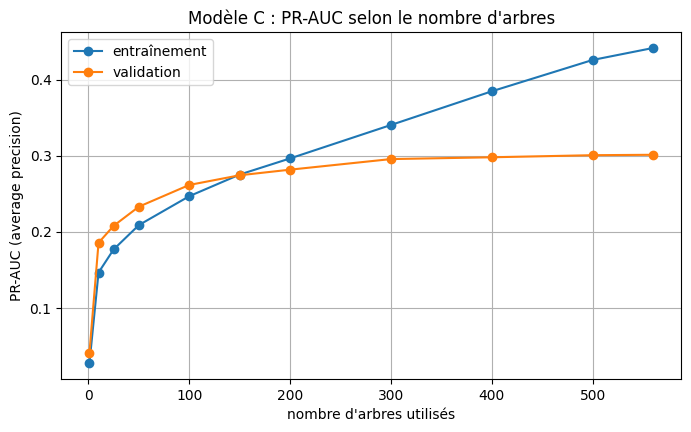


C, df et X inchangés : OK | le test n'a pas été lu | durée totale 2.3 min


In [30]:
# Cellule 27 — Contrôle 1 : écart ENTRAÎNEMENT / VALIDATION du modèle C, et courbe arbre par arbre
#
# Image : un élève qui a appris par cœur les corrigés a 19/20 sur les exercices déjà vus et 8/20 sur un sujet nouveau.
# L'écart entre les deux notes dit à quel point il a mémorisé au lieu de comprendre. Ici : la note de C sur l'entraînement
# (lignes déjà vues) contre sa note sur la validation (lignes plus récentes). Nom technique : écart de généralisation.
#
# CE QUI EST MESURÉ : la PR-AUC (average_precision_score de scikit-learn, la mesure du journal) de C sur l'entraînement et
# sur la validation, à 1, 10, 25, 50, 100, 150, 200, 300, 400, 500 et 560 arbres. C n'est PAS réentraîné : on relit le même
# modèle en n'utilisant que ses k premiers arbres (iteration_range=(0, k)).
#
# RÈGLE DE LECTURE : à choisir par Mehdi AVANT d'exécuter (ligne C1_REGLE ci-dessous), puis ne plus la changer.
#   A : « écart fort » si PR-AUC entraînement / PR-AUC validation > 2, à 560 arbres ; « écart modéré » sinon.
#   B : « écart fort » si (PR-AUC / taux d'illicites) entraînement ÷ (PR-AUC / taux d'illicites) validation > 2 ; « modéré » sinon.
#       (tient compte du fait que la validation contient proportionnellement plus d'illicites que l'entraînement)
#   C : aucun verdict : on décrit l'écart et la courbe, sans seuil.
#   Le seuil 2 est une convention [Hypothèse] : il n'existe pas de seuil universel.
# PRÉCISIONS NOTÉES AVANT LE RÉSULTAT :
#   a. « > 2 » est strict. Les deux rapports sont affichés ; seul celui de la règle choisie donne le verdict.
#   b. Entraînement et validation seulement : le test n'est ni lu ni découpé. `Is Laundering` sert à compter, jamais de variable.
#   c. INFORMATION SEULEMENT : C reste celui du journal (26 variables, 560 arbres, 0,3014, 0,3405). Aucun seuil d'alerte n'est choisi ici.
#   d. Contrôles stricts : sur 10 000 lignes puis sur toute la validation, la relecture à 560 arbres doit redonner les scores de
#      la cellule 22 (p_val_C) et la PR-AUC 0,3014 du journal. Sinon la cellule s'arrête.
#   e. Limites : la note d'entraînement est toujours flatteuse (le modèle a vu ces étiquettes) ; la note de validation l'est un peu
#      aussi (arrêt anticipé, seuil et familles choisis sur elle). Ce contrôle ne remplace pas le test.
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

C1_REGLE = "B"          # ← à remplacer par "A", "B" ou "C" AVANT d'exécuter, puis ne plus changer
C1_SEUIL = 2.0
C1_GRILLE = [1, 10, 25, 50, 100, 150, 200, 300, 400, 500, 560]
_c1_t0 = time.time()
assert C1_REGLE in ("A", "B", "C"), "Choisis la règle de lecture : écris C1_REGLE = \"A\", \"B\" ou \"C\" avant d'exécuter"

# ---------- 0) Prérequis et identité de C
_c1_objets = {"df": 1, "X": 9, "y": 9, "m": 9, "yv": 17, "VAR_C": 22, "mdl_c": 22, "p_val_C": 22, "r_c": 22}
_c1_manque = [f"{nom} → cellule {c}" for nom, c in _c1_objets.items() if nom not in globals()]
assert not _c1_manque, "Relancer d'abord (cellules 1 à 22, dans l'ordre) : " + " ; ".join(_c1_manque)
assert len(VAR_C) == 26 and len(set(VAR_C)) == 26 and "Is Laundering" not in VAR_C
assert (r_c["arbres"], round(float(r_c["val_PR-AUC"]), 4), round(float(r_c["val_F1@seuil"]), 4)) == (560, 0.3014, 0.3405), \
    "ce n'est pas le C du journal (arbres, PR-AUC, F1)"
assert mdl_c.best_iteration + 1 == 560, mdl_c.best_iteration
assert C1_GRILLE == sorted(C1_GRILLE) and C1_GRILLE[-1] == 560 and C1_GRILLE[0] >= 1
_c1_cols_df, _c1_cols_X = list(df.columns), list(X.columns)
print("prérequis et identité de C : OK | règle de lecture choisie :", C1_REGLE)


# ---------- 1) Fonctions
def c1_mesures(y_vrai, scores):
    """PR-AUC (average precision), taux d'illicites et « lift » = PR-AUC / taux d'illicites (1 = classement au hasard)."""
    y_vrai = np.asarray(y_vrai).astype(int)
    scores = np.asarray(scores, dtype=float)
    assert len(y_vrai) == len(scores) and len(y_vrai) > 0, "longueurs différentes ou tableau vide"
    assert set(np.unique(y_vrai)) <= {0, 1} and y_vrai.sum() > 0, "il faut des étiquettes 0/1 et au moins un illicite"
    ap = float(average_precision_score(y_vrai, scores))
    taux = float(y_vrai.mean())
    return {"pr_auc": ap, "taux": taux, "lift": ap / taux}


def c1_rapports(ap_ent, taux_ent, ap_val, taux_val):
    """Rapport des PR-AUC (règle A) et rapport des lifts (règle B), entraînement ÷ validation."""
    assert min(ap_ent, taux_ent, ap_val, taux_val) > 0, "toutes les valeurs doivent être > 0"
    return ap_ent / ap_val, (ap_ent / taux_ent) / (ap_val / taux_val)


def c1_lecture(regle, ap_ent, taux_ent, ap_val, taux_val, seuil=C1_SEUIL):
    """Verdict selon la règle choisie. A : rapport des PR-AUC > seuil. B : rapport des lifts > seuil. C : aucun verdict."""
    assert regle in ("A", "B", "C"), regle
    if regle == "C":
        return "description seule (aucun verdict)"
    r_a, r_b = c1_rapports(ap_ent, taux_ent, ap_val, taux_val)
    return "écart fort" if (r_a if regle == "A" else r_b) > seuil else "écart modéré"


# ---------- 2) Tests jouets, calculés à la main AVANT de toucher aux vraies données
# 2a) mesures : étiquettes [1, 0, 1, 0, 0], scores [0.9, 0.8, 0.1, 0.7, 0.2].
#     classement : 0,9 (illicite) ; 0,8 ; 0,7 ; 0,2 ; 0,1 (illicite). 1er illicite au rang 1 : précision 1/1.
#     2e illicite au rang 5 : précision 2/5. PR-AUC = (1 + 0,4) / 2 = 0,7. Taux = 2/5 = 0,4. Lift = 0,7 / 0,4 = 1,75.
_c1_j = c1_mesures([1, 0, 1, 0, 0], [0.9, 0.8, 0.1, 0.7, 0.2])
assert abs(_c1_j["pr_auc"] - 0.7) < 1e-12 and abs(_c1_j["taux"] - 0.4) < 1e-12 and abs(_c1_j["lift"] - 1.75) < 1e-12, _c1_j
# 2b) rapports : PR-AUC 0,6 (taux 0,001) à l'entraînement, 0,3 (taux 0,002) en validation.
#     rapport des PR-AUC = 0,6 / 0,3 = 2 ; lifts = 600 et 150 ; rapport des lifts = 4.
_c1_ra, _c1_rb = c1_rapports(0.6, 0.001, 0.3, 0.002)
assert abs(_c1_ra - 2.0) < 1e-9 and abs(_c1_rb - 4.0) < 1e-9, (_c1_ra, _c1_rb)
# 2c) verdicts sur ce même cas : A → 2 n'est pas > 2 → modéré ; B → 4 > 2 → fort ; C → aucun verdict
assert c1_lecture("A", 0.6, 0.001, 0.3, 0.002) == "écart modéré"
assert c1_lecture("B", 0.6, 0.001, 0.3, 0.002) == "écart fort"
assert c1_lecture("C", 0.6, 0.001, 0.3, 0.002) == "description seule (aucun verdict)"
assert c1_lecture("A", 0.9, 0.001, 0.3, 0.001) == "écart fort"          # 3 > 2
assert c1_lecture("B", 0.5, 0.001, 0.3, 0.001) == "écart modéré"        # 1,67 n'est pas > 2
for _c1_mauvais in [([0, 0, 0], [0.1, 0.2, 0.3]), ([1, 0], [0.5])]:      # aucun illicite ; longueurs différentes
    try:
        c1_mesures(*_c1_mauvais)
        raise RuntimeError("c1_mesures aurait dû refuser cette entrée")
    except AssertionError:
        pass
print("tests jouets (PR-AUC, taux, lift, rapports, verdicts, refus) : OK")

# ---------- 3) Les vraies données : ENTRAÎNEMENT et VALIDATION seulement
C1_X_ENT = X.loc[m["train"], VAR_C]
C1_X_VAL = X.loc[m["val"], VAR_C]
_c1_y_ent = y[m["train"]].to_numpy()
assert (len(C1_X_ENT), len(C1_X_VAL)) == (3_046_861, 1_015_602), (len(C1_X_ENT), len(C1_X_VAL))     # journal du 30/10
assert (int(_c1_y_ent.sum()), int(yv.sum())) == (2_297, 1_082), (int(_c1_y_ent.sum()), int(yv.sum()))
assert len(p_val_C) == len(C1_X_VAL) == len(yv)


def c1_scores(tableau, k):
    """Scores de C en n'utilisant que ses k premiers arbres. Ne modifie pas le modèle."""
    return mdl_c.predict_proba(tableau, iteration_range=(0, int(k)))[:, 1]


# ---------- 4) Essai sur un petit échantillon : la relecture redonne-t-elle les scores de la cellule 22 ?
_c1_petit = C1_X_VAL.head(10_000)
assert np.allclose(mdl_c.predict_proba(_c1_petit)[:, 1], p_val_C[:10_000], atol=1e-6), \
    "la prédiction par défaut ne redonne pas p_val_C sur 10 000 lignes"
assert np.allclose(c1_scores(_c1_petit, 560), p_val_C[:10_000], atol=1e-6), \
    "iteration_range=(0, 560) ne redonne pas p_val_C sur 10 000 lignes"
assert not np.allclose(c1_scores(_c1_petit, 10), p_val_C[:10_000], atol=1e-6), "10 arbres donnent les mêmes scores que 560 ?"
print("essai sur 10 000 lignes de validation (relecture à 560 arbres = scores de la cellule 22) : OK")

# ---------- 5) Calcul complet, arbre par arbre
_c1_lignes = []
for _c1_k in C1_GRILLE:
    _c1_d = time.time()
    _c1_pe, _c1_pv = c1_scores(C1_X_ENT, _c1_k), c1_scores(C1_X_VAL, _c1_k)
    _c1_me, _c1_mv = c1_mesures(_c1_y_ent, _c1_pe), c1_mesures(yv, _c1_pv)
    if _c1_k == 560:
        assert np.allclose(_c1_pv, p_val_C, atol=1e-6), "à 560 arbres, les scores de validation diffèrent de la cellule 22"
        assert abs(_c1_mv["pr_auc"] - r_c["val_PR-AUC"]) < 1e-6, (_c1_mv["pr_auc"], r_c["val_PR-AUC"])
    _c1_ra, _c1_rb = c1_rapports(_c1_me["pr_auc"], _c1_me["taux"], _c1_mv["pr_auc"], _c1_mv["taux"])
    _c1_lignes.append({"arbres": _c1_k, "PR-AUC_entrainement": _c1_me["pr_auc"], "PR-AUC_validation": _c1_mv["pr_auc"],
                       "ecart": _c1_me["pr_auc"] - _c1_mv["pr_auc"], "rapport_PR-AUC": _c1_ra,
                       "lift_entrainement": _c1_me["lift"], "lift_validation": _c1_mv["lift"], "rapport_lifts": _c1_rb,
                       "secondes": round(time.time() - _c1_d)})
    print(f"  {_c1_k:>3} arbres : entraînement {_c1_me['pr_auc']:.4f} | validation {_c1_mv['pr_auc']:.4f} ({_c1_lignes[-1]['secondes']} s)")
TAB_COURBE = pd.DataFrame(_c1_lignes)
print("contrôle à 560 arbres (scores et PR-AUC de validation = cellule 22, journal 0,3014) : OK")

print(f"\nCONTRÔLE 1 — PR-AUC de C, entraînement contre validation | taux d'illicites : entraînement {_c1_me['taux']:.4%}, "
      f"validation {_c1_mv['taux']:.4%}")
print(TAB_COURBE.round(4).to_string(index=False))

_c1_fin = TAB_COURBE.iloc[-1]
assert int(_c1_fin["arbres"]) == 560
print(f"\nÀ 560 arbres : PR-AUC entraînement {_c1_fin['PR-AUC_entrainement']:.4f} | validation {_c1_fin['PR-AUC_validation']:.4f} | "
      f"écart {_c1_fin['ecart']:+.4f}")
print(f"rapport des PR-AUC (règle A) : {_c1_fin['rapport_PR-AUC']:.2f} | rapport des lifts (règle B) : {_c1_fin['rapport_lifts']:.2f} | seuil {C1_SEUIL:g}")
print(f"LECTURE SELON LA RÈGLE {C1_REGLE} : "
      + c1_lecture(C1_REGLE, _c1_me["pr_auc"], _c1_me["taux"], _c1_mv["pr_auc"], _c1_mv["taux"]))
_c1_i = int(TAB_COURBE["PR-AUC_validation"].to_numpy().argmax())
print(f"[information] sur cette grille, la validation est la plus haute à {int(TAB_COURBE.loc[_c1_i, 'arbres'])} arbres "
      f"({TAB_COURBE.loc[_c1_i, 'PR-AUC_validation']:.4f})")
print("Information seulement : C reste celui du journal, rien n'est réentraîné ni modifié. Ce contrôle ne remplace pas le test.")

# ---------- 6) La courbe
plt.figure(figsize=(8, 4.5))
plt.plot(TAB_COURBE["arbres"], TAB_COURBE["PR-AUC_entrainement"], marker="o", label="entraînement")
plt.plot(TAB_COURBE["arbres"], TAB_COURBE["PR-AUC_validation"], marker="o", label="validation")
plt.xlabel("nombre d'arbres utilisés")
plt.ylabel("PR-AUC (average precision)")
plt.title("Modèle C : PR-AUC selon le nombre d'arbres")
plt.legend()
plt.grid(True)
plt.show()

# ---------- 7) Garde-fou : rien n'a changé, le test n'a pas été lu
del C1_X_ENT, C1_X_VAL, _c1_pe, _c1_pv, _c1_petit
assert mdl_c.best_iteration + 1 == 560
assert list(df.columns) == _c1_cols_df and list(X.columns) == _c1_cols_X, "df ou X a changé : ce n'est pas prévu"
print(f"\nC, df et X inchangés : OK | le test n'a pas été lu | durée totale {(time.time() - _c1_t0) / 60:.1f} min")

In [31]:
# Cellule 28 — Contrôle 4 : taux d'illicites par paquet de chaque variable (ENTRAÎNEMENT seulement)
#
# Image : on range les virements du plus petit au plus grand selon UNE variable, on coupe en paquets, et on regarde dans quel
# paquet le blanchiment se concentre. Lift d'un paquet = son taux d'illicites ÷ le taux global (1 = comme la moyenne ;
# 3 = trois fois plus de blanchiment que la moyenne ; 0,5 = deux fois moins).
#
# DÉCOUPAGE ET RÈGLE, CHOISIS LE 13/11/2026 À 00:53, AVANT D'AVOIR VU LA SORTIE :
#  Découpage : valeur vide → paquet « vide » ; colonne de catégories → un paquet par catégorie ; colonne numérique à 10 valeurs
#    distinctes ou moins → un paquet par valeur ; sinon, si plus de 10 % des valeurs renseignées valent 0 → un paquet « = 0 »
#    puis le reste en 9 paquets de même taille au plus ; sinon 10 paquets de même taille (moins si des valeurs se répètent).
#  Règle à trois niveaux, sur les paquets d'au moins 30 000 virements :
#    « signal fort »    si un paquet a un lift ≥ 3 ou ≤ 1/3 ;
#    « signal visible » si un paquet a un lift ≥ 2 ou ≤ 1/2 ;
#    « rien de net »    sinon ; « non lisible » si aucun paquet n'atteint 30 000 virements.
#  Les seuils 2, 3 et 30 000 sont des conventions [Hypothèse].
# PRÉCISIONS NOTÉES AVANT LE RÉSULTAT :
#  a. ENTRAÎNEMENT seulement : ni la validation ni le test ne sont lus. `Is Laundering` sert à compter, jamais de variable.
#  b. `heure` (24 valeurs) est découpée en paquets de même taille, pas heure par heure.
#  c. « au moins » est inclusif : lift 2,0 → visible ; lift 3,0 → fort.
#  d. La colonne « attendus » = illicites qu'aurait le paquet au taux global : en dessous d'une vingtaine, le lift est fragile.
#  e. INFORMATION SEULEMENT : C reste celui du journal. Mesure à UNE variable à la fois : elle ne dit pas ce qu'un modèle
#     apprend des combinaisons de variables, et « rien de net » ne veut pas dire « inutile ».
import time
import numpy as np
import pandas as pd

_c4_t0 = time.time()
C4_N_PAQUETS, C4_PART_ZERO, C4_N_MIN, C4_FORT, C4_VISIBLE = 10, 0.10, 30_000, 3.0, 2.0

# ---------- 0) Prérequis et identité de C
_c4_objets = {"df": 1, "X": 9, "y": 9, "m": 9, "VAR_C": 22, "r_c": 22}
_c4_manque = [f"{nom} → cellule {c}" for nom, c in _c4_objets.items() if nom not in globals()]
assert not _c4_manque, "Relancer d'abord (cellules 1 à 22, dans l'ordre) : " + " ; ".join(_c4_manque)
assert len(VAR_C) == 26 and len(set(VAR_C)) == 26 and "Is Laundering" not in VAR_C
assert (r_c["arbres"], round(float(r_c["val_PR-AUC"]), 4), round(float(r_c["val_F1@seuil"]), 4)) == (560, 0.3014, 0.3405), \
    "ce n'est pas le C du journal (arbres, PR-AUC, F1)"
_c4_cols_df, _c4_cols_X = list(df.columns), list(X.columns)
print("prérequis et identité de C : OK")


# ---------- 1) Fonctions
def c4_etiquettes(x, n_paquets=C4_N_PAQUETS, part_zero=C4_PART_ZERO):
    """Range chaque valeur dans un paquet. Renvoie (étiquettes, une par ligne ; ordre d'affichage des paquets)."""
    x = pd.Series(x).reset_index(drop=True)
    etiq = pd.Series("vide", index=x.index, dtype=object)
    present = x.notna()
    ordre = []
    if isinstance(x.dtype, pd.CategoricalDtype):                       # catégories : un paquet par catégorie
        vals = x[present].astype(str)
        etiq[present] = vals
        ordre = sorted(vals.unique())
    else:
        v = x[present].astype(float)
        if v.nunique() <= n_paquets:                                   # peu de valeurs : un paquet par valeur
            etiq[present] = v.map(lambda z: f"= {z:g}")
            ordre = [f"= {z:g}" for z in sorted(v.unique())]
        else:
            zero = v == 0
            if zero.mean() > part_zero:                                # beaucoup de zéros : un paquet « = 0 », puis le reste
                etiq[zero[zero].index] = "= 0"
                ordre.append("= 0")
                reste, q = v[~zero], n_paquets - 1
            else:
                reste, q = v, n_paquets
            if reste.nunique() <= q:
                etiq[reste.index] = reste.map(lambda z: f"= {z:g}")
                ordre += [f"= {z:g}" for z in sorted(reste.unique())]
            else:
                coupe = pd.qcut(reste, q, duplicates="drop")           # paquets de même taille ; moins si valeurs répétées
                etiq[reste.index] = coupe.astype(str)
                ordre += [str(c) for c in coupe.cat.categories]
    if (~present).any():
        ordre.append("vide")
    assert len(ordre) == len(set(ordre)), f"deux paquets portent le même nom : {ordre}"
    return etiq, ordre


def c4_taux_par_paquet(x, y_vrai, n_paquets=C4_N_PAQUETS):
    """Une ligne par paquet : n, illicites, attendus (au taux global), taux en %, lift = taux du paquet / taux global."""
    y_vrai = pd.Series(np.asarray(y_vrai).astype(int))
    assert len(y_vrai) == len(x), "x et y n'ont pas la même longueur"
    assert set(y_vrai.unique()) <= {0, 1} and y_vrai.sum() > 0, "il faut des étiquettes 0/1 et au moins un illicite"
    etiq, ordre = c4_etiquettes(x, n_paquets)
    tab = y_vrai.groupby(etiq.to_numpy()).agg(n="size", illicites="sum").reindex(ordre)
    assert tab.notna().all().all(), "un paquet annoncé est vide"
    tab = tab.astype("int64")
    assert tab["n"].sum() == len(y_vrai) and tab["illicites"].sum() == y_vrai.sum(), "les paquets ne recouvrent pas toutes les lignes"
    base = y_vrai.mean()
    tab["attendus"] = tab["n"] * base
    tab["taux_%"] = 100.0 * tab["illicites"] / tab["n"]
    tab["lift"] = (tab["illicites"] / tab["n"]) / base
    return tab


def c4_lecture(tab, n_min=C4_N_MIN, fort=C4_FORT, visible=C4_VISIBLE):
    """Règle à trois niveaux, sur les seuls paquets d'au moins n_min lignes."""
    grands = tab[tab["n"] >= n_min]
    if len(grands) == 0:
        return "non lisible"
    haut, bas = float(grands["lift"].max()), float(grands["lift"].min())
    if haut >= fort or bas <= 1.0 / fort:
        return "signal fort"
    if haut >= visible or bas <= 1.0 / visible:
        return "signal visible"
    return "rien de net"


# ---------- 2) Tests jouets, calculés à la main AVANT de toucher aux vraies données
# 2a) valeurs variées : 1 à 10, illicites aux valeurs 8, 9, 10 ; 5 paquets de 2 → {1,2} {3,4} {5,6} {7,8} {9,10}.
#     illicites [0, 0, 0, 1, 2] ; taux global 0,3 ; lift [0, 0, 0, 0,5/0,3, 1/0,3].
_c4_j = c4_taux_par_paquet(list(range(1, 11)), [0, 0, 0, 0, 0, 0, 0, 1, 1, 1], n_paquets=5)
assert _c4_j["n"].tolist() == [2, 2, 2, 2, 2] and _c4_j["illicites"].tolist() == [0, 0, 0, 1, 2], _c4_j
assert np.allclose(_c4_j["lift"], [0, 0, 0, 0.5 / 0.3, 1.0 / 0.3]) and np.allclose(_c4_j["attendus"], [0.6] * 5)
# 2b) catégories avec une valeur vide : a = lignes 0, 1, 5 (1 illicite) ; b = lignes 2, 4 (0) ; vide = ligne 3 (1 illicite).
#     taux global 2/6 ; lift a = (1/3)/(1/3) = 1 ; b = 0 ; vide = 1/(1/3) = 3.
_c4_j = c4_taux_par_paquet(pd.Categorical(["a", "a", "b", None, "b", "a"], categories=["a", "b"]), [1, 0, 0, 1, 0, 0])
assert list(_c4_j.index) == ["a", "b", "vide"] and _c4_j["n"].tolist() == [3, 2, 1] and _c4_j["illicites"].tolist() == [1, 0, 1], _c4_j
assert np.allclose(_c4_j["lift"], [1.0, 0.0, 3.0])
# 2c) variable 0/1 : valeur 0 = lignes 0, 1, 5 (0 illicite) ; valeur 1 = lignes 2, 3, 4 (2 illicites) ; lift 0 et (2/3)/(1/3) = 2.
_c4_j = c4_taux_par_paquet([0, 0, 1, 1, 1, 0], [0, 0, 1, 1, 0, 0])
assert list(_c4_j.index) == ["= 0", "= 1"] and _c4_j["illicites"].tolist() == [0, 2] and np.allclose(_c4_j["lift"], [0.0, 2.0]), _c4_j
# 2d) beaucoup de zéros (4 sur 10), 3 paquets demandés : « = 0 » (4 lignes, 1 illicite), puis le reste 1..6 en 2 paquets
#     {1,2,3} (0 illicite) et {4,5,6} (2 illicites).
_c4_j = c4_taux_par_paquet([0, 0, 0, 0, 1, 2, 3, 4, 5, 6], [0, 0, 0, 1, 0, 0, 0, 1, 1, 0], n_paquets=3)
assert _c4_j.index[0] == "= 0" and _c4_j["n"].tolist() == [4, 3, 3] and _c4_j["illicites"].tolist() == [1, 0, 2], _c4_j
# 2e) valeurs vides dans une colonne de nombres : 1 (illicite), vide, 2, vide (illicite) → « = 1 », « = 2 », « vide » en dernier.
_c4_j = c4_taux_par_paquet([1.0, np.nan, 2.0, np.nan], [1, 0, 0, 1])
assert list(_c4_j.index) == ["= 1", "= 2", "vide"] and _c4_j["n"].tolist() == [1, 1, 2] and _c4_j["illicites"].tolist() == [1, 0, 1], _c4_j
# 2f) valeurs répétées : sept fois 1, puis 2, 3, 4, 5 ; 3 paquets demandés. Les deux premières coupures tombent sur 1 :
#     il ne reste que 2 paquets, {les sept 1} et {2, 3, 4, 5} ; illicites aux valeurs 4 et 5 → [0, 2].
_c4_j = c4_taux_par_paquet([1, 1, 1, 1, 1, 1, 1, 2, 3, 4, 5], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1], n_paquets=3)
assert _c4_j["n"].tolist() == [7, 4] and _c4_j["illicites"].tolist() == [0, 2], _c4_j
# 2g) règle de lecture (paquets de 50 000 lignes sauf mention)
def _c4_tab(lifts, n=None):
    return pd.DataFrame({"n": n or [50_000] * len(lifts), "lift": lifts})
assert c4_lecture(_c4_tab([1.0, 3.0])) == "signal fort"              # 3,0 : « au moins 3 » est inclusif
assert c4_lecture(_c4_tab([1.0, 0.3])) == "signal fort"              # 0,3 ≤ 1/3
assert c4_lecture(_c4_tab([1.0, 2.0])) == "signal visible"           # 2,0 : inclusif
assert c4_lecture(_c4_tab([1.0, 2.9])) == "signal visible"
assert c4_lecture(_c4_tab([1.0, 0.5])) == "signal visible"           # 0,5 ≤ 1/2
assert c4_lecture(_c4_tab([1.2, 0.8])) == "rien de net"
assert c4_lecture(_c4_tab([1.1, 10.0], n=[50_000, 29_999])) == "rien de net"      # le gros lift est dans un paquet trop petit
assert c4_lecture(_c4_tab([5.0, 0.1], n=[100, 200])) == "non lisible"
print("tests jouets (6 découpages, règle à trois niveaux) : OK")

# ---------- 3) Les vraies données : ENTRAÎNEMENT seulement
C4_X_ENT = X.loc[m["train"], VAR_C]
_c4_y = y[m["train"]].to_numpy()
assert len(C4_X_ENT) == 3_046_861 and int(_c4_y.sum()) == 2_297, (len(C4_X_ENT), int(_c4_y.sum()))     # journal du 30/10
_c4_base = _c4_y.mean()

# ---------- 4) Essai sur un petit échantillon : 200 000 premières lignes, une variable de chaque sorte
for _c4_col in ["devise_payee", "montant_paye_log", "nb_retours_24h"]:
    _c4_e = c4_taux_par_paquet(C4_X_ENT[_c4_col].head(200_000), _c4_y[:200_000])
    assert _c4_e["n"].sum() == 200_000 and _c4_e["illicites"].sum() == int(_c4_y[:200_000].sum()), _c4_col
print("essai sur 200 000 lignes (catégories, valeurs variées, beaucoup de zéros) : OK")

# ---------- 5) Calcul complet : un tableau par variable
C4_TABLES, _c4_resume = {}, []
print(f"\nCONTRÔLE 4 — entraînement : {len(C4_X_ENT):,} virements, {int(_c4_y.sum()):,} illicites, taux global {_c4_base:.4%}")
for _c4_col in VAR_C:
    _c4_tab_col = c4_taux_par_paquet(C4_X_ENT[_c4_col], _c4_y)
    C4_TABLES[_c4_col] = _c4_tab_col
    _c4_lect = c4_lecture(_c4_tab_col)
    _c4_g = _c4_tab_col[_c4_tab_col["n"] >= C4_N_MIN]
    _c4_resume.append({"variable": _c4_col, "paquets": len(_c4_tab_col), "paquets_lus": len(_c4_g),
                       "lift_max": float(_c4_g["lift"].max()) if len(_c4_g) else np.nan,
                       "lift_min": float(_c4_g["lift"].min()) if len(_c4_g) else np.nan, "lecture": _c4_lect})
    print(f"\n--- {_c4_col} → {_c4_lect}")
    print(_c4_tab_col.round({"attendus": 1, "taux_%": 4, "lift": 2}).to_string())

# ---------- 6) Résumé
TAB_SIGNAUX = pd.DataFrame(_c4_resume)
assert len(TAB_SIGNAUX) == 26
print("\nRÉSUMÉ — règle à trois niveaux (paquets d'au moins 30 000 virements ; lift max et min parmi ces paquets)")
print(TAB_SIGNAUX.round(2).to_string(index=False))
print("\nnombre de variables par lecture :", TAB_SIGNAUX["lecture"].value_counts().to_dict())
print("Information seulement : C reste celui du journal. Une variable à la fois : « rien de net » ne veut pas dire « inutile ».")

# ---------- 7) Garde-fou : rien n'a changé, ni la validation ni le test n'ont été lus
del C4_X_ENT
assert list(df.columns) == _c4_cols_df and list(X.columns) == _c4_cols_X, "df ou X a changé : ce n'est pas prévu"
print(f"\ndf et X inchangés : OK | validation et test non lus | durée totale {(time.time() - _c4_t0) / 60:.1f} min")

prérequis et identité de C : OK
tests jouets (6 découpages, règle à trois niveaux) : OK
essai sur 200 000 lignes (catégories, valeurs variées, beaucoup de zéros) : OK

CONTRÔLE 4 — entraînement : 3,046,861 virements, 2,297 illicites, taux global 0.0754%

--- montant_paye_log → signal fort
                         n  illicites  attendus  taux_%  lift
(-0.000999, 3.021]  304790         37     229.8  0.0121  0.16
(3.021, 4.659]      304586         40     229.6  0.0131  0.17
(4.659, 5.614]      304692         81     229.7  0.0266  0.35
(5.614, 6.503]      304682        115     229.7  0.0377  0.50
(6.503, 7.333]      304684        182     229.7  0.0597  0.79
(7.333, 8.125]      304684        332     229.7  0.1090  1.45
(8.125, 9.052]      304685        457     229.7  0.1500  1.99
(9.052, 10.144]     304688        581     229.7  0.1907  2.53
(10.144, 12.048]    304688        248     229.7  0.0814  1.08
(12.048, 27.163]    304682        224     229.7  0.0735  0.98

--- montant_recu_log → sign

## Contrôle 3 — rappel et précision sur 500, 1 000 et 5 000 alertes (validation)

**Question.** Si un analyste ne peut ouvrir que 500, 1 000 ou 5 000 dossiers, quelle part du blanchiment le modèle C lui met-il sous les yeux, et combien de ces dossiers sont de vrais cas ? Le modèle B sert de comparaison.

**Ce que je mesure.** Rappel (part des illicites retrouvés), précision (part de vrais cas parmi les alertes) et lift (précision ÷ taux d'illicites). Quand plusieurs virements ont le même score à la coupure, j'affiche aussi le pire et le meilleur cas.

**Règle de lecture** (décidée le 13/11/2026 à 01:04, avant d'avoir vu la sortie) : mode descriptif, sans seuil ni verdict.

**Limites.** Ces chiffres sont mesurés sur la validation, qui a servi à régler le modèle C : ils sont flatteurs. La barre définitive sera mesurée sur le test. Le contrôle ne dit pas quels cas sont trouvés, seulement combien. Il ne lit ni l'entraînement ni le test et ne modifie rien.

**Résultat :** [à remplir après lecture]

In [33]:
# Cellule 29 — Contrôle 3 : rappel et précision de C et de B sur 500, 1 000 et 5 000 alertes (VALIDATION)
#
# Image : un analyste n'a le temps d'ouvrir que 1 000 dossiers. On lui donne les 1 000 virements les mieux notés par le modèle.
#   Rappel = part de tout le blanchiment qui se trouve dans ces 1 000 dossiers.
#   Précision = part de ces 1 000 dossiers qui est vraiment du blanchiment.
#   Lift = précision ÷ taux d'illicites (combien de fois mieux qu'un tirage au hasard).
#
# MODE DESCRIPTIF, DÉCIDÉ LE 13/11/2026 À 01:04, AVANT D'AVOIR VU LA SORTIE : aucun seuil, aucun verdict. C et B côte à côte.
# PRÉCISIONS NOTÉES AVANT LE RÉSULTAT :
#  a. VALIDATION seulement : ni l'entraînement ni le test ne sont lus. `Is Laundering` sert à compter.
#  b. Quand plusieurs virements ont le même score à la coupure, on ne peut pas tous les prendre. Le chiffre principal suit la
#     convention du journal (fonction rappel_budget, cellule 8 : à score égal, l'ordre des lignes). On affiche aussi le PIRE cas
#     (les places restantes vont d'abord aux légitimes) et le MEILLEUR cas (d'abord aux illicites).
#  c. Aucun nouveau seuil n'est choisi. Recoupement strict : au seuil de validation de C, 287 illicites alertés (cellule 23).
#  d. Ces chiffres sont mesurés sur la validation, qui a servi à régler C (arrêt, seuil, familles) : ils sont flatteurs pour C.
#     Ils servent de repère ; la barre définitive qu'un futur modèle devra battre sera celle du test.
#  e. INFORMATION SEULEMENT : C et B ne sont ni réentraînés ni modifiés.
import time
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

_c3_t0 = time.time()
C3_BUDGETS = [500, 1000, 5000]

# ---------- 0) Prérequis, identité de C et de B
_c3_objets = {"df": 1, "X": 9, "rappel_budget": 8, "yv": 17, "p_val_B": 17, "REF_AP_B": 17, "p_val_C": 22, "r_c": 22}
_c3_manque = [f"{nom} → cellule {c}" for nom, c in _c3_objets.items() if nom not in globals()]
assert not _c3_manque, "Relancer d'abord (cellules 1 à 22, dans l'ordre) : " + " ; ".join(_c3_manque)
assert (r_c["arbres"], round(float(r_c["val_PR-AUC"]), 4), round(float(r_c["val_F1@seuil"]), 4)) == (560, 0.3014, 0.3405), \
    "ce n'est pas le C du journal (arbres, PR-AUC, F1)"
assert len(yv) == len(p_val_C) == len(p_val_B) == 1_015_602 and int(yv.sum()) == 1_082, (len(yv), int(yv.sum()))
assert abs(average_precision_score(yv, p_val_C) - r_c["val_PR-AUC"]) < 1e-9
assert abs(average_precision_score(yv, p_val_B) - REF_AP_B) < 1e-9 and round(float(REF_AP_B), 4) == 0.1218
_c3_cols_df, _c3_cols_X = list(df.columns), list(X.columns)
print("prérequis, identité de C (0,3014) et de B (0,1218) : OK")


# ---------- 1) Fonction
def c3_au_budget(y_vrai, scores, budget):
    """Les `budget` virements les mieux notés : combien d'illicites dedans ?
    Renvoie le score à la coupure, le nombre d'ex-aequo à ce score, et les illicites trouvés selon trois conventions :
    ordre des lignes (celle du journal), pire cas, meilleur cas."""
    y_vrai = np.asarray(y_vrai).astype(int)
    scores = np.asarray(scores, dtype=float)
    assert len(y_vrai) == len(scores) and 1 <= budget <= len(scores), "budget hors limites ou longueurs différentes"
    assert set(np.unique(y_vrai)) <= {0, 1} and y_vrai.sum() > 0, "il faut des étiquettes 0/1 et au moins un illicite"
    ordre = np.argsort(-scores, kind="stable")
    coupure = float(scores[ordre[budget - 1]])
    dessus, egal = scores > coupure, scores == coupure
    n_dessus, vp_dessus = int(dessus.sum()), int(y_vrai[dessus].sum())
    n_egal, vp_egal = int(egal.sum()), int(y_vrai[egal].sum())
    places = budget - n_dessus                               # alertes à prendre parmi les ex-aequo
    assert 1 <= places <= n_egal, (places, n_egal)
    total = int(y_vrai.sum())
    vp_ordre = int(y_vrai[ordre[:budget]].sum())
    vp_pire = vp_dessus + max(0, places - (n_egal - vp_egal))
    vp_meilleur = vp_dessus + min(places, vp_egal)
    assert vp_pire <= vp_ordre <= vp_meilleur, (vp_pire, vp_ordre, vp_meilleur)
    return {"score_coupure": coupure, "ex_aequo": n_egal, "places": places, "illicites_trouves": vp_ordre,
            "rappel": vp_ordre / total, "precision": vp_ordre / budget, "lift": (vp_ordre / budget) / (total / len(y_vrai)),
            "rappel_pire": vp_pire / total, "rappel_meilleur": vp_meilleur / total,
            "precision_pire": vp_pire / budget, "precision_meilleur": vp_meilleur / budget}


# ---------- 2) Tests jouets, calculés à la main AVANT de toucher aux vraies données
# 2a) pas d'ex-aequo : étiquettes [1, 0, 1, 0, 0], scores [0.9, 0.8, 0.1, 0.7, 0.2], budget 2.
#     les 2 mieux notés : 0,9 (illicite) et 0,8 (légitime) → 1 illicite trouvé sur 2 au total.
#     rappel 1/2 ; précision 1/2 ; taux global 2/5 ; lift 0,5 / 0,4 = 1,25 ; pire = meilleur = 1/2.
_c3_j = c3_au_budget([1, 0, 1, 0, 0], [0.9, 0.8, 0.1, 0.7, 0.2], 2)
assert (_c3_j["illicites_trouves"], _c3_j["ex_aequo"], _c3_j["places"]) == (1, 1, 1), _c3_j
assert abs(_c3_j["rappel"] - 0.5) < 1e-12 and abs(_c3_j["precision"] - 0.5) < 1e-12 and abs(_c3_j["lift"] - 1.25) < 1e-12
assert _c3_j["rappel_pire"] == _c3_j["rappel_meilleur"] == 0.5
assert _c3_j["rappel"] == rappel_budget([1, 0, 1, 0, 0], [0.9, 0.8, 0.1, 0.7, 0.2], 2)        # même convention que la cellule 8
# 2b) ex-aequo à la coupure : étiquettes [1, 1, 0, 0, 1, 0], scores [0.9, 0.6, 0.6, 0.6, 0.6, 0.1], budget 3.
#     au-dessus de 0,6 : 1 virement (illicite). À 0,6 : 4 ex-aequo, dont 2 illicites. Il reste 2 places.
#     pire cas : les 2 places vont aux 2 légitimes → 1 illicite. Meilleur cas : aux 2 illicites → 3.
#     ordre des lignes : les deux premiers à 0,6 sont un illicite puis un légitime → 2.
#     3 illicites au total : rappel 2/3 (ordre), 1/3 (pire), 3/3 (meilleur) ; précision 2/3, 1/3, 3/3.
_c3_yj, _c3_pj = [1, 1, 0, 0, 1, 0], [0.9, 0.6, 0.6, 0.6, 0.6, 0.1]
_c3_j = c3_au_budget(_c3_yj, _c3_pj, 3)
assert (_c3_j["score_coupure"], _c3_j["ex_aequo"], _c3_j["places"], _c3_j["illicites_trouves"]) == (0.6, 4, 2, 2), _c3_j
assert abs(_c3_j["rappel"] - 2 / 3) < 1e-12 and abs(_c3_j["rappel_pire"] - 1 / 3) < 1e-12 and abs(_c3_j["rappel_meilleur"] - 1.0) < 1e-12
assert abs(_c3_j["precision_pire"] - 1 / 3) < 1e-12 and abs(_c3_j["precision_meilleur"] - 1.0) < 1e-12
assert _c3_j["rappel"] == rappel_budget(_c3_yj, _c3_pj, 3)
# 2c) budget = toutes les lignes : on trouve les 3 illicites, rappel 1, précision 3/6
_c3_j = c3_au_budget(_c3_yj, _c3_pj, 6)
assert _c3_j["illicites_trouves"] == 3 and _c3_j["rappel"] == 1.0 and abs(_c3_j["precision"] - 0.5) < 1e-12
# 2d) ce qui doit être refusé l'est bien : budget 0 ; budget plus grand que le nombre de lignes ; aucun illicite
for _c3_args in [(_c3_yj, _c3_pj, 0), (_c3_yj, _c3_pj, 7), ([0, 0, 0], [0.3, 0.2, 0.1], 2)]:
    try:
        c3_au_budget(*_c3_args)
        raise RuntimeError("c3_au_budget aurait dû refuser cette entrée")
    except AssertionError:
        pass
print("tests jouets (sans ex-aequo, avec ex-aequo, budget total, refus) : OK")

# ---------- 3) Essai sur un petit échantillon : 100 000 premières lignes de validation, 500 alertes
assert int(yv[:100_000].sum()) > 0, "aucun illicite dans les 100 000 premières lignes de validation"
_c3_e = c3_au_budget(yv[:100_000], p_val_C[:100_000], 500)
assert _c3_e["rappel"] == rappel_budget(yv[:100_000], p_val_C[:100_000], 500)
assert 0.0 <= _c3_e["rappel_pire"] <= _c3_e["rappel"] <= _c3_e["rappel_meilleur"] <= 1.0
print("essai sur 100 000 lignes (même résultat que rappel_budget, pire ≤ ordre ≤ meilleur) : OK")

# ---------- 4) Calcul complet : C et B, trois budgets
_c3_taux = float(yv.mean())
_c3_lignes = []
for _c3_nom, _c3_p in [("C", p_val_C), ("B", p_val_B)]:
    for _c3_b in C3_BUDGETS:
        _c3_r = c3_au_budget(yv, _c3_p, _c3_b)
        assert abs(_c3_r["rappel"] - rappel_budget(yv, _c3_p, _c3_b)) < 1e-12, (_c3_nom, _c3_b)     # convention du journal
        _c3_lignes.append({"modele": _c3_nom, "alertes": _c3_b, **_c3_r})
TAB_BUDGETS = pd.DataFrame(_c3_lignes)

print(f"\nCONTRÔLE 3 — VALIDATION : {len(yv):,} virements, {int(yv.sum()):,} illicites, taux {_c3_taux:.4%} "
      f"(au hasard : précision {_c3_taux:.4%}, lift 1)")
_c3_aff = TAB_BUDGETS[["modele", "alertes", "illicites_trouves", "rappel", "precision", "lift",
                       "score_coupure", "ex_aequo", "places", "rappel_pire", "rappel_meilleur"]].copy()
_c3_aff["precision"] = (100 * _c3_aff["precision"]).round(2).astype(str) + " %"
print(_c3_aff.round({"rappel": 4, "lift": 1, "score_coupure": 4, "rappel_pire": 4, "rappel_meilleur": 4}).to_string(index=False))

print("\nC contre B, même nombre d'alertes (illicites trouvés ; rappel) :")
for _c3_b in C3_BUDGETS:
    _c3_c = TAB_BUDGETS[(TAB_BUDGETS["modele"] == "C") & (TAB_BUDGETS["alertes"] == _c3_b)].iloc[0]
    _c3_bb = TAB_BUDGETS[(TAB_BUDGETS["modele"] == "B") & (TAB_BUDGETS["alertes"] == _c3_b)].iloc[0]
    print(f"  {_c3_b:>5} alertes : C {int(_c3_c['illicites_trouves'])} ({_c3_c['rappel']:.4f}) | "
          f"B {int(_c3_bb['illicites_trouves'])} ({_c3_bb['rappel']:.4f}) | écart de rappel {_c3_c['rappel'] - _c3_bb['rappel']:+.4f}")

# ---------- 5) Information : C à son seuil de validation (seuil existant, aucun nouveau seuil)
_c3_seuil = float(r_c["val_seuil"])
_c3_alertes = int((p_val_C >= _c3_seuil).sum())
_c3_vp = int((p_val_C[yv == 1] >= _c3_seuil).sum())
assert _c3_vp == 287, f"illicites alertés au seuil de C : {_c3_vp} (cellule 23 : 287)"
print(f"\n[information] C à son seuil de validation ({_c3_seuil:.4f}) : {_c3_alertes:,} alertes, {_c3_vp} illicites | "
      f"rappel {_c3_vp / int(yv.sum()):.4f} | précision {100 * _c3_vp / _c3_alertes:.2f} %")
print("Mode descriptif : aucun verdict. Chiffres de validation, flatteurs pour C ; la barre définitive sera celle du test.")

# ---------- 6) Garde-fou
assert list(df.columns) == _c3_cols_df and list(X.columns) == _c3_cols_X, "df ou X a changé : ce n'est pas prévu"
print(f"\ndf et X inchangés : OK | entraînement et test non lus | durée totale {time.time() - _c3_t0:.0f} s")

prérequis, identité de C (0,3014) et de B (0,1218) : OK
tests jouets (sans ex-aequo, avec ex-aequo, budget total, refus) : OK
essai sur 100 000 lignes (même résultat que rappel_budget, pire ≤ ordre ≤ meilleur) : OK

CONTRÔLE 3 — VALIDATION : 1,015,602 virements, 1,082 illicites, taux 0.1065% (au hasard : précision 0.1065%, lift 1)
modele  alertes  illicites_trouves  rappel precision  lift  score_coupure  ex_aequo  places  rappel_pire  rappel_meilleur
     C      500                266  0.2458    53.2 % 499.4         0.1157         1       1       0.2458           0.2458
     C     1000                332  0.3068    33.2 % 311.6         0.0617         1       1       0.3068           0.3068
     C     5000                551  0.5092   11.02 % 103.4         0.0189         1       1       0.5092           0.5092
     B      500                141  0.1303    28.2 % 264.7         0.0824         1       1       0.1303           0.1303
     B     1000                193  0.1784    19.3 % 181.

In [ ]:
# Cellule 30 — Contrôle 2 : le score de C tient-il sur CHAQUE MOITIÉ de la validation ?
#
# Image : on coupe la validation en deux, le début et la fin. Si la note de C tient sur les deux moitiés, elle tient dans le
# temps. Si elle chute sur la fin, C « vieillit mal ». Nom technique : stabilité temporelle.
#
# PLAN ÉCRIT LE 13/11/2026 À 01:11, AVANT D'AVOIR VU LA SORTIE. Toutes les variantes sont calculées, UNE SEULE donne le verdict :
#  ANALYSE PRINCIPALE (verdict officiel) : coupe à la minute médiane (autant de virements de chaque côté, à la minute près)
#    + règle B : « stable » si l'IC95 de l'écart de PR-AUC (moitié 2 − moitié 1) contient 0 ; « instable » sinon.
#    L'IC95 vient d'un bootstrap par bloc : on retire au sort des comptes émetteurs, 100 fois (comme en cellules 12 et 22).
#  ANALYSES DE SENSIBILITÉ (affichées pour voir si la conclusion est robuste ; elles ne changent pas le verdict) :
#    coupe au milieu du temps ; règle A (« stable » si |écart de PR-AUC| < 0,05, convention) ; écart de ROC-AUC.
# PRÉCISIONS NOTÉES AVANT LE RÉSULTAT :
#  a. VALIDATION seulement. `Is Laundering` sert à compter.
#  b. La PR-AUC dépend du taux d'illicites de chaque moitié : le taux et le lift (PR-AUC ÷ taux) sont affichés. La ROC-AUC
#     (probabilité qu'un illicite soit mieux noté qu'un légitime ; 0,5 = hasard) ne dépend pas de ce taux : elle sert ici de
#     mesure secondaire de stabilité. Elle ne remplace pas la PR-AUC comme mesure du projet.
#  c. Bootstrap : tirage des comptes sur TOUTE la validation (graine 0), puis recoupe en deux moitiés. Bornes non arrondies ;
#     « contient 0 » = borne basse ≤ 0 ≤ borne haute.
#  d. Rappel et précision au seuil de validation EXISTANT de C ; aucun nouveau seuil n'est choisi.
#  e. INFORMATION SEULEMENT : C n'est ni réentraîné ni modifié. Ce contrôle ne remplace pas le test.
import time
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

_c2_t0 = time.time()
C2_TIRAGES, C2_GRAINE, C2_SEUIL_A = 100, 0, 0.05

# ---------- 0) Prérequis et identité de C
_c2_objets = {"df": 1, "X": 9, "m": 9, "preparer_blocs": 12, "indices_bloc": 12, "yv": 17, "groupes_val": 17,
              "p_val_C": 22, "r_c": 22}
_c2_manque = [f"{nom} → cellule {c}" for nom, c in _c2_objets.items() if nom not in globals()]
assert not _c2_manque, "Relancer d'abord (cellules 1 à 22, dans l'ordre) : " + " ; ".join(_c2_manque)
assert (r_c["arbres"], round(float(r_c["val_PR-AUC"]), 4), round(float(r_c["val_F1@seuil"]), 4)) == (560, 0.3014, 0.3405), \
    "ce n'est pas le C du journal (arbres, PR-AUC, F1)"
_c2_t = df.loc[m["val"], "t_min"].to_numpy().astype(np.int64)
assert len(yv) == len(p_val_C) == len(_c2_t) == len(groupes_val) == 1_015_602 and int(yv.sum()) == 1_082
assert abs(average_precision_score(yv, p_val_C) - r_c["val_PR-AUC"]) < 1e-9
_c2_seuil = float(r_c["val_seuil"])
_c2_cols_df, _c2_cols_X = list(df.columns), list(X.columns)
print("prérequis et identité de C : OK")


# ---------- 1) Fonctions
def c2_premiere_moitie(minutes, mode):
    """Renvoie (masque de la 1re moitié, minute de coupure). La 1re moitié = minutes STRICTEMENT avant la coupure.
    mode « mediane » : coupure = minute de la ligne du milieu ; mode « temps » : coupure = milieu de la durée."""
    minutes = np.asarray(minutes, dtype=np.int64)
    assert len(minutes) >= 2 and mode in ("mediane", "temps"), mode
    if mode == "mediane":
        coupure = int(np.sort(minutes, kind="stable")[len(minutes) // 2])
    else:
        coupure = int(minutes.min()) + (int(minutes.max()) - int(minutes.min()) + 1) // 2
    return minutes < coupure, coupure


def c2_mesures(y_vrai, scores, seuil):
    """PR-AUC, taux d'illicites, lift, ROC-AUC, et rappel / précision quand on alerte si score >= seuil."""
    y_vrai = np.asarray(y_vrai).astype(int)
    scores = np.asarray(scores, dtype=float)
    assert len(y_vrai) == len(scores) and 0 < y_vrai.sum() < len(y_vrai), "il faut au moins un illicite et un légitime"
    ap, taux = float(average_precision_score(y_vrai, scores)), float(y_vrai.mean())
    alerte = scores >= seuil
    vp = int((alerte & (y_vrai == 1)).sum())
    return {"n": len(y_vrai), "illicites": int(y_vrai.sum()), "taux": taux, "pr_auc": ap, "lift": ap / taux,
            "roc_auc": float(roc_auc_score(y_vrai, scores)), "alertes": int(alerte.sum()),
            "rappel_seuil": vp / int(y_vrai.sum()), "precision_seuil": (vp / int(alerte.sum())) if alerte.any() else float("nan")}


def c2_lecture_A(ecart, seuil=C2_SEUIL_A):
    """Règle A : « stable » si l'écart de PR-AUC est strictement inférieur au seuil en valeur absolue."""
    return "stable" if abs(ecart) < seuil else "instable"


def c2_lecture_B(borne_basse, borne_haute):
    """Règle B : « stable » si l'intervalle contient 0 (borne basse ≤ 0 ≤ borne haute)."""
    return "stable" if borne_basse <= 0 <= borne_haute else "instable"


def c2_bootstrap(y_vrai, scores, premiere, groupes, n=C2_TIRAGES, graine=C2_GRAINE):
    """Écarts (moitié 2 − moitié 1) de PR-AUC et de ROC-AUC sur n tirages de comptes. Un tirage sans illicite ou sans
    légitime dans une moitié est sauté. Renvoie (écarts de PR-AUC, écarts de ROC-AUC)."""
    y_vrai, scores, premiere = np.asarray(y_vrai).astype(int), np.asarray(scores, dtype=float), np.asarray(premiere, dtype=bool)
    o, d, t = preparer_blocs(groupes)
    rng = np.random.default_rng(graine)
    d_ap, d_roc = [], []
    for _ in range(n):
        i = indices_bloc(o, d, t, rng.integers(0, len(t), len(t)))
        yb, pb, hb = y_vrai[i], scores[i], premiere[i]
        y1, y2 = yb[hb], yb[~hb]
        if not (0 < y1.sum() < len(y1) and 0 < y2.sum() < len(y2)):
            continue
        d_ap.append(average_precision_score(y2, pb[~hb]) - average_precision_score(y1, pb[hb]))
        d_roc.append(roc_auc_score(y2, pb[~hb]) - roc_auc_score(y1, pb[hb]))
    return np.array(d_ap), np.array(d_roc)


# ---------- 2) Tests jouets, calculés à la main AVANT de toucher aux vraies données
# 2a) coupe : minutes [0, 1, 2, 3, 4, 5, 6, 100].
#     médiane : ligne du milieu = 5e valeur triée = 4 → 1re moitié = {0, 1, 2, 3} (4 lignes), coupure 4.
#     temps : milieu = 0 + (100 − 0 + 1) // 2 = 50 → 1re moitié = les 7 lignes avant 50, coupure 50.
_c2_m, _c2_c = c2_premiere_moitie([0, 1, 2, 3, 4, 5, 6, 100], "mediane")
assert _c2_c == 4 and _c2_m.tolist() == [True] * 4 + [False] * 4
_c2_m, _c2_c = c2_premiere_moitie([0, 1, 2, 3, 4, 5, 6, 100], "temps")
assert _c2_c == 50 and _c2_m.tolist() == [True] * 7 + [False]
# 2b) mesures : étiquettes [1, 0, 1, 0, 0], scores [0.9, 0.8, 0.1, 0.7, 0.2], seuil 0,5.
#     PR-AUC = (1/1 + 2/5) / 2 = 0,7 ; taux 0,4 ; lift 1,75.
#     ROC-AUC : 2 illicites × 3 légitimes = 6 paires ; 0,9 bat les 3 légitimes, 0,1 n'en bat aucun → 3/6 = 0,5.
#     au seuil 0,5 : 3 alertes (0,9 ; 0,8 ; 0,7) dont 1 illicite → rappel 1/2, précision 1/3.
_c2_j = c2_mesures([1, 0, 1, 0, 0], [0.9, 0.8, 0.1, 0.7, 0.2], 0.5)
assert abs(_c2_j["pr_auc"] - 0.7) < 1e-12 and abs(_c2_j["lift"] - 1.75) < 1e-12 and abs(_c2_j["roc_auc"] - 0.5) < 1e-12, _c2_j
assert (_c2_j["n"], _c2_j["illicites"], _c2_j["alertes"]) == (5, 2, 3)
assert abs(_c2_j["rappel_seuil"] - 0.5) < 1e-12 and abs(_c2_j["precision_seuil"] - 1 / 3) < 1e-12
# 2c) règles de lecture
assert c2_lecture_A(0.049) == "stable" and c2_lecture_A(-0.049) == "stable"
assert c2_lecture_A(0.05) == "instable" and c2_lecture_A(-0.20) == "instable"            # 0,05 : « inférieur » est strict
assert c2_lecture_B(-0.01, 0.03) == "stable" and c2_lecture_B(0.0, 0.03) == "stable"     # une borne à 0 : l'intervalle contient 0
assert c2_lecture_B(0.01, 0.03) == "instable" and c2_lecture_B(-0.09, -0.02) == "instable"
# 2d) bootstrap : si le modèle classe parfaitement dans les deux moitiés, les deux PR-AUC et les deux ROC-AUC valent 1,
#     donc tous les écarts valent exactement 0, quel que soit le tirage.
_c2_yj = np.tile([1, 0, 0, 0], 50)                       # 200 lignes, 1 illicite sur 4
_c2_dap, _c2_droc = c2_bootstrap(_c2_yj, _c2_yj.astype(float), np.arange(200) < 100, np.arange(200) // 4, n=20)
assert len(_c2_dap) == 20 and np.all(_c2_dap == 0.0) and np.all(_c2_droc == 0.0), (_c2_dap, _c2_droc)
print("tests jouets (deux coupes, mesures, deux règles, bootstrap) : OK")

# ---------- 3) Essai sur les vraies données avec 3 tirages seulement : formes et valeurs plausibles
_c2_m_essai, _ = c2_premiere_moitie(_c2_t, "mediane")
_c2_e_ap, _c2_e_roc = c2_bootstrap(yv, p_val_C, _c2_m_essai, groupes_val, n=3)
assert len(_c2_e_ap) == len(_c2_e_roc) >= 1 and np.all(np.abs(_c2_e_ap) < 1) and np.all(np.abs(_c2_e_roc) < 1)
print("essai à 3 tirages sur la validation : OK")

# ---------- 4) Calcul complet : deux coupes
print(f"\nCONTRÔLE 2 — VALIDATION entière : PR-AUC {r_c['val_PR-AUC']:.4f} | seuil de C {_c2_seuil:.4f} | "
      f"minutes {int(_c2_t.min())} à {int(_c2_t.max())}")
C2_RESULTATS = {}
for _c2_mode, _c2_nom in [("mediane", "coupe à la minute médiane"), ("temps", "coupe au milieu du temps")]:
    _c2_d = time.time()
    _c2_h1, _c2_coupure = c2_premiere_moitie(_c2_t, _c2_mode)
    assert 0 < _c2_h1.sum() < len(_c2_h1)
    _c2_m1 = c2_mesures(yv[_c2_h1], p_val_C[_c2_h1], _c2_seuil)
    _c2_m2 = c2_mesures(yv[~_c2_h1], p_val_C[~_c2_h1], _c2_seuil)
    assert _c2_m1["n"] + _c2_m2["n"] == len(yv) and _c2_m1["illicites"] + _c2_m2["illicites"] == int(yv.sum())
    _c2_dap, _c2_droc = c2_bootstrap(yv, p_val_C, _c2_h1, groupes_val)
    _c2_ic_ap = (float(np.percentile(_c2_dap, 2.5)), float(np.percentile(_c2_dap, 97.5)))
    _c2_ic_roc = (float(np.percentile(_c2_droc, 2.5)), float(np.percentile(_c2_droc, 97.5)))
    _c2_ecart_ap, _c2_ecart_roc = _c2_m2["pr_auc"] - _c2_m1["pr_auc"], _c2_m2["roc_auc"] - _c2_m1["roc_auc"]
    C2_RESULTATS[_c2_mode] = {"coupure": _c2_coupure, "moitie_1": _c2_m1, "moitie_2": _c2_m2, "ecart_pr_auc": _c2_ecart_ap,
                              "ic_pr_auc": _c2_ic_ap, "ecart_roc_auc": _c2_ecart_roc, "ic_roc_auc": _c2_ic_roc,
                              "tirages": len(_c2_dap), "regle_A": c2_lecture_A(_c2_ecart_ap),
                              "regle_B": c2_lecture_B(*_c2_ic_ap), "regle_B_roc": c2_lecture_B(*_c2_ic_roc)}
    print(f"\n=== {_c2_nom} (coupure à la minute {_c2_coupure}, {time.time() - _c2_d:.0f} s) ===")
    _c2_tab = pd.DataFrame([{"moitie": "1 (début)", **_c2_m1}, {"moitie": "2 (fin)", **_c2_m2}])
    _c2_tab["taux_%"] = 100 * _c2_tab["taux"]
    print(_c2_tab[["moitie", "n", "illicites", "taux_%", "pr_auc", "lift", "roc_auc", "alertes", "rappel_seuil", "precision_seuil"]]
          .round({"taux_%": 4, "pr_auc": 4, "lift": 1, "roc_auc": 4, "rappel_seuil": 4, "precision_seuil": 4}).to_string(index=False))
    print(f"écart moitié 2 − moitié 1 : PR-AUC {_c2_ecart_ap:+.4f} [IC95 {_c2_ic_ap[0]:+.4f} ; {_c2_ic_ap[1]:+.4f}, {len(_c2_dap)} tirages] | "
          f"ROC-AUC {_c2_ecart_roc:+.4f} [IC95 {_c2_ic_roc[0]:+.4f} ; {_c2_ic_roc[1]:+.4f}]")
    print(f"règle B sur la PR-AUC : {C2_RESULTATS[_c2_mode]['regle_B']} | règle A : {C2_RESULTATS[_c2_mode]['regle_A']} | "
          f"règle B sur la ROC-AUC : {C2_RESULTATS[_c2_mode]['regle_B_roc']}")

# ---------- 5) Verdict officiel et sensibilité
_c2_p = C2_RESULTATS["mediane"]
print(f"\nANALYSE PRINCIPALE (coupe à la minute médiane, règle B sur la PR-AUC) : {_c2_p['regle_B']}")
_c2_lectures = [C2_RESULTATS[k][r] for k in ("mediane", "temps") for r in ("regle_A", "regle_B", "regle_B_roc")]
print("analyses de sensibilité (2 coupes × 3 lectures) :", {f"{k} / {r}": C2_RESULTATS[k][r]
                                                             for k in ("mediane", "temps") for r in ("regle_A", "regle_B", "regle_B_roc")})
print("les 6 lectures concordent :", len(set(_c2_lectures)) == 1)
print("Information seulement : C reste celui du journal. Ce contrôle ne remplace pas le test.")

# ---------- 6) Garde-fou
assert list(df.columns) == _c2_cols_df and list(X.columns) == _c2_cols_X, "df ou X a changé : ce n'est pas prévu"
print(f"\ndf et X inchangés : OK | entraînement et test non lus | durée totale {(time.time() - _c2_t0) / 60:.1f} min")

prérequis et identité de C : OK
tests jouets (deux coupes, mesures, deux règles, bootstrap) : OK
essai à 3 tirages sur la validation : OK

CONTRÔLE 2 — VALIDATION entière : PR-AUC 0.3014 | seuil de C 0.0929 | minutes 8016 à 11051

=== coupe à la minute médiane (coupure à la minute 9535, 40 s) ===
   moitie      n  illicites  taux_%  pr_auc  lift  roc_auc  alertes  rappel_seuil  precision_seuil
1 (début) 507788        559  0.1101  0.3189 289.6   0.9730      302        0.2791           0.5166
  2 (fin) 507814        523  0.1030  0.2814 273.2   0.9741      302        0.2505           0.4338
écart moitié 2 − moitié 1 : PR-AUC -0.0374 [IC95 -0.0839 ; +0.0072, 100 tirages] | ROC-AUC +0.0011 [IC95 -0.0035 ; +0.0054]
règle B sur la PR-AUC : stable | règle A : stable | règle B sur la ROC-AUC : stable


In [35]:
# Cellule 31 — Contrôle 6 : les variables de C changent-elles entre l'ENTRAÎNEMENT et la VALIDATION ?
#
# Image : deux photos de la même variable, une prise à l'entraînement, une en validation. On range les valeurs dans les mêmes
# paquets et on compare la part de virements de chaque paquet. Si les parts ont bougé, le modèle travaille sur un terrain qu'il
# n'a pas appris. Nom technique : dérive de distribution ; mesure : indice de stabilité de population (PSI).
#   PSI = somme, sur les paquets, de (part en validation − part à l'entraînement) × ln(part en validation ÷ part à l'entraînement).
#   0 = deux photos identiques ; plus c'est grand, plus la variable a bougé.
#
# PLAN DÉCIDÉ LE 13/11/2026 À 23:35, AVANT D'AVOIR VU LA SORTIE :
#  VERDICT OFFICIEL : PSI < 0,10 « stable » ; 0,10 ≤ PSI < 0,25 « à surveiller » ; PSI ≥ 0,25 « décalée ».
#    Ces seuils sont une convention d'usage [Connaissance], pas un théorème.
#  SENSIBILITÉ, SANS VERDICT : écart maximal entre les deux courbes cumulées (statistique de Kolmogorov-Smirnov, entre 0 et 1),
#    pour les variables numériques, sur les valeurs renseignées. Pas de valeur p : avec des millions de lignes elle dirait
#    toujours « différent ».
# PRÉCISIONS NOTÉES AVANT LE RÉSULTAT :
#  a. Paquets fixés sur l'ENTRAÎNEMENT, même principe que le contrôle 4 : « vide » ; un paquet par catégorie ; un paquet par valeur
#     s'il y a 10 valeurs distinctes ou moins ; sinon « = 0 » à part s'il y a plus de 10 % de zéros, et le reste en paquets de même
#     taille bornés par les quantiles de l'entraînement (fermés à droite, premier et dernier ouverts vers l'infini).
#  b. Une valeur de validation jamais vue à l'entraînement va dans un paquet « autre ».
#  c. Une part nulle est remplacée par 1e-6 (convention) ; un paquet vide des deux côtés est ignoré.
#  d. ENTRAÎNEMENT et VALIDATION seulement ; `Is Laundering` n'est pas utilisé ; le test n'est pas lu.
#  e. INFORMATION SEULEMENT : C reste celui du journal. Une variable « décalée » est notée pour la préparation du réseau de
#     neurones ; rien n'est retiré. Le PSI dit QU'une variable a bougé, pas si cela nuit au modèle.
import time
import numpy as np
import pandas as pd

_c6_t0 = time.time()
C6_N_PAQUETS, C6_PART_ZERO, C6_PLANCHER, C6_SEUIL_BAS, C6_SEUIL_HAUT = 10, 0.10, 1e-6, 0.10, 0.25

# ---------- 0) Prérequis et identité de C
_c6_objets = {"df": 1, "X": 9, "m": 9, "VAR_C": 22, "r_c": 22}
_c6_manque = [f"{nom} → cellule {c}" for nom, c in _c6_objets.items() if nom not in globals()]
assert not _c6_manque, "Relancer d'abord (cellules 1 à 22, dans l'ordre) : " + " ; ".join(_c6_manque)
assert len(VAR_C) == 26 and len(set(VAR_C)) == 26 and "Is Laundering" not in VAR_C
assert (r_c["arbres"], round(float(r_c["val_PR-AUC"]), 4), round(float(r_c["val_F1@seuil"]), 4)) == (560, 0.3014, 0.3405), \
    "ce n'est pas le C du journal (arbres, PR-AUC, F1)"
_c6_cols_df, _c6_cols_X = list(df.columns), list(X.columns)
print("prérequis et identité de C : OK")


# ---------- 1) Fonctions
def c6_regle(x_ent, n_paquets=C6_N_PAQUETS, part_zero=C6_PART_ZERO):
    """Fixe les paquets d'une variable à partir de l'ENTRAÎNEMENT seulement. Renvoie un dictionnaire qui décrit la règle."""
    x = pd.Series(x_ent).reset_index(drop=True)
    if isinstance(x.dtype, pd.CategoricalDtype):
        cats = sorted(x.dropna().astype(str).unique())
        return {"type": "categories", "valeurs": cats, "noms": cats + ["autre", "vide"]}
    v = x.dropna().astype(float).to_numpy()
    assert len(v) > 0, "aucune valeur renseignée à l'entraînement"
    distinctes = np.unique(v)
    if len(distinctes) <= n_paquets:
        return {"type": "valeurs", "valeurs": distinctes, "noms": [f"= {z:g}" for z in distinctes] + ["autre", "vide"]}
    zero = bool((v == 0).mean() > part_zero)
    reste, q = (v[v != 0], n_paquets - 1) if zero else (v, n_paquets)
    bords = np.unique(np.quantile(reste, np.linspace(0, 1, q + 1)))
    interieurs = bords[1:-1]
    if len(interieurs) == 0:
        noms = ["toutes les valeurs" + (" non nulles" if zero else "")]
    else:
        noms = ([f"≤ {interieurs[0]:g}"] + [f"({a:g}, {b:g}]" for a, b in zip(interieurs[:-1], interieurs[1:])]
                + [f"> {interieurs[-1]:g}"])
    return {"type": "quantiles", "zero": zero, "interieurs": interieurs, "noms": (["= 0"] if zero else []) + noms + ["vide"]}


def c6_codes(x, regle):
    """Numéro de paquet de chaque valeur, selon une règle fixée sur l'entraînement. Le dernier numéro est « vide »."""
    x = pd.Series(x).reset_index(drop=True)
    codes = np.full(len(x), len(regle["noms"]) - 1, dtype=np.int64)
    present = x.notna().to_numpy()
    if regle["type"] == "categories":
        carte = {c: i for i, c in enumerate(regle["valeurs"])}
        codes[present] = x[present].astype(str).map(carte).fillna(len(carte)).to_numpy().astype(np.int64)
    else:
        v = x[present].astype(float).to_numpy()
        if regle["type"] == "valeurs":
            vals = regle["valeurs"]
            pos = np.clip(np.searchsorted(vals, v), 0, len(vals) - 1)
            codes[present] = np.where(vals[pos] == v, pos, len(vals))
        else:
            dec = 1 if regle["zero"] else 0
            c = dec + np.searchsorted(regle["interieurs"], v, side="left")
            codes[present] = np.where(v == 0, 0, c) if regle["zero"] else c
    return codes


def c6_psi(n_ent, n_val, plancher=C6_PLANCHER):
    """Indice de stabilité de population à partir des effectifs par paquet (mêmes paquets des deux côtés)."""
    n_ent, n_val = np.asarray(n_ent, dtype=float), np.asarray(n_val, dtype=float)
    assert n_ent.shape == n_val.shape and n_ent.sum() > 0 and n_val.sum() > 0, "effectifs incohérents"
    garde = (n_ent + n_val) > 0
    p = np.maximum(n_ent[garde] / n_ent.sum(), plancher)
    q = np.maximum(n_val[garde] / n_val.sum(), plancher)
    return float(np.sum((q - p) * np.log(q / p)))


def c6_lecture(psi, bas=C6_SEUIL_BAS, haut=C6_SEUIL_HAUT):
    """Verdict officiel : < 0,10 stable ; de 0,10 à moins de 0,25 à surveiller ; 0,25 et plus décalée."""
    return "stable" if psi < bas else ("à surveiller" if psi < haut else "décalée")


def c6_ks(a, b):
    """Écart maximal entre les deux courbes cumulées (statistique de Kolmogorov-Smirnov), entre 0 et 1."""
    a, b = np.sort(np.asarray(a, dtype=float)), np.sort(np.asarray(b, dtype=float))
    assert len(a) > 0 and len(b) > 0, "un des deux échantillons est vide"
    points = np.concatenate([a, b])
    fa = np.searchsorted(a, points, side="right") / len(a)
    fb = np.searchsorted(b, points, side="right") / len(b)
    return float(np.max(np.abs(fa - fb)))


# ---------- 2) Tests jouets, calculés à la main AVANT de toucher aux vraies données
# 2a) paquets de même taille : entraînement = 1 à 20, 4 paquets → bornes 5,75 ; 10,5 ; 15,25 → {1..5} {6..10} {11..15} {16..20}.
#     validation [0, 3, 6, 6, 100, vide] → paquets 0, 0, 1, 1, 3, « vide » (numéro 4) ; 0 et 100 sortent de la plage : premier et dernier paquets.
_c6_r = c6_regle(list(range(1, 21)), n_paquets=4)
assert _c6_r["type"] == "quantiles" and not _c6_r["zero"] and np.allclose(_c6_r["interieurs"], [5.75, 10.5, 15.25]), _c6_r
assert np.bincount(c6_codes(list(range(1, 21)), _c6_r), minlength=5).tolist() == [5, 5, 5, 5, 0]
assert c6_codes([0, 3, 6, 6, 100, np.nan], _c6_r).tolist() == [0, 0, 1, 1, 3, 4]
# 2b) beaucoup de zéros : cinq 0 puis 1 à 15 (25 % de zéros), 4 paquets → « = 0 », puis le reste en 3 : {1..5} {6..10} {11..15}.
#     validation [0, 0, 7, 20] → paquets 0, 0, 2, 3.
_c6_r = c6_regle([0] * 5 + list(range(1, 16)), n_paquets=4)
assert _c6_r["zero"] and _c6_r["noms"][0] == "= 0" and len(_c6_r["noms"]) == 5, _c6_r
assert np.bincount(c6_codes([0] * 5 + list(range(1, 16)), _c6_r), minlength=5).tolist() == [5, 5, 5, 5, 0]
assert c6_codes([0, 0, 7, 20], _c6_r).tolist() == [0, 0, 2, 3]
# 2c) peu de valeurs : entraînement [0, 1, 1, 0] → paquets « = 0 », « = 1 », « autre », « vide ».
#     validation [1, 2, vide] → 1, « autre » (2 n'a jamais été vu), « vide ».
_c6_r = c6_regle([0, 1, 1, 0])
assert _c6_r["noms"] == ["= 0", "= 1", "autre", "vide"] and c6_codes([1, 2, np.nan], _c6_r).tolist() == [1, 2, 3], _c6_r
# 2d) catégories : entraînement [a, b, a] ; validation [b, c, vide] → 1, « autre » (c jamais vu), « vide ».
_c6_r = c6_regle(pd.Categorical(["a", "b", "a"]))
assert _c6_r["noms"] == ["a", "b", "autre", "vide"], _c6_r
assert c6_codes(pd.Categorical(["b", "c", None], categories=["a", "b", "c"]), _c6_r).tolist() == [1, 2, 3]
# 2e) PSI : parts [0,5 ; 0,5] contre [0,5 ; 0,5] → 0.
#     parts [0,5 ; 0,5] contre [0,25 ; 0,75] → (−0,25) × ln(0,5) + (0,25) × ln(1,5) = 0,25 × ln(3) = 0,274653…
#     le PSI est symétrique : échanger les deux côtés donne la même valeur.
assert c6_psi([50, 50], [500, 500]) == 0.0
assert abs(c6_psi([50, 50], [25, 75]) - 0.25 * np.log(3)) < 1e-12
assert abs(c6_psi([50, 50], [25, 75]) - c6_psi([25, 75], [50, 50])) < 1e-12
assert c6_psi([100, 0], [50, 50]) > 1.0                       # un paquet absent d'un côté : très grand, mais fini
assert c6_psi([10, 0, 10], [10, 0, 10]) == 0.0                # paquet vide des deux côtés : ignoré
# 2f) verdicts
assert c6_lecture(0.0999) == "stable" and c6_lecture(0.10) == "à surveiller"
assert c6_lecture(0.2499) == "à surveiller" and c6_lecture(0.25) == "décalée"
# 2g) écart maximal entre courbes cumulées : [1, 2, 3, 4] contre [3, 4, 5, 6].
#     à la valeur 2 : la moitié du premier est passée, rien du second → écart 0,5 ; c'est le maximum.
assert abs(c6_ks([1, 2, 3, 4], [3, 4, 5, 6]) - 0.5) < 1e-12
assert c6_ks([1, 2, 3], [1, 2, 3]) == 0.0 and c6_ks([1, 2], [3, 4]) == 1.0
print("tests jouets (4 découpages, PSI, verdicts, écart maximal) : OK")

# ---------- 3) Les vraies données : ENTRAÎNEMENT et VALIDATION seulement
C6_X_ENT = X.loc[m["train"], VAR_C]
C6_X_VAL = X.loc[m["val"], VAR_C]
assert (len(C6_X_ENT), len(C6_X_VAL)) == (3_046_861, 1_015_602), (len(C6_X_ENT), len(C6_X_VAL))     # journal du 30/10

# ---------- 4) Essai sur un petit échantillon : 200 000 lignes de chaque période, une variable de chaque sorte
for _c6_col in ["devise_payee", "montant_paye_log", "nb_retours_24h", "delai_reception_envoi_min"]:
    _c6_r = c6_regle(C6_X_ENT[_c6_col].head(200_000))
    _c6_k = len(_c6_r["noms"])
    _c6_ne = np.bincount(c6_codes(C6_X_ENT[_c6_col].head(200_000), _c6_r), minlength=_c6_k)
    _c6_nv = np.bincount(c6_codes(C6_X_VAL[_c6_col].head(200_000), _c6_r), minlength=_c6_k)
    assert _c6_ne.sum() == 200_000 and _c6_nv.sum() == 200_000 and len(_c6_ne) == len(_c6_nv) == _c6_k, _c6_col
    assert np.isfinite(c6_psi(_c6_ne, _c6_nv)) and c6_psi(_c6_ne, _c6_nv) >= 0, _c6_col
print("essai sur 200 000 lignes par période (4 sortes de variables) : OK")

# ---------- 5) Calcul complet
C6_DETAILS, _c6_resume = {}, []
for _c6_col in VAR_C:
    _c6_r = c6_regle(C6_X_ENT[_c6_col])
    _c6_k = len(_c6_r["noms"])
    _c6_ne = np.bincount(c6_codes(C6_X_ENT[_c6_col], _c6_r), minlength=_c6_k)
    _c6_nv = np.bincount(c6_codes(C6_X_VAL[_c6_col], _c6_r), minlength=_c6_k)
    assert _c6_ne.sum() == len(C6_X_ENT) and _c6_nv.sum() == len(C6_X_VAL) and len(_c6_ne) == len(_c6_nv) == _c6_k, _c6_col
    _c6_p = c6_psi(_c6_ne, _c6_nv)
    _c6_tab = pd.DataFrame({"n_entrainement": _c6_ne, "n_validation": _c6_nv}, index=_c6_r["noms"])
    _c6_tab = _c6_tab[(_c6_tab["n_entrainement"] + _c6_tab["n_validation"]) > 0]
    _c6_tab["entrainement_%"] = 100.0 * _c6_tab["n_entrainement"] / len(C6_X_ENT)
    _c6_tab["validation_%"] = 100.0 * _c6_tab["n_validation"] / len(C6_X_VAL)
    _c6_tab["ecart_points"] = _c6_tab["validation_%"] - _c6_tab["entrainement_%"]
    C6_DETAILS[_c6_col] = _c6_tab
    if _c6_r["type"] == "categories":
        _c6_d = np.nan
    else:
        _c6_d = c6_ks(C6_X_ENT[_c6_col].dropna().to_numpy(), C6_X_VAL[_c6_col].dropna().to_numpy())
    _c6_resume.append({"variable": _c6_col, "decoupage": _c6_r["type"], "paquets": len(_c6_tab), "PSI": _c6_p,
                       "lecture": c6_lecture(_c6_p), "ecart_max_cumule": _c6_d})
TAB_DERIVE = pd.DataFrame(_c6_resume).sort_values("PSI", ascending=False, kind="stable").reset_index(drop=True)
assert len(TAB_DERIVE) == 26

# recoupement strict avec la cellule 26 : valeurs vides du délai depuis la dernière réception
_c6_vide = C6_DETAILS["delai_reception_envoi_min"].loc["vide"]
assert (int(_c6_vide["n_entrainement"]), int(_c6_vide["n_validation"])) == (981_440, 89_772), _c6_vide.to_dict()
print("recoupement avec la cellule 26 (valeurs vides du délai : 981 440 et 89 772) : OK")

print(f"\nCONTRÔLE 6 — dérive des 26 variables (entraînement : {len(C6_X_ENT):,} ; validation : {len(C6_X_VAL):,}), triées par PSI")
print(TAB_DERIVE.round({"PSI": 4, "ecart_max_cumule": 4}).to_string(index=False))
print("\nnombre de variables par lecture :", TAB_DERIVE["lecture"].value_counts().to_dict())

# ---------- 6) Détail par paquet des variables non « stables » : où la répartition a-t-elle bougé ?
_c6_bougent = TAB_DERIVE.loc[TAB_DERIVE["lecture"] != "stable", "variable"].tolist()
for _c6_col in _c6_bougent:
    print(f"\n--- {_c6_col} (PSI {TAB_DERIVE.loc[TAB_DERIVE['variable'] == _c6_col, 'PSI'].iloc[0]:.4f})")
    print(C6_DETAILS[_c6_col].round(2).to_string())
if not _c6_bougent:
    print("\naucune variable « à surveiller » ni « décalée » : pas de détail par paquet à afficher")
print("\nInformation seulement : C reste celui du journal. Le PSI dit qu'une variable a bougé, pas si cela nuit au modèle.")

# ---------- 7) Garde-fou
del C6_X_ENT, C6_X_VAL
assert list(df.columns) == _c6_cols_df and list(X.columns) == _c6_cols_X, "df ou X a changé : ce n'est pas prévu"
print(f"\ndf et X inchangés : OK | étiquettes et test non lus | durée totale {(time.time() - _c6_t0) / 60:.1f} min")

prérequis et identité de C : OK
tests jouets (4 découpages, PSI, verdicts, écart maximal) : OK
essai sur 200 000 lignes par période (4 sortes de variables) : OK
recoupement avec la cellule 26 (valeurs vides du délai : 981 440 et 89 772) : OK

CONTRÔLE 6 — dérive des 26 variables (entraînement : 3,046,861 ; validation : 1,015,602), triées par PSI
                         variable  decoupage  paquets    PSI      lecture  ecart_max_cumule
                  format_paiement categories        7 1.9187      décalée               NaN
             eventail_sortant_72h  quantiles        7 0.7595      décalée            0.1433
       montant_sur_moyenne_passee  quantiles       11 0.7430      décalée            0.0553
                   envoye_24h_log  quantiles       10 0.7411      décalée            0.1638
             eventail_sortant_24h  quantiles        6 0.7353      décalée            0.1620
        delai_reception_envoi_min  quantiles       11 0.6641      décalée            0.2334
        